# Trader Workflow

<https://github.com/seamusrobertmurphy/swing-trader>

This is a consolidated handover that states what each stage does, why it is built that way, and how to run it, and it carries the key code and figures from three notebooks so a new reader can pick up the repository and continue the search. Three-notebook pipeline includes 01 Trader Metrics, 02 Trader Controls, 03 Trader Execution that are implemented in spot crypto trading on Binance. The single question this pipeline exists to answer is whether there is a rule the model can trade that clears transaction fees on data it has never seen.


## Contents

**0. Overview** 
- 0.1 After-Fee Objective
- 0.2 Pipeline Overview
- 0.3 Data Frames
- 0.4 Hard Rules
- 0.5 Running It

**1. Trader Metrics**
- 1.1 Environment Setup
- 1.2 Rank Universe
- 1.3 Performance Metrics
- 1.4 Entry Points
- 1.5 Exit Points
- 1.6 Decision Checklist

**2. Trader Controls** 
- 2.1 Key Variables
- 2.2 Volatility Filter
- 2.3 Four-Gate Screen
- 2.4 Edge Sizing
- 2.5 Hold Period
- 2.6 Stacked Defences
- 2.7 Signal Journal
- 2.8 Frozen Harness

**3. Trader Execution** *(drafted)*
- 3.1 Data Preparation
- 3.2 Feature Variables
- 3.3 Entries Exits
- 3.4 Sharpening Entries
- 3.5 Survivorship Pipeline
- 3.6 Variable Selection
- 3.7 Training Regime
- 3.8 Model Tuning
- 3.9 Model Assessment
- 3.10 Stability
- 3.11 Edge Diagnostics
- 3.12 Regime Conditioning
- 3.13 Edge Levers

**4. Shared Method**

**5. Findings**
- 5.1 Current State
- 5.2 The Lead
- 5.3 Next Steps

**Appendices**
- A. File Map
- B. Glossary
- C. Environment
- D. Committee Layer


## 0. Overview

### 0.1 After-Fee Evaluation

The goal is one trading strategy that makes money after fees on data it has never seen. Every stage in these three notebooks serves that test, and nothing is accepted without passing it.

A candidate is scored on a blind final year that is held out from all training and tuning. It must clear three bars at once: beat a coin flip at the real base rate, beat buy and hold, and return more than zero per trade after the round-trip fee of about 0.20 percent. A rule that ranks trades well but still loses to the fee is a NO-GO. The fee is the adversary, not the market.

The search runs across three decision frames so intraday, interday, and longer holding each get a fair test. A frame is a whole system: its own bars, its own label, its own features, scored on its own out-of-sample. The frames are compared, never pooled, because a five-minute label and a four-hour label do not mean the same thing.

### 0.2 Pipeline Overview

The work splits into three notebooks that run in order. Each hands a clean input to the next.

| Notebook | Role | The question it answers | Key outputs |
| --- | --- | --- | --- |
| **01 Trader Metrics** | Signal layer | What is worth measuring on a coin | indicators, entry and exit signals, a ranked shortlist, the decision checklist |
| **02 Trader Controls** | Risk and rules layer | What the account is allowed to do | position caps, stops, the daily loss circuit, the fee model, the four-gate screen, position sizing |
| **03 Trader Execution** | Modeling and search layer | Whether a tradeable edge survives fees | the datasets, the features, the model, and the after-fee scoreboard that returns GO or NO-GO |

Metrics defines the vocabulary of signals. Controls sets the boundaries any strategy must live inside, above all the fee and the loss limits. Execution builds the datasets and the model and runs the honest test. The controls are not a step bolted on at the end. They are the filter the whole search is judged against.

### 0.3 Data Frames

Each frame is built from the same Binance Vision archives into its own dataset, `dataset_5m_allmarket`, `dataset_1h_allmarket`, `dataset_4h_allmarket`, and `dataset_1d_allmarket`, all stored as Parquet. One builder serves all three and retunes its feature windows, its label horizon, and its liquidity and volatility screens to the frame.

| Frame | Bar | Trade style it targets | Default label |
| --- | --- | --- | --- |
| **5m** | 5 minutes | intraday scalps | a shorter ATR barrier, roughly two hours |
| **1h** | 1 hour | day-to-day swings | +2 / -1 ATR triple barrier, two wall-clock days |
| **4h** | 4 hours | multi-day holds | +2 / -1 ATR triple barrier, two wall-clock days |
| **1d** | 1 day | position swings, the fee-count lever | +2 / -1 ATR triple barrier, two daily bars |

The higher-timeframe context shifts with the frame, so a five-minute model still sees the one-hour and four-hour trend, a one-hour model sees the four-hour and daily trend, and a four-hour model sees the daily and weekly trend. That is how each frame gets multi-resolution information without the datasets ever being merged. Every modelling section in Part 3 runs this same 1h, 4h, 5m loop and reports one block per frame. The 1d frame was added 2026-08-17 as the fee-count lever: the survivorship-complete daily archive (669 pairs) is on disk and its baseline dataset and edge matrix are section 3.13's first read.

### 0.4 Hard Rules

Every candidate strategy lives inside a fixed set of controls, summarised here and detailed in Part 2. None is negotiable, and the after-fee test in the last row overrides any in-sample result. The rows marked *revised* carry the adjustments logged below; the rest are unchanged from the charter.

| Control | Setting | Why |
| --- | --- | --- |
| Position cap | 5 percent of equity at entry | one bad name cannot sink the book |
| Default size | half Kelly, a quarter on minimum signals | size to the edge, not the conviction |
| Fat-pitch exception | one position to 10 percent, with reward-to-risk at least 3:1, a named cause, and a written exit | rare, documented, reversible |
| Label geometry | longer-horizon, less fee-punishing triple barrier, replacing the +2 / -1 ATR default | the old label lost before any prediction; fewer round trips cut fee drag |
| Hard stop | ATR-scaled per frame, provisional, replacing the fixed 7 percent | trend protection sized to each coin's volatility, not a flat percent |
| Trailing stop | ATR-scaled per frame, provisional, replacing the fixed 10 percent | lets winners run scaled to volatility; settled by the exit-geometry sweep |
| Regime gate | act only when BTC is trending up | deploys the real but drowned cross-sectional signal in the regime where it works |
| Narrow book | entries only in coins that carried the out-of-sample gated edge and pass the live liquidity screen | a minority of coins carry all the profit; the average hides it |
| Fee tier | maker entries, BNB-discounted fees, measured from the account each run | the achievable 0.15 percent round trip closes half the gap to zero |
| Daily circuit | halt new orders if rolling 24-hour drawdown passes 3 percent | stop the bleeding, existing stops stay live |
| Drawdown ramp | below a 5 percent rolling-week loss, cut new size with each further 1 percent | shrink the book, do not just block it |
| Cash floor | keep at least 10 percent in cash | always able to act |
| Position limit | at most 3 new positions per week | forces selectivity |
| Direction | spot only, never short, never margin, never leverage | the mandate; shorting is logged below as research, not policy |
| Averaging down | never | a loser is exited or held, not fed |
| Anchoring | cost basis never enters hold or sell logic | decide on forward value only |
| The bar | nothing ships unless it beats a coin flip, buy-and-hold, and the fee out of sample | the fee is the adversary |

**Adjustments logged.** Six changes were made to release model potential without adding ruin risk. All are bounded and stay inside the no-short mandate. They are documented here as the intended design; the code-level work lands in Part 3 (the label, exit, and regime sections) and has not yet been rebuilt into the on-disk datasets.

1. **Exit geometry.** The fixed 7 percent hard stop and 10 percent trailing stop become ATR-scaled per frame and stay provisional until the exit-geometry sweep, which fits per-coin trailing stops and a time-decaying take-profit and scores them after fees. The flat percent ignored each coin's volatility and conflicted with the code's existing 5 percent and roughly 8.5 percent ATR stops.
2. **Label.** The default +2 / -1 ATR triple barrier is replaced by a longer-horizon, less fee-punishing geometry with fewer round trips. The old label had negative unconditional expectancy, a base rate near 0.313 against a breakeven near 0.333, so it lost before the model predicted anything.
3. **Regime gate** Deploy the cross-sectional signal only when BTC is trending up. Relative strength is real and broad but drowned by a negative universe baseline, and a regime filter is the cheapest in-mandate way to test whether it turns positive.
4. **Longer-horizon frame.** Extend the search toward the daily frame alongside 4h, because coarser frames cut the fee count per unit of return, which is the central obstacle. As of 2026-08-17 the daily archive is complete and the baseline build is in flight (3.13).
5. **Fee engineering (2026-08-17).** The modelled cost gains a second, achievable scenario: post-only maker entries (no spread paid), BNB-discounted 0.075 percent per side, a 0.15 percent round trip (`ACHIEVABLE_COST_PCT` in `inputs/train_model.py`). The live wrapper reads the account's actual maker and taker rates and BNB-burn setting at the start of every run (`fee_status`) and warns when the measured round trip exceeds the scenario; the paper book charges the same engineered rate.
6. **Narrow book (2026-08-17).** `inputs/narrow_book.py` intersects the coins that carried the out-of-sample gated edge (positive contribution, at least three cohort appearances) with the live liquidity screen and writes `memory/narrow-book.json`; `inputs/trade_binance.py` refuses entries outside it. Rank broadly, trade narrowly.

**Unchanged and kept tight.** The 5 percent position cap, half-Kelly sizing, the 3 percent daily circuit, the drawdown ramp, the 10 percent cash floor, the three-new-per-week cap, no averaging down, no anchoring, and the after-fee bar. These bound survival, not the search. Loosening them would amplify a model that is still at the coin-flip floor, which is how no edge becomes ruin.

**Open question on shorting.** Going long the strong third and short the weak third would monetize the cross-sectional spread directly, even against a negative baseline. It is left out because it breaks the spot-only mandate and imports unbounded loss and liquidation risk. If ever tested, it should be small, market-neutral, unleveraged, and paper-first, still behind the after-fee bar.

### 0.5 Running It

The notebooks run on a MacPorts Python through a project `.venv` kernel. Secrets live in the run environment, never in the repository: the Binance and Alpaca keys, `BINANCE_TESTNET`, and the single money switch `LIVE_TRADING`, which stays false until a strategy has earned the right to trade. No real order is placed while it is false; the agent reads the market or runs against the Binance testnet.

One knob drives the modelling cells. `LOAD_FRAME` selects the active frame, 1h by default. Import Data loads that frame's Parquet into `df` and `feat`, and every modelling cell consumes those two. The multi-frame sections in Part 3, model assessment, stability, edge diagnostics, selectivity, and regime conditioning, loop over 1h, 4h, and 5m on their own and restore the active frame when they finish, so the rest of the notebook is unaffected.

Run order is top to bottom. The code cells carried into this document have their outputs cleared, so run them on the Mac with the `.venv` kernel to regenerate every figure and table. One environment caveat: the repository sits on an exFAT volume that scatters `._` AppleDouble files, which can crash matplotlib; clear them if an import throws a `0xb0` decode error.

## 1. Trader Metrics

The signal layer, from `01-trader-metrics`. A read-only daily scan over public market data, no keys and no orders, sharing Part 3's data spine: price from the survivorship-complete `data.binance.vision` 1h archives resampled to daily, and the universe from Part 3's point-in-time Stage B screen.

The sections below present the signal families the model in Part 3 actually ranks and trades on, cross-sectional relative strength, the momentum family including MACD, the Supertrend and BTC-relative trend signals, the ATR-scaled exits, and the regime state, each tied to the feature it becomes and the evidence for it. The runnable daily indicator board is kept throughout as an illustrative within-coin read, a place to eyeball candidates, not a trade trigger. Any signal must clear the after-fee, out-of-sample bar in Part 3 before it means anything, and on the 1h frame the verdict so far is NO-GO.

### 1.1 Environment Setup

The scan runs on Python 3.11 with dependencies pinned in `inputs/requirements.txt` and reinstalled on each fresh kernel: `pandas-ta-classic` for indicators, `pykalman` for smoothing, `plotly` and `matplotlib` for charts. No exchange login or API key is needed, because both the price history and the universe come from Part 3's offline archives through `build_dataset_1h`. `ccxt` is kept only for an optional live top-up of the still-forming day.

Provenance is proven, not asserted. Price comes from the official `data.binance.vision` monthly per-symbol OHLCV zips, exchange-direct and checksummed, covering every USDT pair ever listed including delisted ones. That survivorship-complete source is what removes the universe-level bias the old live top-N-by-volume scan carried. The second cell pulls one month of BTCUSDT bars straight from the archive at 1h, 4h, and 5m to show the source and format.

In [1]:
import sys, subprocess
from pathlib import Path

# assign Python kernel,
REQUIRED_PY = (3, 11)
if sys.version_info[:2] < REQUIRED_PY: raise RuntimeError(
        f"This notebook needs Python {REQUIRED_PY[0]}.{REQUIRED_PY[1]} or newer, "
        f"but the kernel is {sys.version.split()[0]}. Switch to a 3.11+ kernel and re-run.")

# Install only the libraries THIS notebook imports that are missing from the active kernel. The
# consolidated notebook runs on one venv that must carry both the ch1/ch2 scan libraries and the ch3
# model libraries; installing the full ../03-inputs/requirements.txt on top of that mix trips a numpy/numba
# resolver conflict and can leave pandas-ta-classic uninstalled, so a targeted install is used instead.
import importlib.util
_need = {"numpy": "numpy", "pandas": "pandas", "ccxt": "ccxt", "plotly": "plotly",
         "pandas_ta_classic": "pandas-ta-classic", "pykalman": "pykalman"}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing missing packages:", ", ".join(_missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "--break-system-packages",
                    "--disable-pip-version-check", *_missing], check=True)

# import package modules and naming
import warnings, numpy as np, pandas as pd
pd.set_option("display.notebook_repr_html", False)  # IDE-safe: render DataFrames as text, not HTML
from datetime import datetime
import ccxt
import pandas_ta_classic as ta
from pykalman import KalmanFilter
import plotly, plotly.graph_objects as go, plotly.io as pio
warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+notebook_connected"  

# quick sanity check
print(f"Environment ready  ·  python {sys.version.split()[0]}  ({sys.executable})")
print(f"  ccxt {ccxt.__version__} · pandas {pd.__version__} · "
      f"numpy {np.__version__} · plotly {plotly.__version__}")

Environment ready  ·  python 3.12.13  (/Volumes/PortableSSD/Github/day-trader/.venv/bin/python)
  ccxt 4.5.59 · pandas 2.3.3 · numpy 2.2.6 · plotly 6.8.0


In [2]:
# Demo: how each frame is downloaded, and from where. Every frame sources the SAME official Binance
# public archive at data.binance.vision -- monthly per-symbol OHLCV kline zips, one file per interval,
# exchange-direct and checksummed (NOT a live API). ccxt is only a live top-up for the bar still
# forming. This cell pulls one month at 1h, 4h and 5m to prove the source and format; the full pull is
# the commands in the table.
import io, zipfile, urllib.request, pandas as pd
BINANCE_VISION = "https://data.binance.vision/"
def vision_url(symbol, interval, month):
    return f"{BINANCE_VISION}data/spot/monthly/klines/{symbol}/{interval}/{symbol}-{interval}-{month}.zip"

provenance = pd.DataFrame([
    ("1h  (old)", "acquire_vision.py download --interval 1h", "klines_1h/<SYM>/", "dataset_1h_allmarket.parquet"),
    ("1d  (old)", "flow_data.py --interval 1d --all-market",  "klines/<SYM>/",    "daily_flow.csv"),
    ("4h  (new)", "acquire_vision.py download --interval 4h", "klines_4h/<SYM>/", "dataset_4h_allmarket.parquet"),
    ("5m  (new)", "acquire_vision.py download --interval 5m --symbols <scalp set>", "klines_5m/<SYM>/", "dataset_5m_allmarket.parquet"),
], columns=["frame", "download command", "raw klines on disk", "built dataset"])
print("Survivorship-complete: acquire_vision.py crawl enumerates EVERY symbol ever listed (incl.")
print("delisted), so dead coins are not silently dropped the way the exchangeInfo path is.\n")
print(provenance.to_string(index=False))

print("\nLIVE proof of source + format (one month of BTCUSDT, straight from the archive):")
for interval in ("1h", "4h", "5m"):
    u = vision_url("BTCUSDT", interval, "2024-01")
    try:
        raw = urllib.request.urlopen(u, timeout=15).read()
        z = zipfile.ZipFile(io.BytesIO(raw))
        bars = pd.read_csv(io.BytesIO(z.read(z.namelist()[0])), header=None).iloc[:, :6]
        bars.columns = ["open_time", "open", "high", "low", "close", "volume"]
        print(f"  {interval:3s}: {len(bars):5d} bars, {len(raw)/1024:5.0f} KB  <-  {u}")
    except Exception as e:
        print(f"  {interval:3s}: offline ({e}); full archive lives under inputs/binance-data/klines_{interval}/")

Survivorship-complete: acquire_vision.py crawl enumerates EVERY symbol ever listed (incl.
delisted), so dead coins are not silently dropped the way the exchangeInfo path is.

    frame                                               download command raw klines on disk                built dataset
1h  (old)                       acquire_vision.py download --interval 1h   klines_1h/<SYM>/ dataset_1h_allmarket.parquet
1d  (old)                        flow_data.py --interval 1d --all-market      klines/<SYM>/               daily_flow.csv
4h  (new)                       acquire_vision.py download --interval 4h   klines_4h/<SYM>/ dataset_4h_allmarket.parquet
5m  (new) acquire_vision.py download --interval 5m --symbols <scalp set>   klines_5m/<SYM>/ dataset_5m_allmarket.parquet

LIVE proof of source + format (one month of BTCUSDT, straight from the archive):


  1h :   744 bars,    42 KB  <-  https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1h/BTCUSDT-1h-2024-01.zip


  4h :   186 bars,    11 KB  <-  https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/4h/BTCUSDT-4h-2024-01.zip


  5m :  8928 bars,   455 KB  <-  https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/5m/BTCUSDT-5m-2024-01.zip


### 1.2 Rank Universe

The decision-grade ranking in Part 3 is cross-sectional, not within-coin. At each bar it ranks the screened universe by a strength signal and holds only the top third, reading that cohort's after-fee return against the market and the bottom third (`inputs/cross_sectional_4h.py`). This is the classic momentum result: relative strength across coins often carries an edge where predicting each coin in isolation does not. The universe is thin, a median of five to seven coins per 4h bar, so it ranks into terciles at a five-coin floor rather than deciles.

The finding is real but drowned. Across the candidate signals most show the top third beating the market and a positive long-short spread that holds across train and test, the most robust being the adaptive-Supertrend direction and the daily Supertrend state. But the universe's own after-fee baseline is about minus 0.38 percent per trade, so even the best top third beats the market while staying below zero. The edge exists; the negative baseline sinks it. The levers to lift it are the regime gate, a less fee-punishing label, and a coarser frame, all logged in 0.4.

The runnable board below is the illustrative within-coin read. It loads 400 daily bars per coin from the 1h archives, computes a Kalman smoother, Bollinger Bands, Ichimoku, the Archer trend flag, RSI, Choppiness, and the triple-Supertrend, and ranks Supertrend-first. Stablecoins are dropped as flat by construction. Treat a green cell as worth a look, checked against the Part 3 evaluation, not as a signal in its own right.

In [3]:
# Data spine: Chapter Three's survivorship-complete 1h archives (data.binance.vision -- every USDT pair
# ever listed, incl. delisted), resampled to daily here. This REPLACES the old live ccxt top-20-by-volume
# scan, which was survivorship-biased at the universe level (it only ever saw today's big coins, was
# point-in-time blind, and so disagreed with the evaluation universe in Chapter Three). ccxt is kept only
# as an OPTIONAL live top-up for the still-forming day; the universe and the history come from the archives.
import os, sys
for _up in (".", "..", "../..", "../../.."):                       # make 03-inputs/ importable regardless of cwd
    _cand = os.path.abspath(os.path.join(_up, "03-inputs"))
    if os.path.isdir(_cand):
        sys.path.insert(0, _cand); break
import build_dataset_1h as bd                           # Chapter Three's loader, Supertrend bands, screen

H1_ROOT    = os.path.join(bd.BINANCE_DATA, "klines_1h") # survivorship-complete 1h archives (~600 coins)
TIMEFRAME  = "1d"          # scan frame; daily bars are resampled from the 1h archives in load_daily()
LIMIT      = 400           # daily bars kept per coin for the indicator board
SCAN_N     = 20            # screened coins shown on the board (a display cap, NOT the universe filter)
LIVE_TOPUP = False         # True = append the forming day's bar from ccxt (needs network); archives are closed bars

def load_daily(symbol, limit=LIMIT):
    """Daily OHLCV for one coin, resampled from the survivorship-complete 1h archives (no live fetch).
    `symbol` may be 'BTC/USDT' or 'BTCUSDT'. Returns a datetime-indexed OHLCV frame of the last `limit`
    closed daily bars -- the same data Chapter Three screens and models, just aggregated to the day."""
    o = bd.load_coin(H1_ROOT, symbol.replace("/", ""))
    if o.empty:
        raise FileNotFoundError(f"no 1h archive for {symbol} under {H1_ROOT}")
    o = o.set_index("datetime").sort_index()
    d = o.resample("1D").agg({"open": "first", "high": "max", "low": "min",
                              "close": "last", "volume": "sum"}).dropna()
    return d.tail(limit)

exchange = getattr(ccxt, "binance")()                  # public client, kept ONLY for the optional live top-up
exchange.set_sandbox_mode(False)
print(f"Data spine: survivorship-complete 1h archives -> {TIMEFRAME} bars  |  {LIMIT} bars/coin  |  "
      f"board top {SCAN_N}  |  live top-up {LIVE_TOPUP}")

Data spine: survivorship-complete 1h archives -> 1d bars  |  400 bars/coin  |  board top 20  |  live top-up False


In [4]:
def calculate_indicator(symbol, limit=LIMIT):
    df = load_daily(symbol, limit)                                   # daily OHLCV from the survivorship 1h archives
    if LIVE_TOPUP:                                                   # optional: append the still-forming day (ccxt)
        try:
            b = exchange.fetch_ohlcv(symbol, timeframe="1d", limit=2)[-1]
            df.loc[pd.to_datetime(b[0], unit="ms")] = {"open": b[1], "high": b[2], "low": b[3],
                                                       "close": b[4], "volume": b[5]}
        except Exception:
            pass
    close, low = df["close"].iloc[-1], df["low"].iloc[-1]

    # Kalman threshold & smoother
    kf = KalmanFilter(transition_matrices=[1], observation_matrices=[1],
                      initial_state_mean=0, initial_state_covariance=1,
                      observation_covariance=1, transition_covariance=.01)
    state_means, _ = kf.filter(df["close"].values)
    df["kf_mean"] = state_means
    kalman = df["kf_mean"].iloc[-1]
    above_kalman = bool(low > kalman)

    # Trend: Is EMA-14 leading the Kalman mean?
    df.ta.ema(length=14, append=True)
    ema_cross = bool(df["EMA_14"].iloc[-1] > kalman)

    # Bollinger(14) mean-reversion envelope.
    bb = df.ta.bbands(length=14)
    bbl, bbu = bb["BBL_14_2.0"].iloc[-1], bb["BBU_14_2.0"].iloc[-1]

    # Ichimoku projections.
    ich = df.ta.ichimoku()[1]
    isa_9, isb_26 = ich["ISA_9"].iloc[-1], ich["ISB_26"].iloc[-1]

    # Archer MA trend flag, RSI, Choppiness.
    amat = bool(df.ta.amat()["AMATe_LR_8_21_2"].iloc[-1] == 1)
    rsi = float(df.ta.rsi().iloc[-1])
    chop = round(float(df.ta.chop().iloc[-1]), 2)

    # Candle shape check: any doji / dragonfly / gravestone candles?
    o, h, l, c = df["open"].iloc[-1], df["high"].iloc[-1], df["low"].iloc[-1], df["close"].iloc[-1]
    rng   = h - l
    body  = abs(c - o)
    upper = h - max(o, c)
    lower = min(o, c) - l
    doji       = bool(rng > 0 and body <= 0.10 * rng)
    dragonfly  = bool(doji and lower >= 0.6 * rng and upper <= 0.10 * rng)
    gravestone = bool(doji and upper >= 0.6 * rng and lower <= 0.10 * rng)

    # MACD (12,26,9)
    macd_line   = df["close"].ewm(span=12, adjust=False).mean() - df["close"].ewm(span=26, adjust=False).mean()
    signal_line = macd_line.ewm(span=9, adjust=False).mean()
    macd, sig           = macd_line.iloc[-1], signal_line.iloc[-1]
    macd_prev, sig_prev = macd_line.iloc[-2], signal_line.iloc[-2]
    macd_buy  = bool(macd_prev <= sig_prev and macd > sig)
    macd_sell = bool(macd_prev >= sig_prev and macd < sig)
    macd_below_zero = bool(macd < 0)

    # Triple-Supertrend baseline -- Chapter Three's actual rules benchmark (the three bands the live bot
    # trails) plus the EMA-200 filter, so the two chapters share ONE baseline. 3/3 bands up AND price above
    # EMA-200 = long. This, not the indicator votes below, is the aligned benchmark; the votes stay context.
    _ups = np.array([bd._supertrend_band(df, p, m)[0] for p, m in bd.ST_BANDS])
    _ema200 = df["close"].ewm(span=bd.ST_EMA, adjust=True).mean()
    st_agree = int(_ups[:, -1].sum())
    st_buy = bool(st_agree == 3 and close > _ema200.iloc[-1])

    buy  = amat and ema_cross and above_kalman
    sell = (not amat) and (not ema_cross) and (not above_kalman)
    row = dict(Symbol=symbol, ST_buy=st_buy, ST_agree=st_agree, Buy=buy, Sell=sell,
               Close=round(float(close), 4),
               RSI=round(rsi, 2), Chop=chop, AMAT=amat,
               Ichimoku_9=round(float(isa_9), 4), Ichimoku_26=round(float(isb_26), 4),
               EMA_gt_Kalman=ema_cross, Low_gt_Kalman=above_kalman,
               Doji=doji, Dragonfly=dragonfly, Gravestone=gravestone,
               MACD=round(float(macd),4), MACD_Signal=round(float(sig),4),
               MACD_Buy=macd_buy, MACD_Sell=macd_sell, MACD_below_zero=macd_below_zero)

    return df, row

def plot(symbol):
    from plotly.subplots import make_subplots
    df, _ = calculate_indicator(symbol)
    # price (candles + Kalman + EMA-14) on top, a volume histogram beneath, coloured by candle
    # direction and sharing the x-axis -- the OHLCV + volume view used across the chapters.
    vol_col = ["#26a69a" if c >= o else "#ef5350" for o, c in zip(df.open, df.close)]
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.03,
                        row_heights=[0.78, 0.22])
    fig.add_trace(go.Candlestick(x=df.index, open=df.open, high=df.high, low=df.low,
                                 close=df.close, name=symbol), row=1, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["kf_mean"], name="Kalman",
                             line=dict(color="orange", width=2), opacity=0.7), row=1, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["EMA_14"], name="EMA-14",
                             line=dict(color="purple", width=2), opacity=0.7), row=1, col=1)
    fig.add_trace(go.Bar(x=df.index, y=df["volume"], marker_color=vol_col, name="volume",
                         showlegend=False), row=2, col=1)
    fig.update_layout(title=symbol, xaxis_rangeslider_visible=False)
    fig.update_yaxes(title_text="price", row=1, col=1)
    fig.update_yaxes(title_text="volume", row=2, col=1)
    return fig

def color_boolean(val):
    if val is True:  return "background-color: lightgreen"
    if val is False: return "background-color: pink"
    return "background-color: lightblue"

print("Engine ready.")

Engine ready.


In [5]:
# Universe: PREFER Chapter Three's survivorship-complete, point-in-time-screened set (the Stage B
# profile). A profile counts as survivorship-COMPLETE once it has been run over the full klines panel
# that includes delisted coins -- its survivorship.delisted_share > 0. Until then the newest profile is
# survivor-ONLY and the scan inherits that bias, so this cell prefers a complete profile the moment one
# lands and otherwise falls back to the survivor-only set with a printed caveat. Stablecoins (USDC,
# FDUSD, ...) are dropped: they are liquid and "active" so they pass the profile screen, but they are
# flat by construction (a useless candlestick) and would fail Chapter Two's ATR volatility gate.
import json, glob, profile_panel as pp
# USD/EUR-pegged bases to drop from a price-momentum scan (Chapter Two's ATR floor is the general gate)
_STABLE = {"USDC", "USDT", "FDUSD", "USD1", "TUSD", "DAI", "USDP", "BUSD", "GUSD", "USDD",
           "FRAX", "PYUSD", "AEUR", "EUR", "EURI", "EURT", "XUSD", "USTC", "USDS"}
def _pick_profile():
    """Newest profile whose survivorship shows delisted coins (complete); else the newest profile."""
    for ds in sorted(glob.glob(os.path.join(pp.PROFILE_ROOT, "*", "decision_summary.json")), reverse=True):
        if json.load(open(ds)).get("survivorship", {}).get("delisted_share", 0) > 0:
            return os.path.dirname(ds), True
    return pp.latest_run(), False

_run, _complete = _pick_profile()
if _run is None:
    raise FileNotFoundError("no Stage B profile yet -- run `python inputs/profile_panel.py` (Chapter 3, Stage B)")
_md = pd.read_parquet(os.path.join(_run, "symbol_metadata.parquet"))
_on_disk = sum(1 for d in os.listdir(H1_ROOT) if os.path.isdir(os.path.join(H1_ROOT, d)) and not d.startswith("._"))
_screened = _md[(_md["active"]) & (~_md["illiquid_flag"])].sort_values("quote_volume_median", ascending=False)
universe = [f"{s[:-4]}/USDT" for s in _screened["symbol"]
            if s.endswith("USDT") and s[:-4] not in _STABLE
            and os.path.isdir(os.path.join(H1_ROOT, s))][:SCAN_N]
today = datetime.now().strftime("%Y-%m-%d")
_tag = "survivorship-COMPLETE" if _complete else "survivor-ONLY (delisted coins not yet profiled)"
print(f"{today}: {_tag} universe from profile {os.path.basename(_run)} -- scanning "
      f"{len(universe)} of {len(_screened)} screened coins ({_on_disk} on disk; stablecoins dropped).")
if not _complete:
    print("  note: the raw klines panel already includes delisted coins, but Stage B has not been re-run")
    print("  over it. Re-run `python inputs/profile_panel.py` to upgrade this scan to the survivorship-")
    print("  complete universe; this cell will then prefer that profile automatically.")
universe

2026-09-06: survivorship-COMPLETE universe from profile 2026-09-06T215959Z -- scanning 20 of 394 screened coins (600 on disk; stablecoins dropped).


['BTC/USDT',
 'ETH/USDT',
 'SOL/USDT',
 'RE/USDT',
 'XRP/USDT',
 'BNB/USDT',
 'PEPE/USDT',
 'DOGE/USDT',
 'SUI/USDT',
 'WIF/USDT',
 'AVAX/USDT',
 'ENA/USDT',
 'LINK/USDT',
 'ADA/USDT',
 'SHIB/USDT',
 'TRX/USDT',
 'ARB/USDT',
 'WLD/USDT',
 'DOT/USDT',
 'LTC/USDT']

In [6]:
rows = []
for symbol in universe:
    try: rows.append(calculate_indicator(symbol)[1])
    except Exception as e: print(f"skip {symbol}: {type(e).__name__}")
results = pd.DataFrame(rows)
print(f"\nscored {len(results)} pairs | {int(results.Buy.sum())} buys | {int(results.Sell.sum())} sells")
results.head()

skip RE/USDT: KeyError



scored 19 pairs | 1 buys | 14 sells


     Symbol  ST_buy  ST_agree    Buy   Sell       Close    RSI   Chop   AMAT  \
0  BTC/USDT   False         1  False   True  64020.0100  40.94  53.91  False   
1  ETH/USDT   False         1  False   True   1728.1900  41.98  51.85  False   
2  SOL/USDT   False         2  False  False     71.9500  47.27  50.33   True   
3  XRP/USDT   False         0  False   True      0.4761  41.67  49.54  False   
4  BNB/USDT   False         0  False   True    590.1500  42.66  51.37  False   

   Ichimoku_9  ...  EMA_gt_Kalman  Low_gt_Kalman   Doji  Dragonfly  \
0  65821.4750  ...          False          False  False      False   
1   1764.1775  ...          False          False  False      False   
2     71.6450  ...          False          False  False      False   
3      0.4838  ...          False          False  False      False   
4    626.4800  ...          False          False  False      False   

   Gravestone       MACD  MACD_Signal  MACD_Buy  MACD_Sell  MACD_below_zero  
0       False -2001.

### 1.3 Performance Metrics

MACD is not retired; it feeds the model in three forms, each made scale-invariant so it fits a pipeline that compares hundreds of coins.

As a feature, the builder computes the PPO histogram (`f_ta_pta_ppo_hist`), which the code labels a scale-free MACD. PPO is MACD divided by price, so a sixty-thousand-dollar coin and a fraction-of-a-cent coin are comparable, which raw MACD is not. It sits in the optional pandas-ta momentum block beside TRIX, the Vortex indicator, CMO, the Fisher transform, and the Chande Kroll Stop, the wider momentum family the model carries.

As a cross-sectional signal, MACD and PPO are among the strength keys `cross_sectional_4h` ranks coins by, so momentum enters the relative-strength test in 1.2 directly.

As a standalone rule, `inputs/walkforward.py` trades a daily MACD signal-line cross-up with ATR exits and an optional MACD cross-down exit. Scored after fees out of sample its verdict is NO-GO, one more confirmation that a single momentum trigger does not beat the fee on its own, which is why the model uses MACD as one ranked feature among many rather than as a trigger.

The methodology itself is unchanged: MACD reads momentum as the velocity of a trend, the 12-period EMA against the 26, with a crossover above the zero line bullish and below bearish and the histogram measuring how fast the lines converge or diverge. The board in 1.2 still reports a guarded crossover, `MACD_Buy` and `MACD_Sell` filtered by `MACD_below_zero`, as context beside the Supertrend baseline. The divergence taxonomy from the original chapter remains a design note, not implemented in the model.

### 1.4 Entry Points

The trend signals the model actually reads are the Supertrend family, not the illustrative board flags. The triple-Supertrend (`f_st_`) votes three ATR bands and the EMA-200 gate into an agreement score, signed distances, and a reversal flip. The Modern Adaptive Supertrend (`f_mst_`) adds a Kaufman efficiency-ratio regime gate and a commit filter that cuts false flips by around 80 percent. EMA-200 is the trend gate the live bot trails. The first signal not derived from the coin's own price is BTC lead-lag relative strength (`f_btc_`): BTC's own momentum, the coin's momentum relative to BTC, and a rolling beta and correlation, the market beta of crypto.

The honest finding from Part 3 is that the entry rule alone, these trend signals fired as a long trigger, sits at the efficient-market floor on the 1h frame: the trend reverses back through the entry almost as often as it continues. That is why the search moved to cross-sectional ranking and a coarser frame rather than to more entry features. The board's top candidates below illustrate an entry read on daily candles; they are not the decision-grade entry.

In [7]:
top = (results.sort_values(['ST_buy','Buy','EMA_gt_Kalman','AMAT','RSI'], ascending=[False,False,False,False,True]).reset_index(drop=True).head(10))
bottom = (results.sort_values(['Sell','AMAT','RSI'],ascending=[False,False,False]).reset_index(drop=True).head(10))
print("ranked.")

if top['Buy'].any():
    print("Entry candidates showing bullish trends and Kalman lead prices:")
    for s in top.loc[top['Buy'], 'Symbol']: print(" ", s)
else: print("No long signals showing strongest-ranked names.")

top.style.map(color_boolean)

ranked.
Entry candidates showing bullish trends and Kalman lead prices:
  WLD/USDT


,Symbol,ST_buy,ST_agree,Buy,Sell,Close,RSI,Chop,AMAT,Ichimoku_9,Ichimoku_26,EMA_gt_Kalman,Low_gt_Kalman,Doji,Dragonfly,Gravestone,MACD,MACD_Signal,MACD_Buy,MACD_Sell,MACD_below_zero
0,WLD/USDT,True,3,True,False,0.619300,62.940000,47.090000,True,0.552400,0.474800,True,True,False,False,False,0.069800,0.068800,False,False,False
1,LTC/USDT,False,1,False,False,44.560000,40.570000,55.400000,True,45.662500,50.565000,False,False,True,False,False,-1.521300,-1.975300,False,False,True
2,SOL/USDT,False,2,False,False,71.950000,47.270000,50.330000,True,71.645000,79.270000,False,False,False,False,False,-1.738100,-2.794900,False,False,True
3,ENA/USDT,False,1,False,False,0.090900,50.220000,54.210000,True,0.091400,0.105000,False,False,False,False,False,-0.001900,-0.003300,False,False,True
4,TRX/USDT,False,2,False,False,0.334100,54.780000,42.910000,True,0.332200,0.344200,False,False,False,False,False,-0.003900,-0.006100,False,False,True
5,ADA/USDT,False,0,False,True,0.158500,31.070000,51.450000,False,0.183600,0.218700,False,False,False,False,False,-0.015900,-0.017200,False,False,True
6,DOGE/USDT,False,0,False,True,0.082500,32.580000,57.250000,False,0.088100,0.098100,False,False,True,False,False,-0.003700,-0.003900,False,False,True
7,SHIB/USDT,False,1,False,True,0.000000,32.620000,55.100000,False,0.000000,0.000000,False,False,True,False,False,-0.000000,-0.000000,False,False,True
8,DOT/USDT,False,0,False,True,0.937000,32.650000,58.600000,False,1.024000,1.161000,False,False,True,False,False,-0.053000,-0.058900,False,False,True
9,AVAX/USDT,False,0,False,True,6.241000,32.930000,50.230000,False,6.881200,8.085500,False,False,False,False,False,-0.596200,-0.617200,False,False,True


In [8]:
from IPython.display import HTML
HTML(plot(top['Symbol'].iloc[0]).to_html(include_plotlyjs=True, full_html=False))

In [9]:
# Save the chart as a standalone, self-contained HTML file you can open in any browser.
# include_plotlyjs=True embeds the library so it works offline. No nbformat / .show() needed.
fig = plot(top['Symbol'].iloc[0])
fig.write_html('../04-outputs/HTML/chart.html', include_plotlyjs=True, auto_open=False)
print('saved outputs/HTML/chart.html')


saved outputs/HTML/chart.html


### 1.5 Exit Points

Exits are ATR-scaled, not signal-based. The stop and trailing stop are sized to each coin's volatility per frame and settled by the exit-geometry sweep, which fits per-coin trailing stops and a time-decaying take-profit and scores them after fees, as logged in 0.4. A MACD cross-down was tried as an optional signal exit in `walkforward.py` and left off by default, so the exit design is volatility geometry, not a momentum trigger.

Read exits before entries. The board's weakest-ranked names below are the illustrative exit read, flagged when none of the long conditions hold and price sits below the Kalman mean.

In [10]:
if bottom['Sell'].any():
    print("Exit candidates trending down showing prices below Kalman:")
    for s in bottom.loc[bottom['Sell'], 'Symbol']: print(" ", s)
else: print("No short signals today; showing weakest-ranked names.")
bottom.style.map(color_boolean)

Exit candidates trending down showing prices below Kalman:
  WIF/USDT
  BNB/USDT
  ETH/USDT
  XRP/USDT
  BTC/USDT
  LINK/USDT
  SUI/USDT
  ARB/USDT
  PEPE/USDT
  AVAX/USDT


,Symbol,ST_buy,ST_agree,Buy,Sell,Close,RSI,Chop,AMAT,Ichimoku_9,Ichimoku_26,EMA_gt_Kalman,Low_gt_Kalman,Doji,Dragonfly,Gravestone,MACD,MACD_Signal,MACD_Buy,MACD_Sell,MACD_below_zero
0,WIF/USDT,False,1,False,True,0.162900,44.010000,51.530000,False,0.167700,0.209900,False,False,False,False,False,-0.005300,-0.006700,False,False,True
1,BNB/USDT,False,0,False,True,590.150000,42.660000,51.370000,False,626.480000,651.100000,False,False,False,False,False,-13.351300,-12.795500,False,False,True
2,ETH/USDT,False,1,False,True,1728.190000,41.980000,51.850000,False,1764.177500,1964.710000,False,False,False,False,False,-65.251600,-85.499000,False,False,True
3,XRP/USDT,False,0,False,True,0.476100,41.670000,49.540000,False,0.483800,0.504000,False,False,False,False,False,-0.009300,-0.009300,True,False,True
4,BTC/USDT,False,1,False,True,64020.010000,40.940000,53.910000,False,65821.475000,70990.455000,False,False,False,False,False,-2001.744000,-2464.923200,False,False,True
5,LINK/USDT,False,1,False,True,7.874000,40.320000,55.930000,False,8.168700,8.933000,False,False,False,False,False,-0.254500,-0.298700,False,False,True
6,SUI/USDT,False,0,False,True,0.719800,36.920000,54.020000,False,0.785500,1.042000,False,False,False,False,False,-0.052300,-0.055500,False,False,True
7,ARB/USDT,False,1,False,True,0.083200,35.630000,59.420000,False,0.088200,0.111700,False,False,False,False,False,-0.005200,-0.006300,False,False,True
8,PEPE/USDT,False,0,False,True,0.000000,35.270000,53.470000,False,0.000000,0.000000,False,False,False,False,False,-0.000000,-0.000000,False,False,True
9,AVAX/USDT,False,0,False,True,6.241000,32.930000,50.230000,False,6.881200,8.085500,False,False,False,False,False,-0.596200,-0.617200,False,False,True


The exit-geometry view is shared verbatim with Part 3 through `03-inputs/exit_geometry_viz.py`, so the exit points and the trend around each entry sit beside the ranking tables and cannot drift from the model's picture. It draws the three Supertrend trailing lines and EMA-200 over the survivorship 4h archive, shades the window before each entry, annotates the entry with its Supertrend agreement, EMA-200 side, and RSI, and tracks agreement, RSI, and volume beneath. These are the ATR-scaled exits of 1.5 seen on the candles; their after-fee scoring lives in Part 3. This view is fixed to one representative resolution, BTC/USDT on the 4h frame (`frame=4`, the working frame), to illustrate the exit mechanics; it does not loop over 5m, 1h, and 4h. The multi-frame sweep is only in the Part 3 modelling sections.

[single] BTC/USDT 4h: 282 trades  exits: 63 TP / 214 stop / 5 time  mean net +0.07%/trade


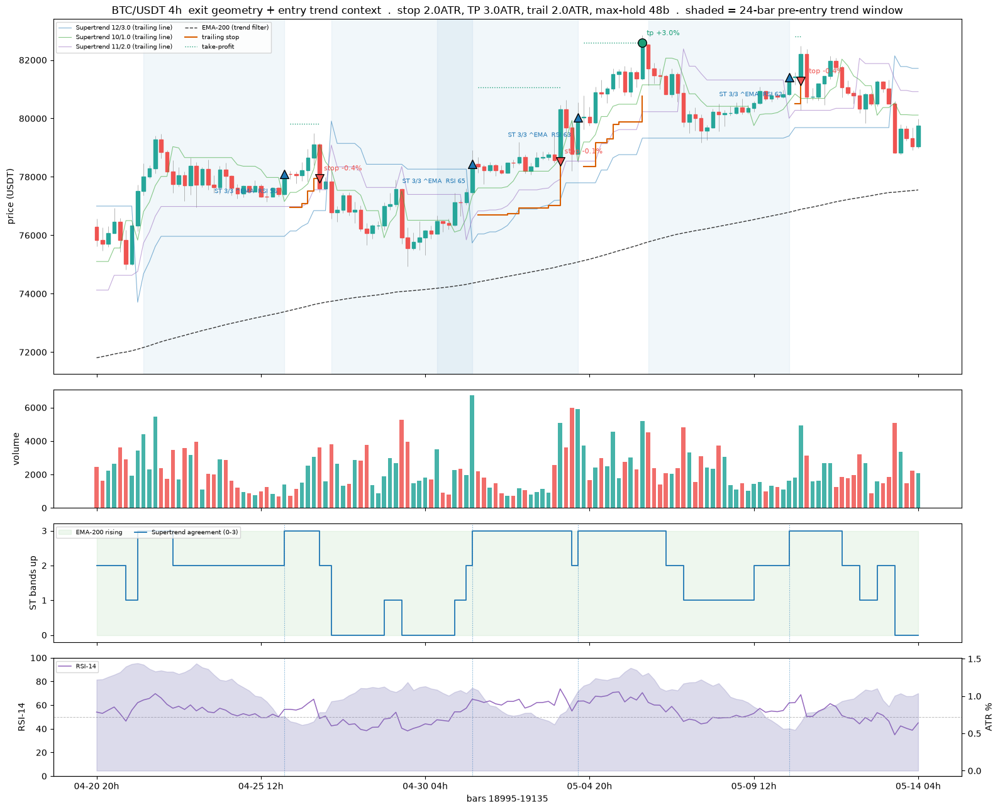

[compare] BTC/USDT 4h: anchored on entry at bar 19113


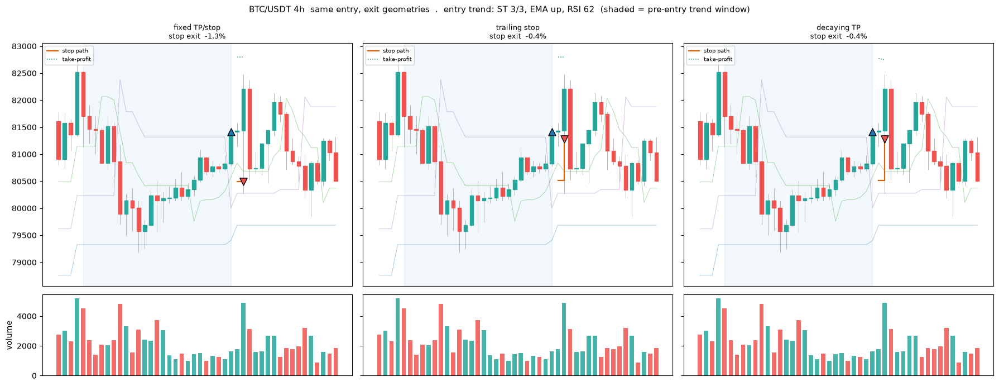

In [11]:
# Exit geometry + entry trend context (single source: 03-inputs/exit_geometry_viz.py)
import os, sys
for _up in (".", "..", "../..", "../../.."):
    _cand = os.path.abspath(os.path.join(_up, "03-inputs"))
    if os.path.isdir(_cand):
        sys.path.insert(0, _cand); break
import exit_geometry_viz as egv
egv.render("BTC/USDT", frame=4, show=True, save=False)   # display inline; chapter three saves the PNGs

### 1.6 Decision Checklist

The decision is not a board reading; it is the after-fee scoreboard. A signal counts only if it beats a coin flip, buy-and-hold, and the fee on a blind final year, and Part 3 runs that test per frame across 1h, 4h, and 5m. On the 1h frame the verdict is NO-GO, at the efficient-market floor; 4h carries a little more signal; the cross-sectional relative strength of 1.2 is the one real but still-underwater lead.

Two controls shape where a signal is allowed to trade. The regime state (`f_rg_`) gives the model observable context: trailing realized volatility and its own-history percentile, a short and a long trend drift, a Kaufman trend efficiency, up-down breadth, and the BTC market regime. The regime gate in 0.4 then deploys the cross-sectional signal only when BTC is trending up, the cheapest in-mandate way to lift the underwater edge.

The daily board is demoted to what it is, an eyeball scan. Read exits before entries, treat a green cell as a candidate to check against the Part 3 evaluation, size and fence it in Part 2, and remember every snapshot is saved and dated under `outputs/`. The signals table is written to CSV on each run.

In [12]:
stamp = datetime.now().strftime('%Y%m%d')
path = f'../04-outputs/CSV/DailySignals_{stamp}.csv'
results.to_csv(path, index=False)
print("saved", path)

saved ../04-outputs/CSV/DailySignals_20260906.csv


## 2. Trader Controls

The risk and rules layer, from `02-trader-controls`. The boundaries every candidate strategy must live inside, above all the fee. This is a selective, high-conviction swing design, not a scalper: a trade held for a clean three to five percent move can absorb a 0.2 percent round trip, a trade chasing half a percent cannot, so the fee is the floor. Three guardrails enforce that, a cap on trades per day, a minimum net-edge floor on thin trades, and the after-fee validation protocol.

The control logic is demonstrated on synthetic OHLCV so it is legible without a data dependency; in production it consumes the same survivorship-complete archives as Parts 1 and 3. The 0.4 adjustments live here where they touch sizing and stops: the stop and trailing stop are ATR-scaled and provisional pending the exit-geometry sweep, and the regime gate is a new control layered on top and implemented in Part 3.

### 2.1 Key Variables

Every tunable parameter lives in one `CONFIG` block, never hard-coded, and the risk-bounding ones are operator-owned and held outside the model's reach: reviewed weekly, and when the bot is built, lifted into a locked module the strategy file cannot write to. Secrets stay in the operator's Keychain, never in the repo.

The block sets the venue fences (the round-trip fee and modelled slippage), the per-trade economics (the net-edge floor, the take-profit target, the ATR-based stop), the ATR band (floor and ceiling), and the hard selection gates. The stop and take-profit here are a starting point, provisional pending the exit-geometry sweep in Part 3 and superseded by the ATR-scaled exits logged in 0.4. A Supertrend band is itself an ATR-channel trailing stop, so it belongs to this controls vocabulary alongside the volatility filter and the sizing rule.

In [13]:

import sys, subprocess
from pathlib import Path

# Pin the kernel to the same interpreter the rest of the repo uses.
REQUIRED_PY = (3, 11)
if sys.version_info[:2] < REQUIRED_PY:
    raise RuntimeError(
        f"This notebook needs Python {REQUIRED_PY[0]}.{REQUIRED_PY[1]} or newer, "
        f"but the kernel is {sys.version.split()[0]}. Switch to a 3.11+ kernel and re-run.")

# Install only the libraries THIS notebook imports that are missing (same targeted approach as the
# Part 1 environment cell, avoiding the numpy/numba resolver conflict of the full requirements install).
import importlib.util
_need = {"numpy": "numpy", "pandas": "pandas", "ccxt": "ccxt", "plotly": "plotly", "kaleido": "kaleido"}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing missing packages:", ", ".join(_missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "--break-system-packages",
                    "--disable-pip-version-check", *_missing], check=True)

import warnings, numpy as np, pandas as pd
pd.set_option("display.notebook_repr_html", False)  # IDE-safe: render DataFrames as text, not HTML
from datetime import datetime, timezone
import ccxt
import plotly, plotly.graph_objects as go, plotly.io as pio
warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+notebook_connected"
from IPython.display import HTML, Image, display

def show(fig):
    """Render a plotly figure as a STATIC PNG so it displays in any editor and in the Word export.
    Interactive HTML output blanks in some IDEs (Positron / VS Code, and anything that does not render
    text/html); a PNG always renders. Falls back to self-contained inline HTML with plotly.js embedded
    (offline-safe, no CDN) if the static-image engine (kaleido) is unavailable."""
    try:
        display(Image(fig.to_image(format="png", scale=2)))
    except Exception:
        display(HTML(fig.to_html(include_plotlyjs=True, full_html=False)))

# Resolve outputs to the repo-root outputs/ (absolute, cwd-independent) so the screen CSVs and the
# signal-journal HTML land in the MASTER <repo>/outputs/ and <repo>/outputs/journal/, not a duplicate
# folder beside this notebook. Repo root = parent of the inputs/ dir, found regardless of cwd (as in ch3).
import os
_INPUTS = next((os.path.abspath(c) for c in ("03-inputs", os.path.join("..", "03-inputs"), os.path.join("..", "..", "03-inputs")) if os.path.isdir(c)), None)
REPO_ROOT = Path(_INPUTS).parent if _INPUTS else Path("..").resolve()
OUTPUTS = REPO_ROOT / "04-outputs"; OUTPUTS.mkdir(parents=True, exist_ok=True)
print(f"Environment ready  ·  python {sys.version.split()[0]}")
print(f"  ccxt {ccxt.__version__} · pandas {pd.__version__} · "
      f"numpy {np.__version__} · plotly {plotly.__version__}")

Environment ready  ·  python 3.12.13
  ccxt 4.5.59 · pandas 2.3.3 · numpy 2.2.6 · plotly 6.8.0


In [14]:

# -- CONFIG -- outside the model's reach.
CONFIG = dict(
    # Venue fences — Binance crypto round trip (0.075%/side with BNB, 0.1% without)
    round_trip_fee_pct    = 0.15,      # two sides, BNB-discounted; use 0.20 without BNB
    expected_slippage_pct = 0.05,      # modelled slippage per round trip

    # Edge & exit (per-trade economics)
    edge_floor_pct        = 1.5,       # minimum NET expected move to allow a trade
    take_profit_pct       = 10.0,      # target gain; aligned to the Ch3 model label (+10%); must exceed edge_floor_pct
    stop_atr_mult         = 1.5,       # ATR-based stop; the Ch3 label uses a fixed -5% stop, so the stop model (ATR vs fixed) is the open item for 3C exit tuning

    # ATR band — selection filter AND live guardrail
    atr_length            = 14,
    atr_floor_pct         = 2.5,       # below this a coin can't reach TP in the window
    atr_ceiling_pct       = 12.0,      # above this it gaps through stop/TP unpredictably

    # Hard gates (selection screen)
    min_quote_volume_usdt = 30_000_000,# liquidity floor, 24h quote volume USDT
    max_spread_pct        = 0.05,      # spread ceiling, well under the fee
    min_history           = 120,       # candles required to span regimes
    history_limit         = 180,       # candles pulled per coin (90–180)

    # Frequency & position limits
    max_trades_per_day    = 3,         # hard cap — defence one against volume-hiding
    max_open_positions    = 4,         # concurrent positions (3–4 at this account size)
    risk_per_trade_pct    = 1.0,       # % of account risked per trade (constant $ risk)
    max_position_pct      = 30.0,      # cap any single position at this % of account
    min_notional_usdt     = 10.0,      # venue minimum clip; below this a trade isn't worth it

    # Hold window — a walk-forward RANGE, not a fixed number (swing band)
    hold_window_days_min  = 1,
    hold_window_days_max  = 20,        # aligned to the Ch3 model horizon (20 days)

    # Account & scan
    account_usdt          = 750.0,     # proving-rig size (~$500–1000)
    scan_top_n            = 25,        # scan wide (15–25), hold few (3–4)
)

# Public, read-only Binance client (currently not armed for orders).
EXCHANGE = "binance"
exchange = getattr(ccxt, EXCHANGE)()
exchange.set_sandbox_mode(False)   # public market data only

ALLOW_SYNTHETIC = True   # if a live fetch fails (offline / geo-blocked), fall back to
                         # deterministic synthetic data so the notebook still renders.
print(f"Configured {EXCHANGE} | account ${CONFIG['account_usdt']:.0f} | "
      f"edge floor {CONFIG['edge_floor_pct']}% | ATR band "
      f"{CONFIG['atr_floor_pct']}–{CONFIG['atr_ceiling_pct']}% | scan top {CONFIG['scan_top_n']}")

Configured binance | account $750 | edge floor 1.5% | ATR band 2.5–12.0% | scan top 25


### 2.2 Volatility Filter

The control demos run on synthetic OHLCV so the logic is the point, not the bars; `synthetic_ohlcv` and `fetch_daily` provide deterministic per-coin data offline, and the live path falls back to it if the network is unavailable. In production the same functions read the survivorship archives proven in Part 1.

The ATR band is the average true range over 14 days as a percent of price, a read of a coin's typical daily move, and it does two unrelated jobs. As a selection filter it admits or rejects a coin before the model sees it: below the floor, roughly two to three percent daily, a coin cannot reach the take-profit inside the hold window; above the ceiling it gaps through the stop and take-profit unpredictably and the indicators lose meaning. As a live guardrail it keeps the model from trading a coin that has drifted out of the tradable band.

In [15]:

def synthetic_ohlcv(symbol, n=None, daily_vol=None, seed=None):
    """Deterministic fake OHLCV for offline/geo-blocked demo. Seeded by symbol."""
    n = n or CONFIG["history_limit"]
    s = abs(hash(symbol)) % (2**32) if seed is None else seed
    rng = np.random.default_rng(s)
    dv = daily_vol if daily_vol is not None else float(rng.uniform(0.01, 0.10))
    rets = rng.normal(0, dv, n)
    close = 100 * np.exp(np.cumsum(rets))
    high  = close * (1 + np.abs(rng.normal(0, dv/2, n)))
    low   = close * (1 - np.abs(rng.normal(0, dv/2, n)))
    openp = np.r_[close[0], close[:-1]]
    vol   = rng.uniform(1e6, 5e6, n)
    idx   = pd.date_range("2025-01-01", periods=n, freq="D")
    return pd.DataFrame({"open":openp,"high":high,"low":low,"close":close,"volume":vol}, index=idx)

def fetch_daily(symbol, limit=None):
    """Daily OHLCV, unclosed bar dropped. Falls back to synthetic if offline."""
    limit = limit or CONFIG["history_limit"]
    try:
        bars = exchange.fetch_ohlcv(symbol, timeframe="1d", limit=limit)
        df = pd.DataFrame(bars[:-1], columns=["timestamp","open","high","low","close","volume"])
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        return df.set_index("timestamp")
    except Exception as e:
        if ALLOW_SYNTHETIC:
            return synthetic_ohlcv(symbol, n=limit)
        raise

def fetch_quote_volume(symbol):
    """24h quote volume in USDT (the liquidity gate input)."""
    try:
        return float(exchange.fetch_ticker(symbol).get("quoteVolume") or 0.0)
    except Exception:
        if ALLOW_SYNTHETIC:
            return float(np.random.default_rng(abs(hash(symbol))%2**32).uniform(2e6, 2.5e8))
        raise

def fetch_spread_pct(symbol):
    """Top-of-book spread as a percent of mid (the spread gate input)."""
    try:
        ob = exchange.fetch_order_book(symbol, limit=5)
        bid, ask = ob["bids"][0][0], ob["asks"][0][0]
        mid = (bid + ask) / 2
        return (ask - bid) / mid * 100.0
    except Exception:
        if ALLOW_SYNTHETIC:
            return float(np.random.default_rng(abs(hash(symbol))%2**32 + 7).uniform(0.005, 0.12))
        raise

def build_universe(top_n=None):
    """Most-traded /USDT spot pairs by quote volume on the execution venue."""
    top_n = top_n or CONFIG["scan_top_n"]
    try:
        tk = exchange.fetch_tickers()
        usdt = [(s, d.get("quoteVolume") or 0) for s, d in tk.items()
                if s.endswith("/USDT") and ":" not in s]
        uni = [s for s, _ in sorted(usdt, key=lambda x: -x[1])[:top_n]]
        if uni:
            return uni
    except Exception:
        pass
    # offline demo universe: a deliberate spread of regimes for the screen to sort
    print("(offline) using synthetic demo universe")
    return ["BTC/USDT","ETH/USDT","SOL/USDT","BNB/USDT","XRP/USDT","ADA/USDT",
            "AVAX/USDT","LINK/USDT","LTC/USDT","DOGE/USDT","TRX/USDT","DOT/USDT"]

universe = build_universe()
print(f"universe ({len(universe)}):", ", ".join(universe[:12]), "..." if len(universe) > 12 else "")

universe (25): USDC/USDT, BTC/USDT, ETH/USDT, ZEC/USDT, SOL/USDT, USD1/USDT, PROM/USDT, BNB/USDT, XRP/USDT, ARB/USDT, NEAR/USDT, UNI/USDT ...


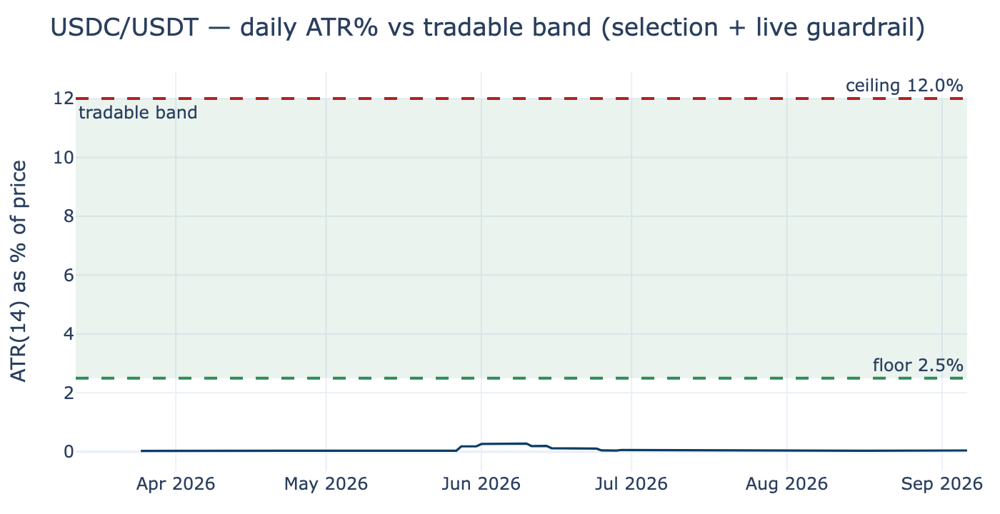

In [16]:

def compute_atr_pct(df, length=None):
    """ATR(length) as a percent of price. TR = max(H−L, |H−Cprev|, |L−Cprev|);
    ATR = simple moving average of TR (as written in §2); atr_pct = ATR/price×100."""
    length = length or CONFIG["atr_length"]
    h, l, c = df["high"], df["low"], df["close"]
    pc = c.shift(1)
    tr = pd.concat([(h - l).abs(), (h - pc).abs(), (l - pc).abs()], axis=1).max(axis=1)
    atr = tr.rolling(length).mean()
    return (atr / c) * 100.0

def atr_band_figure(symbol):
    """Live-guardrail view: ATR(14)% over time against the tradable band."""
    df = fetch_daily(symbol)
    atr_pct = compute_atr_pct(df)
    lo, hi = CONFIG["atr_floor_pct"], CONFIG["atr_ceiling_pct"]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=atr_pct.index, y=atr_pct, name="ATR(14) %",
                             line=dict(color="#0B3D66", width=1.6)))
    fig.add_hrect(y0=lo, y1=hi, fillcolor="#2E8B57", opacity=0.10, line_width=0,
                  annotation_text="tradable band", annotation_position="top left")
    fig.add_hline(y=lo, line=dict(color="#2E8B57", dash="dash"),
                  annotation_text=f"floor {lo}%")
    fig.add_hline(y=hi, line=dict(color="#B22222", dash="dash"),
                  annotation_text=f"ceiling {hi}%")
    fig.update_layout(title=f"{symbol} — daily ATR% vs tradable band (selection + live guardrail)",
                      template="plotly_white", height=360,
                      yaxis_title="ATR(14) as % of price", xaxis_title=None,
                      margin=dict(l=40, r=20, t=50, b=30))
    return fig

show(atr_band_figure(universe[0]))

### 2.3 Four-Gate Screen

Coins are screened individually each week on daily OHLCV plus the order-book top, through four gates. Gate 1 liquidity rejects anything below a 24-hour quote-volume floor, evaluated first because it is the cheap hard gate. Gate 2 is the ATR band, floor to ceiling as above. Gate 3 spread rejects anything wider than a tight ceiling well under the fee floor. Gate 4 history rejects tokens too young to carry a full indicator history. A coin passes only if all four hold, and the screen targets a shortlist of fifteen to twenty-five coins to hold positions on three or four.

The same four-gate screen is replayed point-in-time over history in Part 3, so each training row is kept only if it would have passed as of that bar. Because the archives carry no top-of-book spread, the historical replay approximates it with a Corwin-Schultz high-low estimator while the live screen uses the real spread. The candidate scatter places every scanned coin on liquidity against volatility, with survivors inside the band.

In [17]:

def screen_coin(symbol, cfg=CONFIG):
    """Run the four gates on one coin. Liquidity is evaluated first (it is the cheap,
    hard gate); all four numbers are recorded for the table either way."""
    df = fetch_daily(symbol, cfg["history_limit"])
    candle_count = int(len(df))
    quote_vol = fetch_quote_volume(symbol)
    spread = fetch_spread_pct(symbol)
    atr_series = compute_atr_pct(df, cfg["atr_length"])
    atr_pct = float(atr_series.iloc[-1]) if atr_series.notna().any() else float("nan")

    g1 = quote_vol >= cfg["min_quote_volume_usdt"]                       # liquidity (hard)
    g2 = (cfg["atr_floor_pct"] <= atr_pct <= cfg["atr_ceiling_pct"]) if atr_pct == atr_pct else False
    g3 = spread <= cfg["max_spread_pct"]                                 # spread (hard)
    g4 = candle_count >= cfg["min_history"]                              # history (sufficiency)
    gates = {"liquidity": bool(g1), "atr_band": bool(g2), "spread": bool(g3), "history": bool(g4)}
    passed = all(gates.values())
    fail = "" if passed else ",".join(k for k, v in gates.items() if not v)
    return {"symbol": symbol,
            "quote_volume_24h_usdt": round(quote_vol, 0),
            "atr_pct": round(atr_pct, 3),
            "spread_pct": round(spread, 4),
            "candle_count": candle_count,
            "pass": bool(passed), "fail_reason": fail, **gates}

def run_screen(universe, cfg=CONFIG, save=True):
    rows = []
    for s in universe:
        try:
            rows.append(screen_coin(s, cfg))
        except Exception as e:
            print("skip", s, type(e).__name__, str(e)[:60])
    tab = pd.DataFrame(rows).sort_values(["pass", "quote_volume_24h_usdt"],
                                         ascending=[False, False]).reset_index(drop=True)
    if save and len(tab):
        stamp = datetime.now(timezone.utc).strftime("%Y%m%d")
        path = OUTPUTS / f"Candidates_{stamp}.csv"
        tab.to_csv(path, index=False)
        print(f"saved {path}  ({int(tab['pass'].sum())} of {len(tab)} passed)")
    return tab

screen = run_screen(universe)
cols = ["symbol","quote_volume_24h_usdt","atr_pct","spread_pct","candle_count","pass","fail_reason"]
_view = screen[cols]
print(f"\nfour-gate screen -- {int(screen['pass'].sum())} of {len(screen)} coins passed:")
print(_view.to_string(index=False))    # text table: renders in every editor and in the Word export
display(_view)

saved /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260907.csv  (15 of 25 passed)

four-gate screen -- 15 of 25 coins passed:
       symbol  quote_volume_24h_usdt  atr_pct  spread_pct  candle_count  pass             fail_reason
     BTC/USDT            732952163.0    3.110      0.0000           179  True                        
     ETH/USDT            549652669.0    3.842      0.0004           179  True                        
     ZEC/USDT            447014630.0    7.205      0.0008           179  True                        
     SOL/USDT            292368345.0    5.398      0.0094           179  True                        
     BNB/USDT            135885810.0    3.311      0.0013           179  True                        
     XRP/USDT            102538164.0    5.454      0.0071           179  True                        
    NEAR/USDT             89248059.0    6.563      0.0416           179  True                        
     UNI/USDT             88129610.0    7

           symbol  quote_volume_24h_usdt  atr_pct  spread_pct  candle_count  \
0        BTC/USDT           7.329522e+08    3.110      0.0000           179   
1        ETH/USDT           5.496527e+08    3.842      0.0004           179   
2        ZEC/USDT           4.470146e+08    7.205      0.0008           179   
3        SOL/USDT           2.923683e+08    5.398      0.0094           179   
4        BNB/USDT           1.358858e+08    3.311      0.0013           179   
5        XRP/USDT           1.025382e+08    5.454      0.0071           179   
6       NEAR/USDT           8.924806e+07    6.563      0.0416           179   
7        UNI/USDT           8.812961e+07    7.667      0.0140           179   
8       DOGE/USDT           8.698734e+07    5.662      0.0110           179   
9       DASH/USDT           7.304122e+07    9.102      0.0143           179   
10       SUI/USDT           6.150122e+07    6.256      0.0123           179   
11       TAO/USDT           6.136757e+07    6.535   

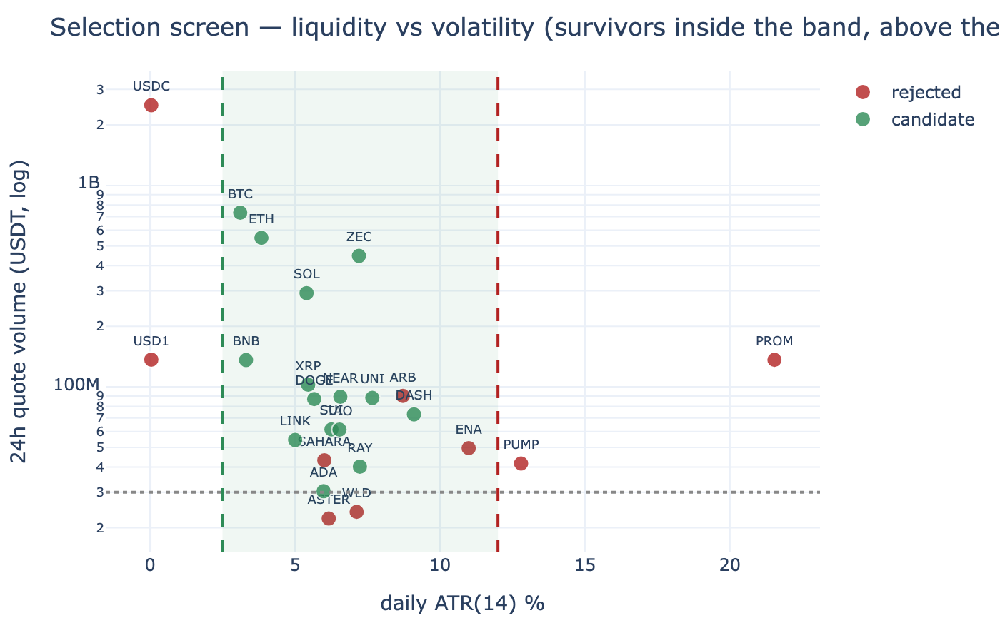

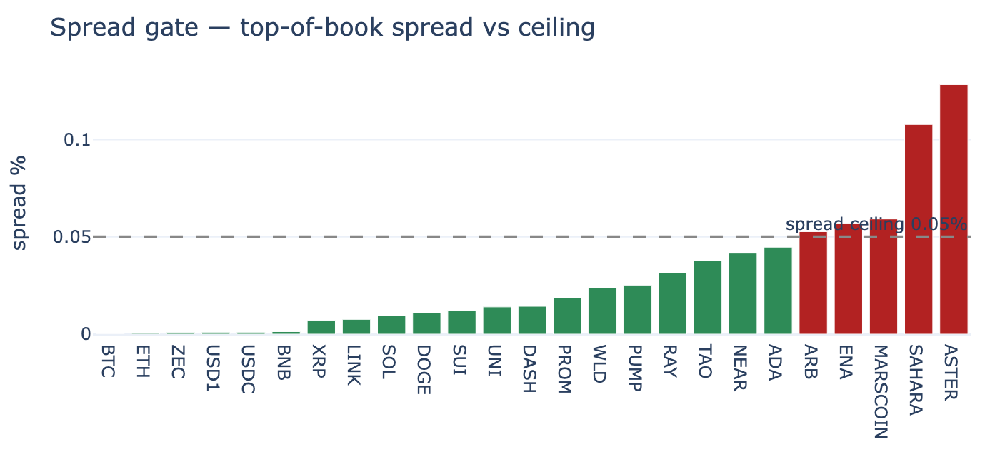

In [18]:

def screen_scatter(tab, cfg=CONFIG):
    passed = tab[tab["pass"]]; failed = tab[~tab["pass"]]
    fig = go.Figure()
    for d, name, col in [(failed, "rejected", "#B22222"), (passed, "candidate", "#2E8B57")]:
        if len(d):
            fig.add_trace(go.Scatter(
                x=d["atr_pct"], y=d["quote_volume_24h_usdt"], mode="markers+text",
                text=d["symbol"].str.replace("/USDT", ""), textposition="top center",
                textfont=dict(size=9), name=name,
                marker=dict(size=11, color=col, opacity=0.8,
                            line=dict(width=1, color="white"))))
    fig.add_vrect(x0=cfg["atr_floor_pct"], x1=cfg["atr_ceiling_pct"],
                  fillcolor="#2E8B57", opacity=0.07, line_width=0)
    fig.add_vline(x=cfg["atr_floor_pct"], line=dict(color="#2E8B57", dash="dash"))
    fig.add_vline(x=cfg["atr_ceiling_pct"], line=dict(color="#B22222", dash="dash"))
    fig.add_hline(y=cfg["min_quote_volume_usdt"], line=dict(color="#888", dash="dot"),
                  annotation_text="liquidity floor", annotation_position="bottom right")
    fig.update_layout(title="Selection screen — liquidity vs volatility (survivors inside the band, above the floor)",
                      template="plotly_white", height=440, yaxis_type="log",
                      xaxis_title="daily ATR(14) %", yaxis_title="24h quote volume (USDT, log)",
                      margin=dict(l=60, r=20, t=50, b=40))
    return fig

def spread_bars(tab, cfg=CONFIG):
    t = tab.sort_values("spread_pct")
    colors = ["#2E8B57" if v <= cfg["max_spread_pct"] else "#B22222" for v in t["spread_pct"]]
    fig = go.Figure(go.Bar(x=t["symbol"].str.replace("/USDT",""), y=t["spread_pct"],
                           marker_color=colors))
    fig.add_hline(y=cfg["max_spread_pct"], line=dict(color="#888", dash="dash"),
                  annotation_text=f"spread ceiling {cfg['max_spread_pct']}%")
    fig.update_layout(title="Spread gate — top-of-book spread vs ceiling",
                      template="plotly_white", height=320, yaxis_title="spread %",
                      margin=dict(l=50, r=20, t=50, b=40))
    return fig

show(screen_scatter(screen))
show(spread_bars(screen))

### 2.4 Edge Sizing

The net-edge fence is the entry gate: a trade is refused unless the estimated move minus the round-trip fee and slippage clears the edge floor. It is measured on net, not gross, and it refuses rather than warns. Exit coupling is enforced in code: the edge floor must sit below the take-profit, and the ATR floor must be high enough that a normal multi-day range reaches the take-profit inside the hold window.

Position sizing is volatility-scaled to keep dollar risk roughly constant across coins: the stop distance times the position value is held near a fixed risk budget, so a higher-ATR coin earns a smaller clip and a calmer coin a larger one, never past the per-position cap or below the venue minimum. At a small account this pushes toward a few larger positions rather than many tiny clips that waste edge on fees. The take-profit and stop in the CONFIG reference an older fixed label and are provisional pending the exit-geometry and label sweeps in 0.4 and Part 3.

In [19]:

# -- Net edge fence (entry gate) ---
def net_edge(est_move_pct, cfg=CONFIG):
    """NET expected move after round-trip fee and slippage (not gross)."""
    return est_move_pct - cfg["round_trip_fee_pct"] - cfg["expected_slippage_pct"]

def net_edge_ok(est_move_pct, cfg=CONFIG):
    """The fence: refuse unless net move clears the floor. Refuses, does not warn."""
    return net_edge(est_move_pct, cfg) >= cfg["edge_floor_pct"]

# -- Exit coupling (enforced ordering) ---
def validate_exit_coupling(cfg=CONFIG):
    rt = cfg["round_trip_fee_pct"] + cfg["expected_slippage_pct"]
    days_to_tp = cfg["take_profit_pct"] / cfg["atr_floor_pct"]   # at the ATR floor
    return {
        "edge_floor < take_profit":            cfg["edge_floor_pct"] < cfg["take_profit_pct"],
        "round_trip < edge_floor":             rt < cfg["edge_floor_pct"],
        "take_profit > 2x round_trip (alive)":  cfg["take_profit_pct"] > 2 * rt,
        f"TP reachable at the ATR floor within the window (about {days_to_tp:.1f} days)":
            days_to_tp <= cfg["hold_window_days_max"],
    }

# -- ATR-scaled position sizing (constant dollar risk) ---
def position_plan(atr_pct, cfg=CONFIG, account=None):
    """Size so dollar risk is ~constant across coins: higher ATR -> smaller position.
    stop% = stop_atr_mult × daily ATR%; size = risk_budget / stop%. Capped at
    max_position_pct, floored at the venue minimum notional."""
    account = account or cfg["account_usdt"]
    stop_pct = cfg["stop_atr_mult"] * atr_pct
    risk_budget = account * cfg["risk_per_trade_pct"] / 100.0
    raw = risk_budget / (stop_pct / 100.0) if stop_pct > 0 else 0.0
    capped = min(raw, account * cfg["max_position_pct"] / 100.0)
    final = max(capped, cfg["min_notional_usdt"])
    return {"atr_pct": round(atr_pct, 3), "stop_pct": round(stop_pct, 3),
            "risk_budget_usdt": round(risk_budget, 2), "raw_size_usdt": round(raw, 2),
            "position_usdt": round(final, 2),
            "floored_at_min": bool(final == cfg["min_notional_usdt"] and capped < cfg["min_notional_usdt"])}

print("Net-edge fence (gross est. move -> net -> allowed?):")
for m in (1.0, 1.5, 2.0, 3.5):
    print(f"  est {m:>4}%  ->  net {net_edge(m):>5.2f}%  ->  {'ALLOW' if net_edge_ok(m) else 'refuse'}")

print("\nExit-coupling checks (config must satisfy all):")
for k, v in validate_exit_coupling().items():
    print(f"  [{'ok' if v else 'XX'}] {k}")

Net-edge fence (gross est. move -> net -> allowed?):
  est  1.0%  ->  net  0.80%  ->  refuse
  est  1.5%  ->  net  1.30%  ->  refuse
  est  2.0%  ->  net  1.80%  ->  ALLOW
  est  3.5%  ->  net  3.30%  ->  ALLOW

Exit-coupling checks (config must satisfy all):
  [ok] edge_floor < take_profit
  [ok] round_trip < edge_floor
  [ok] take_profit > 2x round_trip (alive)
  [ok] TP reachable at the ATR floor within the window (about 4.0 days)


       symbol  atr_pct  stop_pct  position_usdt  floored_at_min
0    BTC/USDT    3.110     4.665         160.77           False
1    BNB/USDT    3.311     4.966         151.01           False
2    ETH/USDT    3.842     5.763         130.14           False
3   LINK/USDT    5.003     7.505          99.94           False
4    SOL/USDT    5.398     8.097          92.63           False
5    XRP/USDT    5.454     8.181          91.68           False
6   DOGE/USDT    5.662     8.493          88.31           False
7    ADA/USDT    5.985     8.978          83.54           False
8    SUI/USDT    6.256     9.384          79.92           False
9    TAO/USDT    6.535     9.803          76.51           False
10  NEAR/USDT    6.563     9.845          76.18           False
11   ZEC/USDT    7.205    10.808          69.40           False
12   RAY/USDT    7.238    10.857          69.08           False
13   UNI/USDT    7.667    11.500          65.21           False
14  DASH/USDT    9.102    13.653        

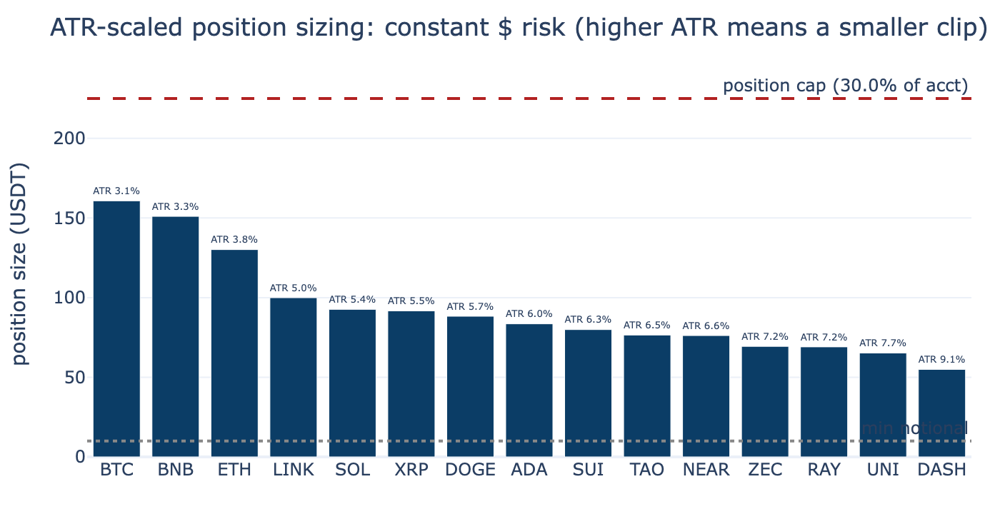

In [20]:

cands = screen[screen["pass"]].copy()
if len(cands):
    plans = cands["atr_pct"].apply(lambda a: pd.Series(position_plan(a)))
    sized = pd.concat([cands[["symbol","atr_pct"]].reset_index(drop=True),
                       plans.reset_index(drop=True)[["stop_pct","position_usdt","floored_at_min"]]], axis=1)
    sized = sized.sort_values("position_usdt", ascending=False).reset_index(drop=True)
    display(sized)
    fig = go.Figure(go.Bar(x=sized["symbol"].str.replace("/USDT",""), y=sized["position_usdt"],
                           marker_color="#0B3D66",
                           text=[f"ATR {a:.1f}%" for a in sized["atr_pct"]], textposition="outside"))
    fig.add_hline(y=CONFIG["account_usdt"]*CONFIG["max_position_pct"]/100,
                  line=dict(color="#B22222", dash="dash"),
                  annotation_text=f"position cap ({CONFIG['max_position_pct']}% of acct)")
    fig.add_hline(y=CONFIG["min_notional_usdt"], line=dict(color="#888", dash="dot"),
                  annotation_text="min notional")
    fig.update_layout(title="ATR-scaled position sizing: constant $ risk (higher ATR means a smaller clip)",
                      template="plotly_white", height=360, yaxis_title="position size (USDT)",
                      margin=dict(l=50, r=20, t=50, b=40))
    show(fig)
else:
    print("No candidates cleared the screen on this run — widen the universe or revisit the band.")

### 2.5 Hold Period

The hold period is the swing band, days to about two weeks. Scalping and day-trading are ruled out by fees and the pattern-day-trading rule, position-trading by underusing the signal stack. Within the swing band the hold window is a walk-forward parameter, searched roughly one to twenty days and picked by out-of-sample results, not by a gut figure. Shorter holds demand a higher ATR to reach the target in time; longer holds tolerate a lower one. This is the same coupling as the edge fence, seen on the time axis.

### 2.6 Stacked Defences

The defences are layered, not single. The selection screen keeps unsuitable coins out, the net-edge fence keeps thin trades out, the ATR band is both a selection filter and a live guardrail, the position cap and venue minimum bound each clip, and the per-day trade cap and the cash floor bound the book. Above them sit the 0.4 controls: the ATR-scaled stop and trailing stop, provisional pending the exit-geometry sweep, and the new regime gate that only lets the cross-sectional signal trade when BTC is trending up, implemented in Part 3.

The floor fence is the minimum net edge; the venue fences are the fee and slippage assumptions that define it. Each defence is cheap and independent, so a coin must clear all of them and any one can veto.

### 2.7 Signal Journal

A learning aid, not a trader. For each coin it finds every entry and exit the MACD logic produced, draws the candles with the moving averages and a volume histogram, marks each signal, and writes a table beside the chart recording what the model saw, trend, RSI, and volatility, and whether the fee fence would actually let the trade fire. Each study sheet is saved as a self-contained HTML page under `outputs/journal/`, so a visual library builds up on every run. The net-edge column uses the take-profit as a stand-in for the expected move until the Part 3 model supplies a real per-trade estimate; the entries marked would-fire are the ones that clear both the fee floor and the ATR band.

In [21]:
from plotly.subplots import make_subplots

def compute_signals(df, cfg=CONFIG):
    """Add MACD, signal, histogram, EMAs, RSI(14), ATR% and crossover flags to a daily frame."""
    c = df["close"]
    df["ema12"] = c.ewm(span=12, adjust=False).mean()
    df["ema26"] = c.ewm(span=26, adjust=False).mean()
    df["macd"]   = df["ema12"] - df["ema26"]
    df["signal"] = df["macd"].ewm(span=9, adjust=False).mean()
    df["hist"]   = df["macd"] - df["signal"]
    d = c.diff(); up = d.clip(lower=0).rolling(14).mean(); dn = (-d.clip(upper=0)).rolling(14).mean()
    df["rsi"] = 100 - 100 / (1 + up / dn)
    df["atr_pct"] = compute_atr_pct(df, cfg["atr_length"])
    df["cross_up"]   = (df["macd"] > df["signal"]) & (df["macd"].shift(1) <= df["signal"].shift(1))
    df["cross_down"] = (df["macd"] < df["signal"]) & (df["macd"].shift(1) >= df["signal"].shift(1))
    return df

def signal_events(df, cfg=CONFIG):
    """One row per entry/exit, documenting what the model saw and whether the fee fence would let
    an entry fire. est. move uses the take-profit target until the predictive model supplies one."""
    rows = []
    for i in range(1, len(df)):
        buy, sell = bool(df["cross_up"].iloc[i]), bool(df["cross_down"].iloc[i])
        if not (buy or sell):
            continue
        atr = float(df["atr_pct"].iloc[i]); rsi = float(df["rsi"].iloc[i])
        trend = "up" if df["ema12"].iloc[i] > df["ema26"].iloc[i] else "down"
        net = cfg["take_profit_pct"] - cfg["round_trip_fee_pct"] - cfg["expected_slippage_pct"]
        in_band = (cfg["atr_floor_pct"] <= atr <= cfg["atr_ceiling_pct"]) if atr == atr else False
        fires = buy and net >= cfg["edge_floor_pct"] and in_band
        rows.append({
            "date": str(df.index[i].date()),
            "action": "enter / buy" if buy else "exit / sell",
            "price": round(float(df["close"].iloc[i]), 4),
            "trend": trend,
            "rsi": round(rsi, 0) if rsi == rsi else None,
            "atr_pct": round(atr, 2) if atr == atr else None,
            "net_edge_pct": round(net, 2),
            "fence": ("would fire" if fires else
                      "exit" if sell else
                      "blocked: out of band" if not in_band else "blocked: thin edge"),
            "size_usdt": position_plan(atr)["position_usdt"] if fires else None,
            "note": ("MACD crossed above signal -> momentum turning up" if buy
                     else "MACD crossed below signal -> momentum turning down"),
        })
    return pd.DataFrame(rows)

def journal_overview(df, symbol, window=120):
    """Candles + EMAs + buy/sell markers on top, a volume histogram in the middle, MACD underneath."""
    w = df.tail(window)
    vol_col = ["#26a69a" if c >= o else "#ef5350" for o, c in zip(w["open"], w["close"])]
    fig = make_subplots(rows=3, cols=1, shared_xaxes=True, row_heights=[0.62, 0.16, 0.22],
                        vertical_spacing=0.05,
                        subplot_titles=(f"{symbol} - price with model entries (buy) and exits (sell)",
                                        "volume", "MACD (momentum)"))
    fig.add_trace(go.Candlestick(x=w.index, open=w["open"], high=w["high"], low=w["low"], close=w["close"],
                                 name="price", showlegend=False), row=1, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["ema12"], line=dict(color="#1f77b4", width=1), name="EMA-12"), row=1, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["ema26"], line=dict(color="#9467bd", width=1), name="EMA-26"), row=1, col=1)
    b, s = w[w["cross_up"]], w[w["cross_down"]]
    fig.add_trace(go.Scatter(x=b.index, y=b["low"] * 0.96, mode="markers",
                  marker=dict(symbol="triangle-up", size=12, color="#2E8B57"), name="model buy"), row=1, col=1)
    fig.add_trace(go.Scatter(x=s.index, y=s["high"] * 1.04, mode="markers",
                  marker=dict(symbol="triangle-down", size=12, color="#C0392B"), name="model sell"), row=1, col=1)
    fig.add_trace(go.Bar(x=w.index, y=w["volume"], name="volume", showlegend=False,
                  marker_color=vol_col), row=2, col=1)
    fig.add_trace(go.Bar(x=w.index, y=w["hist"], opacity=0.4, name="histogram",
                  marker_color=["#2E8B57" if h >= 0 else "#C0392B" for h in w["hist"]]), row=3, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["macd"], line=dict(color="#0B3D66"), name="MACD"), row=3, col=1)
    fig.add_trace(go.Scatter(x=w.index, y=w["signal"], line=dict(color="#E08A1E"), name="signal"), row=3, col=1)
    fig.update_layout(template="plotly_white", height=680, xaxis_rangeslider_visible=False,
                      margin=dict(l=40, r=20, t=46, b=30), legend=dict(orientation="h", y=1.06))
    return fig

def save_journal(symbol, cfg=CONFIG, outdir=None):
    """Study sheet for one coin: overview chart + an events table documenting the model's actions,
    saved as a self-contained HTML page under outputs/journal/. Returns (path, fig, events)."""
    outdir = Path(outdir or (OUTPUTS / "journal")); outdir.mkdir(parents=True, exist_ok=True)
    df = compute_signals(fetch_daily(symbol, max(cfg["history_limit"], 220)), cfg)
    ev = signal_events(df, cfg)
    fig = journal_overview(df, symbol)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d")
    path = outdir / f"journal_{symbol.replace('/', '-')}_{stamp}.html"
    last = ev.iloc[-1].to_dict() if len(ev) else {}
    intro = (f"<h2 style='font-family:Arial'>{symbol} - signal journal</h2>"
             f"<p style='font-family:Arial;max-width:820px;color:#333'>Each triangle is a MACD/signal crossover: "
             f"green = the model would consider entering, red = it would exit. The table records what the model saw "
             f"at each point and whether the fee fence would let an entry actually fire. Latest event: "
             f"<b>{last.get('action','-')}</b> on {last.get('date','-')} at {last.get('price','-')} "
             f"({last.get('fence','-')}).</p>")
    style = ("<style>table{border-collapse:collapse;font-family:Arial;font-size:13px}"
             "th,td{border:1px solid #ddd;padding:6px 9px;text-align:left}"
             "th{background:#0B3D66;color:#fff}tr:nth-child(even){background:#f5f7fa}</style>")
    path.write_text("<html><head><meta charset='utf-8'>" + style + "</head><body>" + intro +
                    fig.to_html(include_plotlyjs="cdn", full_html=False) +
                    "<h3 style='font-family:Arial'>What the model saw and did</h3>" +
                    ev.to_html(index=False, border=0) + "</body></html>")
    return path, fig, ev

saved /Volumes/PortableSSD/Github/day-trader/04-outputs/journal/journal_BTC-USDT_20260907.html  -  21 entries/exits documented
saved /Volumes/PortableSSD/Github/day-trader/04-outputs/journal/journal_ETH-USDT_20260907.html  -  15 entries/exits documented


saved /Volumes/PortableSSD/Github/day-trader/04-outputs/journal/journal_ZEC-USDT_20260907.html  -  19 entries/exits documented

3 journal(s) saved under outputs/journal/

--- BTC/USDT ---


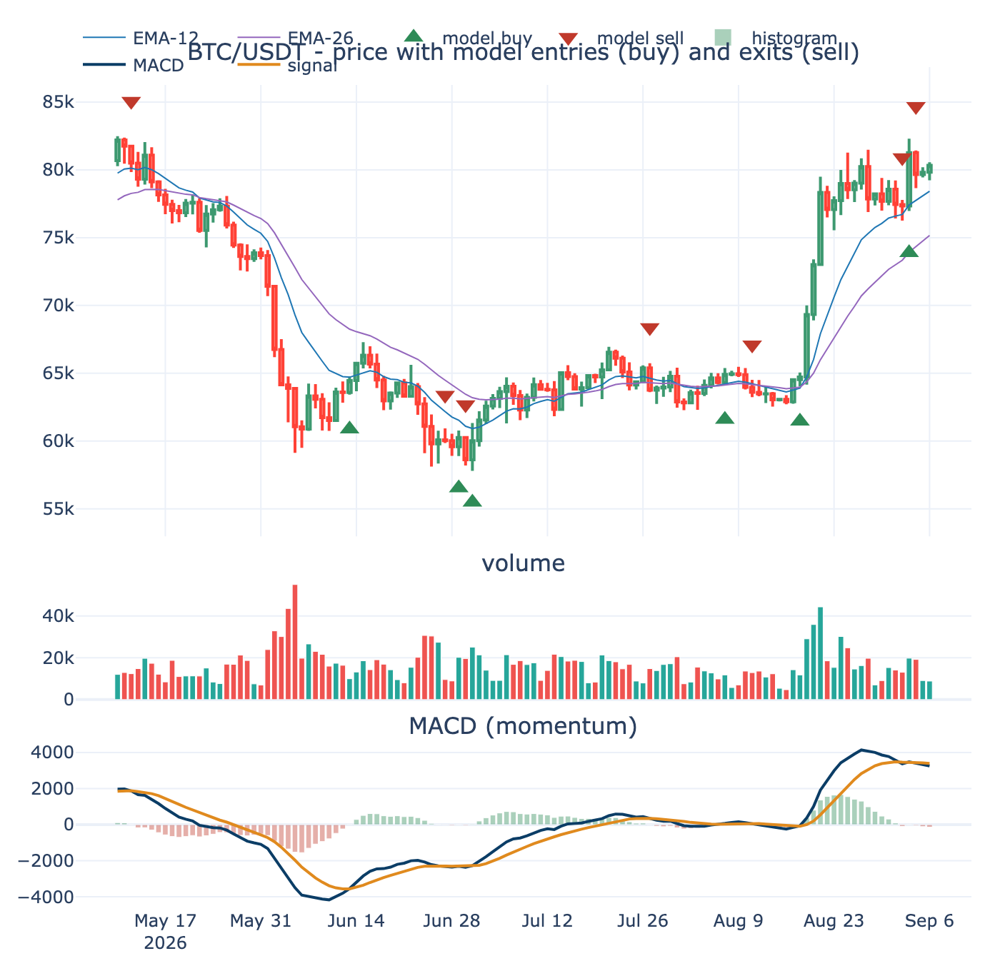

          date       action     price trend   rsi  atr_pct  net_edge_pct  \
0   2026-02-01  exit / sell  76968.21  down   NaN      NaN           9.8   
1   2026-02-20  enter / buy  68020.01  down  41.0     4.27           9.8   
2   2026-02-24  exit / sell  64058.15  down  34.0     3.97           9.8   
3   2026-02-25  enter / buy  67988.04  down  53.0     4.00           9.8   
4   2026-03-21  exit / sell  68918.12    up  55.0     3.86           9.8   
5   2026-04-06  enter / buy  68853.66  down  42.0     3.17           9.8   
6   2026-04-28  exit / sell  76342.77    up  57.0     2.89           9.8   
7   2026-05-04  enter / buy  79861.01    up  67.0     2.48           9.8   
8   2026-05-12  exit / sell  80504.47    up  68.0     2.36           9.8   
9   2026-06-13  enter / buy  64458.01  down  27.0     4.28           9.8   
10  2026-06-27  exit / sell  60029.00  down  33.0     3.66           9.8   
11  2026-06-29  enter / buy  60260.21  down  25.0     3.58           9.8   
12  2026-06-

In [22]:
# Build a journal for the top few coins that cleared tonight's screen (fallback to liquid majors).
try:
    to_study = list(screen[screen["pass"]]["symbol"].head(3))
except Exception:
    to_study = []
if not to_study:
    to_study = ["BTC/USDT", "ETH/USDT", "SOL/USDT"]

journals = []
for sym in to_study:
    try:
        path, fig, ev = save_journal(sym)
        journals.append((sym, path, fig, ev))
        print(f"saved {path}  -  {len(ev)} entries/exits documented")
    except Exception as e:
        print("skip", sym, type(e).__name__, str(e)[:60])
print(f"\n{len(journals)} journal(s) saved under outputs/journal/")

# Show the first journal inline: the chart, then the table of what the model did.
if journals:
    sym, path, fig, ev = journals[0]
    print(f"\n--- {sym} ---")
    show(fig)
    display(ev)

### 2.8 Frozen Harness

The yardstick is frozen and operator-owned. Every walk-forward run appends one line to a log, the parameters tried, the out-of-sample after-fee result, and whether it was kept or discarded, and the operator reviews it weekly. The model never writes to the harness or the log, which keeps the evaluation surface human rather than automated away. The harness fixes the out-of-sample window, the train window, the embargo that straddles the cut, the regime set, the fee assumption, and the metric, identical across every comparison so results are commensurable.

The dated candidate table and the experiment log are written under `outputs/` each run, and nothing else: the notebook screens and sizes only, no orders, with `LIVE_TRADING` left false and never read here.

In [23]:

# Frozen evaluation harness — versioned, identical across every comparison. (locked)
HARNESS = dict(
    version            = "harness-v1",
    oos_window_days    = 90,
    train_window_days  = 365,
    embargo_days       = 20,                       # straddles the train/test cut
    regime_set         = ["bull", "bear", "sideways"],
    fee_assumption_pct = CONFIG["round_trip_fee_pct"],
    metric             = "oos_after_fee_expectancy",
)

def log_experiment(params: dict, oos_result: dict, kept: bool, why: str,
                   path=OUTPUTS / "experiment_log.csv"):
    """Append one line per walk-forward run. The artefact the operator wakes to."""
    row = {"ts_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
           "harness": HARNESS["version"], "kept": bool(kept), "why": why,
           **{f"p_{k}": v for k, v in params.items()},
           **{f"oos_{k}": v for k, v in oos_result.items()}}
    df = pd.DataFrame([row])
    header = not path.exists()
    df.to_csv(path, mode="a", header=header, index=False)
    return path

# Demonstration entry (replace with real walk-forward output once that loop exists).
p = log_experiment(
    params=dict(edge_floor_pct=CONFIG["edge_floor_pct"], take_profit_pct=CONFIG["take_profit_pct"],
                atr_floor_pct=CONFIG["atr_floor_pct"], threshold=2),
    oos_result=dict(after_fee_expectancy_pct=-0.4, win_rate=0.41, n_trades=37, vs_buy_hold_pct=+1.2),
    kept=False, why="no demonstrated OOS edge after fees (matches standing NO-GO)")
print("logged ->", p)
_log = pd.read_csv(p)
print(f'\nexperiment_log.csv ({len(_log)} rows; last 3):')
print(_log.tail(3).to_string(index=False))    # text fallback: renders in every IDE
display(_log.tail(3))

logged -> /Volumes/PortableSSD/Github/day-trader/04-outputs/experiment_log.csv

experiment_log.csv (6 rows; last 3):
                   ts_utc    harness  kept                                                          why  p_edge_floor_pct  p_take_profit_pct  p_atr_floor_pct  p_threshold  oos_after_fee_expectancy_pct  oos_win_rate  oos_n_trades  oos_vs_buy_hold_pct
2026-09-07T00:11:11+00:00 harness-v1 False no demonstrated OOS edge after fees (matches standing NO-GO)               1.5               10.0              2.5            2                          -0.4          0.41            37                  1.2
2026-09-07T00:33:50+00:00 harness-v1 False no demonstrated OOS edge after fees (matches standing NO-GO)               1.5               10.0              2.5            2                          -0.4          0.41            37                  1.2
2026-09-07T00:58:06+00:00 harness-v1 False no demonstrated OOS edge after fees (matches standing NO-GO)               1.5            

                      ts_utc     harness   kept  \
3  2026-09-07T00:11:11+00:00  harness-v1  False   
4  2026-09-07T00:33:50+00:00  harness-v1  False   
5  2026-09-07T00:58:06+00:00  harness-v1  False   

                                                 why  p_edge_floor_pct  \
3  no demonstrated OOS edge after fees (matches s...               1.5   
4  no demonstrated OOS edge after fees (matches s...               1.5   
5  no demonstrated OOS edge after fees (matches s...               1.5   

   p_take_profit_pct  p_atr_floor_pct  p_threshold  \
3               10.0              2.5            2   
4               10.0              2.5            2   
5               10.0              2.5            2   

   oos_after_fee_expectancy_pct  oos_win_rate  oos_n_trades  \
3                          -0.4          0.41            37   
4                          -0.4          0.41            37   
5                          -0.4          0.41            37   

   oos_vs_buy_hold_pct  
3  

In [24]:

print("Artefacts written this run:")
for f in sorted(OUTPUTS.glob("Candidates_*.csv")) + [OUTPUTS / "experiment_log.csv"]:
    if f.exists():
        print(f"  {f}  ({f.stat().st_size} bytes)")
print("\nReminder: this notebook screens and sizes only. No orders are placed; "
      "LIVE_TRADING stays 'false' in inputs/config.py and is never read here.")

Artefacts written this run:
  /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260629.csv  (1946 bytes)
  /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260701.csv  (1956 bytes)
  /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260703.csv  (1995 bytes)
  /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260906.csv  (1858 bytes)
  /Volumes/PortableSSD/Github/day-trader/04-outputs/Candidates_20260907.csv  (1825 bytes)
  /Volumes/PortableSSD/Github/day-trader/04-outputs/experiment_log.csv  (978 bytes)

Reminder: this notebook screens and sizes only. No orders are placed; LIVE_TRADING stays 'false' in inputs/config.py and is never read here.


## 3. Trader Execution

The modeling and search layer, from `03-trader-execution`. Where the datasets, features, and model meet the after-fee test, run per frame across 1h, 4h, and 5m. This is the decision-grade chapter: everything Parts 1 and 2 describe is built, screened point-in-time, labelled, trained, and scored on a blind final year here, and only what clears the fee out of sample counts.

The 0.4 adjustments are implemented across these sections: the label in 3.1 and 3.7, the ATR-scaled exits in 3.3, the regime gate in 3.12, and the longer-horizon frame across every per-frame loop. The cells run top to bottom on the project `.venv`. `LOAD_FRAME` selects the active frame the single-frame cells consume; the multi-frame sections from 3.9 on loop over all three frames on their own and restore the active frame afterward.

### 3.1 Data Preparation

The environment imports the shared loader `build_dataset_1h`, the split and cost machinery, and the model libraries. The three frames are built offline from the survivorship-complete `data.binance.vision` archives into `dataset_5m_allmarket`, `dataset_1h_allmarket`, and `dataset_4h_allmarket`, one builder retuned per frame. `LOAD_FRAME` picks the active frame, Import Data loads its Parquet into `df` and `feat`, and the train-test split holds out the final year with an embargo equal to the label horizon so no future leaks across the cut. The label is the ATR-scaled triple barrier; the 0.4 revision toward a longer, less fee-punishing geometry is the intended change tracked here.

In [25]:
import os, sys
from pathlib import Path


if sys.version_info[:2] < (3, 11):
    raise RuntimeError(f"Use the project .venv (Python 3.12); kernel is {sys.version.split()[0]}.")
try:
    import numpy as np, pandas as pd, joblib
    pd.set_option("display.notebook_repr_html", False)  # IDE-safe: render DataFrames as text, not HTML
    import matplotlib.pyplot as plt
except ModuleNotFoundError as e:
    raise RuntimeError(
        f"Missing '{e.name}'. This kernel is not the project .venv (running {sys.executable}). "
        "Switch to 'Python (day-trader .venv)' via Kernel -> Change Kernel, then re-run."
    ) from e

# Shared modeling + evaluation code: the SAME functions the scripts run.
INPUTS_DIR = None
for cand in ["03-inputs", os.path.join("..", "03-inputs"), os.path.join("..", "..", "03-inputs")]:
    if os.path.isdir(cand):
        INPUTS_DIR = os.path.abspath(cand)
        sys.path.insert(0, INPUTS_DIR); break
REPO_ROOT = Path(INPUTS_DIR).parent          # repo root = parent of 03-inputs/, regardless of cwd
import build_dataset_1h as bd        # 1h features, ATR-scaled label, point-in-time screen
import train_model as tm             # shared: build_models, evaluate, confidence_filtered, costs
import train_model_1h as t1          # 1h load + final-year split
import eval_report
HAVE_LGBM = tm.HAVE_LGBM

def _layer(mod):
    try:
        __import__(mod); return "yes"
    except Exception:
        return "no"

OUTPUTS = REPO_ROOT / "04-outputs"                          # absolute <repo>/outputs, never the cwd-relative one
MODEL_DIR = OUTPUTS / "3B-model-training"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f"outputs -> {OUTPUTS}")
print(f"env ready  .  kernel: {sys.executable}")
print(f"python {sys.version.split()[0]}  .  lightgbm {'yes' if HAVE_LGBM else 'no'}"
      f"  .  pandas-ta {_layer('pandas_ta')}  .  TA-Lib {_layer('talib')}")

# --- inline table rendering (Positron-safe) -------------------------------------------
# Positron routes a bare display(df) to its live Data Explorer pane, which shows blank
# inline and dies on reload. show_table() emits a static HTML table that renders in the
# cell and survives reload, in Positron, Jupyter and VS Code alike.
from IPython.display import HTML, display, Markdown, Image  # noqa: F401  (Markdown/Image used later)

def show_table(x):
    obj = x.to_frame() if (hasattr(x, "to_frame") and getattr(x, "ndim", 2) == 1) else x
    display(HTML(obj.to_html()))


# --- inline figure rendering (Positron-safe) ------------------------------------------
# Positron (and nbconvert with a non-interactive backend) route plt.show() to a side pane, so
# matplotlib figures never embed in the .ipynb and the saved notebook reads blank. show_fig()
# rasterises the figure to an inline PNG that renders in the cell and survives reload -- the
# plot analogue of show_table() above. Pass a Figure; None is tolerated (some plotters return
# None when there is nothing to draw). Use show_fig(fig) in place of plt.show().
import io as _io

def show_fig(fig, dpi=120):
    if fig is None:
        print("(no figure to show)"); return
    buf = _io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buf.getvalue()))


outputs -> /Volumes/PortableSSD/Github/day-trader/04-outputs
env ready  .  kernel: /Volumes/PortableSSD/Github/day-trader/.venv/bin/python


python 3.12.13  .  lightgbm yes  .  pandas-ta yes  .  TA-Lib yes


In [26]:
# Knobs live in the scripts so the notebook cannot drift. Read-only here.
CONFIG = dict(
    oos_days     = t1.OOS_DAYS,         # final year held out of sample
    embargo_days = t1.EMBARGO_DAYS,     # = label horizon in days
    conf_hi      = tm.CONF_HI,          # confidence filter act-long (Keller Metric 1)
    conf_lo      = tm.CONF_LO,          # act-short / stand-aside
    cost_pct     = tm.COST_PCT,         # round-trip drag (fee + slippage), Metric 2
)
lab = bd.LABEL
print(f"label: +{lab['tgt_atr']} ATR before -{lab['stp_atr']} ATR within {lab['horizon_bars']} bars "
      f"({lab['horizon_bars']//bd.BARS_PER_DAY}d)  .  hold out final {CONFIG['oos_days']}d, "
      f"embargo +/-{CONFIG['embargo_days']}d  .  confidence {CONFIG['conf_lo']}-{CONFIG['conf_hi']}  .  "
      f"cost {CONFIG['cost_pct']:.2f}% round trip")

label: +2.0 ATR before -1.0 ATR within 12 bars (2d)  .  hold out final 365d, embargo +/-2d  .  confidence 0.4-0.6  .  cost 0.20% round trip


In [27]:
# Import Data: build provenance for EVERY built frame (1h, 4h, 5m) + the load of ONE active frame.
# Reads the LIVE config from build_dataset_1h and file timestamps; does NOT rebuild anything. The
# modelling cells below consume df/feat, so exactly one frame is loaded -- 1h by default, switch with
# LOAD_FRAME. The Multi-Resolution Datasets section above compares all three head to head.
import os, datetime as _dt

LOAD_FRAME = "1h"          # active modelling frame: "1h", "4h" or "5m" (drives df/feat + bd config below)

def _ds_path(label): return os.path.join(bd.BINANCE_DATA, f"dataset_{label}_allmarket.parquet")
def _kl_root(label): return os.path.join(bd.BINANCE_DATA, f"klines_{label}")
def _built(p):
    base = os.path.splitext(p)[0]
    for ext in (".parquet", ".csv"):
        f = base + ext
        if os.path.exists(f):
            return (f"{os.path.basename(f)}  "
                    f"{_dt.datetime.fromtimestamp(os.path.getmtime(f)):%Y-%m-%d %H:%M}, "
                    f"{os.path.getsize(f)/1e6:.0f} MB")
    return "NOT BUILT YET"

# --- provenance: every built frame (nothing loaded yet) ---
print("SOURCE / LOCATION   (Binance spot, data.binance.vision archives; one dataset per frame)")
for _lab in ("1h", "4h", "5m"):
    tag = "   <- active" if _lab == LOAD_FRAME else ""
    print(f"  [{_lab:>3s}] {_built(_ds_path(_lab))}{tag}")
    print(f"        klines: {_kl_root(_lab)}")
print("  storage : Parquet (columnar, compressed, dtype-preserving); CSV is the fallback")

# --- active frame: configure it, then report the config it drives ---
bd.configure(LOAD_FRAME)                       # point bd (DATASET_PATH, windows, label, screen) at it
print(f"\nACTIVE FRAME = {LOAD_FRAME}   (the cells below model this frame)")
print(f"  flow table : {_built(bd.DEFAULT_FLOW)}")
print(f"  dataset    : {_built(bd.DATASET_PATH)}")
print("\nTIME WINDOWS  (counts of bars; 1 bar = the active frame)")
print(f"  wall-clock (daily x bars/day): {bd.WC}")
print(f"  intraday                     : {bd.HR}")
print(f"\nLABEL  (ATR-scaled triple barrier): {bd.LABEL}")
print(f"SCREEN gates                       : {bd.SCREEN}")
print(f"DATA-QUALITY gate                  : {bd.DATA_QUALITY}")
print("\nTo (re)build offline from the .venv (reference - not run here):")
print(f"  .venv/bin/python inputs/binance-data/flow_data.py --interval {LOAD_FRAME} --all-market")
print(f"  .venv/bin/python inputs/build_dataset_1h.py --interval {LOAD_FRAME}")

# --- load the active dataset + report its characteristics ---
# bd.read_frame prefers the Parquet file (real dtypes kept, ~2.6x smaller, loads in seconds);
# it falls back to the CSV if only that exists.
raw = bd.read_frame(bd.DATASET_PATH)
if raw is not None:
    raw = raw.sort_values("datetime").reset_index(drop=True)
    feat = bd.feature_columns(raw)
    insamp = raw["in_sample"] if "in_sample" in raw.columns else pd.Series(True, index=raw.index)
    df = raw[insamp].reset_index(drop=True)        # model on the point-in-time in-sample rows
    print(f"\nLOADED {len(raw):,} rows from Parquet  ({LOAD_FRAME} frame)")
    print(f"  in-sample rows     : {len(df):,}  ({len(df)/len(raw):.1%} of total)")
    print(f"  coins              : {raw['symbol'].nunique()}")
    print(f"  features           : {len(feat)}")
    print(f"  date range         : {raw['datetime'].min()}  ->  {raw['datetime'].max()}")
    print(f"  base rate all / in-sample : {raw['label'].mean():.3f} / {df['label'].mean():.3f}")
    fams = [("wall-clock", "f_wc_"), ("intraday", "f_hr_"), ("in-house TA", "f_ta_"),
            ("pandas-ta", "f_ta_pta_"), ("TA-Lib", "f_tl_"), ("flow", "f_flow_")]
    parts = []
    for nm, pre in fams:
        if pre == "f_ta_":
            cols = [c for c in feat if c.startswith("f_ta_") and not c.startswith("f_ta_pta_")]
        else:
            cols = [c for c in feat if c.startswith(pre)]
        parts.append(f"{nm} {len(cols)}")
    print("  feature families   : " + ", ".join(parts))
    print(f"  in-sample rows with any NaN feature: {int(df[feat].isna().any(axis=1).sum()):,}")
    print("  rows per coin:")
    show_table(raw["symbol"].value_counts().rename("rows").to_frame())
else:
    df = None; feat = []
    print(f"\n{LOAD_FRAME} dataset not built yet. Build it from the project .venv:\n"
          f"  .venv/bin/python inputs/build_dataset_1h.py --interval {LOAD_FRAME}\n"
          "(or a coin subset:  add  -s BTCUSDT ETHUSDT ...)")

SOURCE / LOCATION   (Binance spot, data.binance.vision archives; one dataset per frame)
  [ 1h] dataset_1h_allmarket.parquet  2026-06-21 11:15, 684 MB   <- active
        klines: /Volumes/PortableSSD/Github/day-trader/03-inputs/binance-data/klines_1h
  [ 4h] dataset_4h_allmarket.parquet  2026-06-23 20:30, 2008 MB
        klines: /Volumes/PortableSSD/Github/day-trader/03-inputs/binance-data/klines_4h
  [ 5m] dataset_5m_allmarket.parquet  2026-06-24 23:02, 2990 MB
        klines: /Volumes/PortableSSD/Github/day-trader/03-inputs/binance-data/klines_5m
  storage : Parquet (columnar, compressed, dtype-preserving); CSV is the fallback

ACTIVE FRAME = 1h   (the cells below model this frame)
  flow table : flow_1h.parquet  2026-06-21 10:36, 458 MB
  dataset    : dataset_1h_allmarket.parquet  2026-06-21 11:15, 684 MB

TIME WINDOWS  (counts of bars; 1 bar = the active frame)
  wall-clock (daily x bars/day): {'ema_fast': 336, 'ema_mid': 2184, 'ema_slow': 3000, 'rsi': 336, 'bb': 336, 'bb_std': 2.0


LOADED 1,640,660 rows from Parquet  (1h frame)
  in-sample rows     : 458,539  (27.9% of total)
  coins              : 47
  features           : 61
  date range         : 2017-10-16 11:00:00  ->  2026-06-18 23:00:00
  base rate all / in-sample : 0.322 / 0.313
  feature families   : wall-clock 13, intraday 14, in-house TA 8, pandas-ta 7, TA-Lib 15, flow 4
  in-sample rows with any NaN feature: 0
  rows per coin:


,rows
symbol,
BTC/USDT,75229
ETH/USDT,75229
BNB/USDT,73293
LTC/USDT,72405
ADA/USDT,69437
LINK/USDT,62715
FET/USDT,61837
DASH/USDT,61177
DOGE/USDT,58971


### 3.2 Feature Variables

Every feature is causal and scale-invariant, computed from past bars only and normalized so hundreds of coins compare. The families span an in-house wall-clock and intraday baseline, extra oscillators, an optional pandas-ta momentum block including the scale-free PPO, an optional TA-Lib block, the trade-flow imbalance, the triple-Supertrend (`f_st_`), the Modern Adaptive Supertrend (`f_mst_`), BTC lead-lag relative strength (`f_btc_`), multi-timeframe context (`f_4h_`, `f_d1_`, `f_w1_`), and the regime state (`f_rg_`). Feature integration verifies the higher-timeframe joins are causal with no lookahead.

In [28]:
if df is not None:
    fam = [("wall-clock (wc)", "f_wc_"), ("intraday (hr)", "f_hr_"),
           ("in-house TA", "f_ta_"), ("pandas-ta", "f_ta_pta_"),
           ("TA-Lib", "f_tl_"), ("flow", "f_flow_")]
    for name, pre in fam:
        if pre == "f_ta_":
            cols = [c for c in feat if c.startswith("f_ta_") and not c.startswith("f_ta_pta_")]
        else:
            cols = [c for c in feat if c.startswith(pre)]
        print(f"  {name:16s}: {len(cols)}")
    print(f"  {'TOTAL':16s}: {len(feat)}")
    show_table(df[feat].describe().T[["mean", "std", "min", "max"]].round(3))

  wall-clock (wc) : 13
  intraday (hr)   : 14
  in-house TA     : 8
  pandas-ta       : 7
  TA-Lib          : 15
  flow            : 4
  TOTAL           : 61


,mean,std,min,max
f_wc_ema_fast_mid,-0.018,0.194,-1.729,0.655
f_wc_ema_mid_slow,-0.006,0.064,-0.566,0.153
f_wc_rsi,0.502,0.026,0.372,0.647
f_wc_bb_pos,0.531,0.358,-1.825,2.594
f_wc_atr_pct,0.014,0.006,0.002,0.076
f_wc_rv_short,0.009,0.004,0.002,0.049
f_wc_rv_long,0.010,0.004,0.002,0.055
f_wc_rv_ratio,0.957,0.247,0.257,2.037
f_wc_vol_ratio,1.032,1.123,0.001,129.313
f_wc_mom_120,0.011,0.097,-0.716,0.801


In [29]:
# Where the newest feature families are integrated, and how. All are causal, scale-invariant
# functions in inputs/build_dataset_1h.py, wired into build_coin() beside the in-house / pandas-ta /
# TA-Lib / flow blocks. The source is shown live so the documentation cannot drift from the code.
# f_st_, f_btc_, f_4h_/f_d1_ populate on the next dataset rebuild.
import inspect

st_cols  = [c for c in (feat or []) if c.startswith("f_st_")]
btc_cols = [c for c in (feat or []) if c.startswith("f_btc_")]
mtf_cols = [c for c in (feat or []) if c.startswith("f_4h_") or c.startswith("f_d1_")]
print(f"f_st_  triple-Supertrend       : {len(st_cols)} cols  {st_cols}")
print(f"f_btc_ BTC lead-lag / rel-str  : {len(btc_cols)} cols  {btc_cols}")
print(f"f_4h_/f_d1_ multi-timeframe     : {len(mtf_cols)} cols  {mtf_cols}")
print("\nintegration point  ->  build_coin(df, symbol_slash, flow, btc):")
print("    feats.update(supertrend_block(df))     # f_st_       : 3 ATR bands voting + EMA-200 gate")
print("    feats.update(btc_block(df, btc))       # f_btc_      : BTC momentum, relative strength, beta/corr")
print("    feats.update(multitf_block(df))        # f_4h_/f_d1_ : 4h + daily trend, causally aligned")
print("    # btc = load_btc_series(klines_root) is loaded ONCE in build() and threaded through each coin")
print("\n--- key code: btc_block (new information) and multitf_block (causal higher-timeframe context) ---")
print(inspect.getsource(bd.btc_block))
print(inspect.getsource(bd.multitf_block))

f_st_  triple-Supertrend       : 0 cols  []
f_btc_ BTC lead-lag / rel-str  : 0 cols  []
f_4h_/f_d1_ multi-timeframe     : 0 cols  []

integration point  ->  build_coin(df, symbol_slash, flow, btc):
    feats.update(supertrend_block(df))     # f_st_       : 3 ATR bands voting + EMA-200 gate
    feats.update(btc_block(df, btc))       # f_btc_      : BTC momentum, relative strength, beta/corr
    feats.update(multitf_block(df))        # f_4h_/f_d1_ : 4h + daily trend, causally aligned
    # btc = load_btc_series(klines_root) is loaded ONCE in build() and threaded through each coin

--- key code: btc_block (new information) and multitf_block (causal higher-timeframe context) ---
def btc_block(df: pd.DataFrame, btc) -> dict:
    """f_btc_* : BTC momentum (market state), the coin's momentum relative to BTC, and the coin's
    rolling beta and correlation to BTC. Empty dict if BTC is unavailable (e.g. building BTC itself
    against a missing series). For BTC vs itself the relatives are ~0 an

In [30]:
# --- Exploratory data analysis on the loaded dataset (read-only) -------------------------
# Six tidy views: (1) dimensions + characteristics, (2) label balance by year, (3) per-coin
# composition, (4) feature redundancy, (5) class separation, (6) correlation + distributions.
# All on the in-sample rows the model trains on.
if df is not None and feat:
    # 1) dimensions & characteristics
    chars = pd.DataFrame(
        {"value": [f"{len(df):,}", f"{df['symbol'].nunique()}", f"{len(feat)}",
                   f"{df['datetime'].min():%Y-%m-%d} to {df['datetime'].max():%Y-%m-%d}",
                   f"{df['label'].mean():.3f}", f"{int((df['label']==1).sum()):,} / {int((df['label']==0).sum()):,}",
                   f"{int(df[feat].isna().any(axis=1).sum()):,}",
                   f"{df.memory_usage(deep=True).sum()/1e6:.0f} MB"]},
        index=["in-sample rows", "coins", "features", "date span", "base rate (P win)",
               "label 1 / 0", "rows with any NaN feature", "in-memory size"])
    print("DATASET DIMENSIONS & CHARACTERISTICS")
    show_table(chars)

    # 2) label balance by calendar year (is the +2/-1 ATR barrier stable across regimes?)
    yr = (df.assign(year=df["datetime"].dt.year).groupby("year")
          .agg(rows=("label", "size"), base_rate=("label", "mean")).round(3))
    print("\nlabel base rate by year:")
    show_table(yr)

    # 3) per-coin composition (which coins dominate the fit?)
    g = df.groupby("symbol")
    per_coin = pd.DataFrame({"rows": g.size(), "row_share": (g.size()/len(df)).round(3),
                             "base_rate": g["label"].mean().round(3),
                             "first": g["datetime"].min().dt.date.astype(str),
                             "last": g["datetime"].max().dt.date.astype(str)}).sort_values("rows", ascending=False)
    print(f"\ntop 10 coins carry {per_coin['row_share'].head(10).sum():.0%} of rows (panel tilts to long-history coins):")
    show_table(per_coin.head(10))

    # 4) feature redundancy: most correlated pairs (the variable-selection step prunes these)
    corr = df[feat].corr()
    cc = corr.where(~np.eye(len(feat), dtype=bool)).abs().unstack().dropna()
    top_pairs = cc.sort_values(ascending=False)[::2].head(10).round(3).reset_index()
    top_pairs.columns = ["feature_a", "feature_b", "abs_corr"]
    print("\nmost correlated feature pairs (redundancy):")
    show_table(top_pairs)

    # 5) most label-discriminative features: standardized gap between label 1 and 0
    m1, m0 = df[df.label == 1][feat].mean(), df[df.label == 0][feat].mean()
    sep = ((m1 - m0) / df[feat].std().replace(0, np.nan)).abs().sort_values(ascending=False).round(3)
    print("\ntop 12 features by class separation  |mean(1) - mean(0)| / sd:")
    show_table(sep.head(12).rename("separation").to_frame())

    # 6) visuals: correlation heatmap of the most-separating features + their distributions
    top_feats = sep.head(16).index.tolist()
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1]})
    im = axes[0].imshow(df[top_feats].corr(), cmap="RdBu_r", vmin=-1, vmax=1)
    axes[0].set_xticks(range(len(top_feats))); axes[0].set_xticklabels(top_feats, rotation=90, fontsize=6)
    axes[0].set_yticks(range(len(top_feats))); axes[0].set_yticklabels(top_feats, fontsize=6)
    axes[0].set_title("Correlation of the most label-separating features")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
    for f in sep.head(6).index:                                   # distributions by class
        axes[1].hist(df[df.label == 0][f], bins=60, alpha=0.3, density=True, label=None)
    axes[1].set_title("Distributions of the 6 most-separating features (in-sample)")
    axes[1].set_xlabel("standardized feature value"); axes[1].set_xlim(-3, 3)
    fig.tight_layout()
    (OUTPUTS / "PNG").mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUTS / "PNG" / "3-eda-overview.png", dpi=150)
    plt.show()
else:
    print("build the 1h dataset first (see Import Data).")

DATASET DIMENSIONS & CHARACTERISTICS


,value
in-sample rows,"458,539"
coins,38
features,61
date span,2017-12-15 to 2026-06-18
base rate (P win),0.313
label 1 / 0,"143,615 / 314,924"
rows with any NaN feature,0
in-memory size,262 MB



label base rate by year:


,rows,base_rate
year,,
2017,114,0.307
2018,13390,0.293
2019,19570,0.306
2020,32475,0.334
2021,68261,0.318
2022,70764,0.308
2023,51624,0.321
2024,85228,0.312
2025,91006,0.314



top 10 coins carry 81% of rows (panel tilts to long-history coins):


,rows,row_share,base_rate,first,last
symbol,,,,,
ETH/USDT,59543,0.130,0.324,2017-12-18,2026-06-18
BTC/USDT,54154,0.118,0.313,2017-12-15,2026-06-18
BNB/USDT,47723,0.104,0.320,2018-03-19,2026-06-18
SOL/USDT,35692,0.078,0.318,2021-02-04,2026-06-18
DOGE/USDT,35421,0.077,0.316,2021-02-27,2026-06-18
ADA/USDT,33338,0.073,0.305,2018-09-23,2026-06-18
LTC/USDT,32527,0.071,0.307,2018-05-03,2026-06-06
LINK/USDT,29987,0.065,0.312,2019-10-09,2026-06-07
AVAX/USDT,23799,0.052,0.316,2021-02-21,2026-06-06



most correlated feature pairs (redundancy):


,feature_a,feature_b,abs_corr
0,f_hr_rsi,f_ta_pta_cmo,1.000
1,f_flow_taker_ratio,f_flow_imb,1.000
2,f_wc_rv_short,f_hr_rv_long,1.000
3,f_ta_willr,f_ta_stochk,1.000
4,f_ta_cci,f_hr_bb_pos,0.940
5,f_hr_ema_mid_slow,f_ta_pta_trix,0.935
6,f_ta_dmi_diff,f_ta_pta_cmo,0.933
7,f_ta_dmi_diff,f_hr_rsi,0.933
8,f_hr_ema_fast_mid,f_hr_mom_24,0.914
9,f_ta_pta_trix,f_hr_mom_72,0.894



top 12 features by class separation  |mean(1) - mean(0)| / sd:


,separation
f_ta_pta_vortex_diff,0.059
f_ta_dmi_diff,0.059
f_ta_mfi,0.054
f_ta_pta_ppo_hist,0.054
f_ta_pta_cmo,0.050
f_hr_rsi,0.050
f_hr_mom_12,0.050
f_ta_pta_cksp_long_dist,0.044
f_ta_cci,0.044
f_hr_bb_pos,0.041


### 3.3 Entries Exits

The entry and exit mechanics are drawn on real candles so the picture and the after-fee scoreboard cannot drift, all through the shared `exit_geometry_viz`. The panels show OHLCV with the three Supertrend trailing bands and EMA-200, the entry and exit points across regimes and multiple timelines, the entry design on candles, the exit geometry with its ratcheting trailing stop and decaying take-profit, and a side-by-side comparison of exit configurations. The exits are the ATR-scaled, per-frame geometry of 0.4, seen here before they are scored.

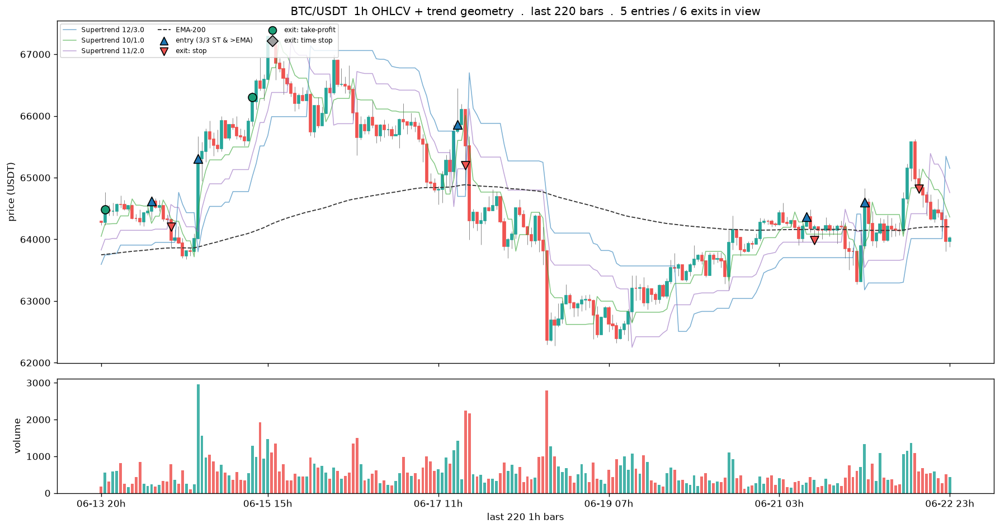

BTC/USDT: 1145 trades total  .  5 entries / 6 exits in the 220-bar window


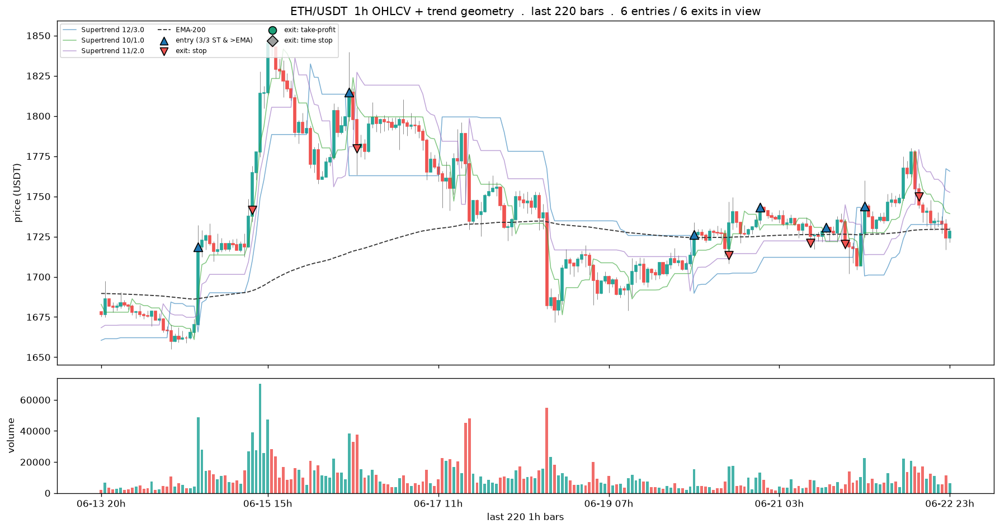

ETH/USDT: 1166 trades total  .  6 entries / 6 exits in the 220-bar window


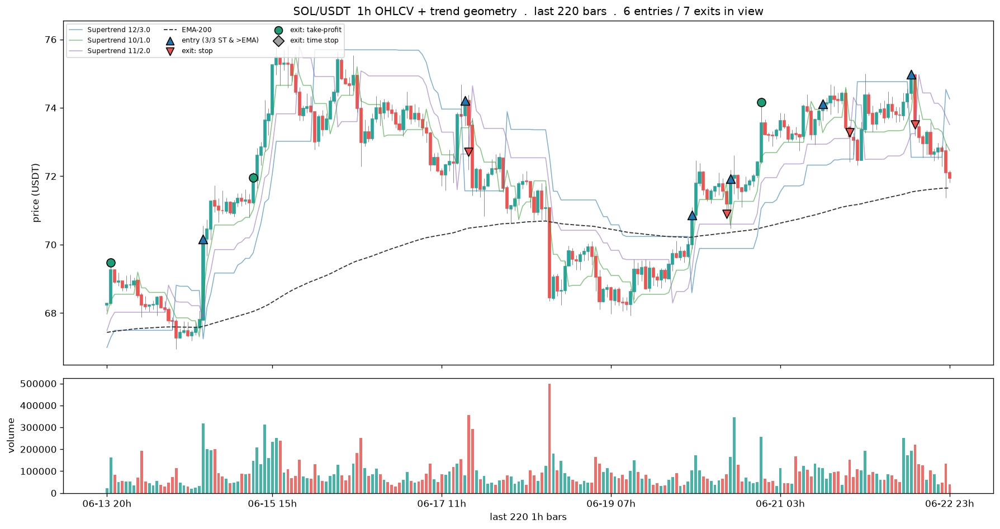

SOL/USDT: 820 trades total  .  6 entries / 7 exits in the 220-bar window


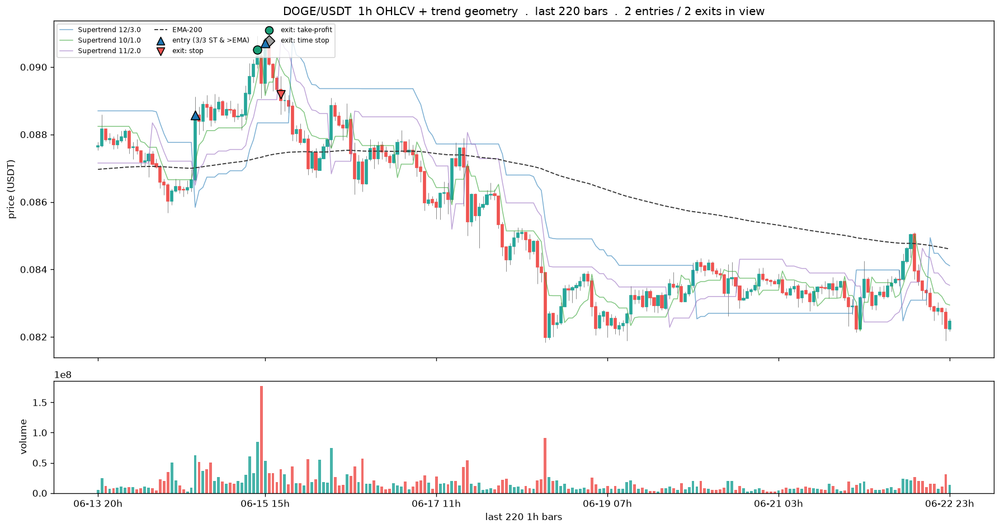

DOGE/USDT: 804 trades total  .  2 entries / 2 exits in the 220-bar window


In [31]:
# --- OHLCV candles + trend geometry across select coins -------------------------------
# A clean overview of WHAT the model trades, before the per-barrier zooms below: real OHLCV
# candlesticks (price + volume) for several coins, each with the trend geometry the entry rule
# reads -- the three Supertrend trailing bands and the EMA-200 filter -- and the entry/exit
# points marked on the bars. Entry triangles fire where all three bands agree on an uptrend and
# price holds above EMA-200; exits are coloured by the barrier that closed the trade. The entry +
# exit mechanics are the SAME functions the exit-geometry sweep runs (exit_geometry_viz), so the
# picture and the scoreboard cannot drift. The candle/volume/trend drawing is kept inline so the
# notebook stands on its own.
import exit_geometry_viz as egv

GALLERY_COINS  = ["BTC/USDT", "ETH/USDT", "SOL/USDT", "DOGE/USDT"]   # any coins with klines on disk
GALLERY_FRAME  = 1            # interval hours (1 = 1h, matches the loaded dataset; 4 = 4h)
GALLERY_WINDOW = 220          # candles to show for legibility; markers are those inside the window
GALLERY_CFG    = dict(stop_mult=2.0, tp_atr=3.0, trail=2.0, tp_decay=False)   # one exit geometry
GALLERY_FEE    = 0.001        # 10 bps per side

_BAND_COL = ["#1f77b4", "#2ca02c", "#9467bd"]                         # the three Supertrend bands
_EXIT_STYLE = {"stop": ("#ef5350", "v", "stop"),                     # marker colour, shape, label
               "tp":   ("#1b9e77", "o", "take-profit"),
               "time": ("#9e9e9e", "D", "time stop")}

def ohlcv_trend_panel(symbol, frame=GALLERY_FRAME, window=GALLERY_WINDOW,
                      cfg=GALLERY_CFG, fee=GALLERY_FEE):
    """Draw one coin: OHLCV candles + Supertrend bands + EMA-200 + entry/exit markers, volume below."""
    bd.configure(frame)                                              # 1h or 4h feature/label geometry
    max_hold = bd.LABEL["horizon_bars"] * 4
    o = bd.load_coin(bd.DEFAULT_KLINES_ROOT, symbol.replace("/", "")).reset_index(drop=True)
    if o.empty:
        print(f"no klines for {symbol} under {bd.DEFAULT_KLINES_ROOT}"); return
    lines, ema, entries, ups = egv.compute_trend(o)                  # 3 Supertrend bands + EMA-200 + entry mask
    trades, _ = egv.simulate_with_path(o, entries, cfg, fee, max_hold)   # which barrier each trade hit

    n = len(o); s = max(0, n - window); e = n - 1; x = np.arange(s, e + 1)
    op, cl = o["open"].to_numpy(), o["close"].to_numpy()
    hi, lo, vol = o["high"].to_numpy(), o["low"].to_numpy(), o["volume"].to_numpy()
    up = cl >= op                                                    # green/red per candle

    fig, (axp, axv) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1]})
    # OHLC candles: wick = high-low line, body = open-close rectangle
    axp.vlines(x, lo[s:e + 1], hi[s:e + 1], color="#888", lw=0.6, zorder=1)
    for k in range(s, e + 1):
        axp.add_patch(plt.Rectangle((k - 0.3, min(op[k], cl[k])), 0.6, max(abs(cl[k] - op[k]), 1e-9),
                      color="#26a69a" if up[k] else "#ef5350", zorder=2))
    # trend geometry: the bands the entry rule reads
    for li, ln in enumerate(lines):
        axp.plot(x, np.asarray(ln)[s:e + 1], lw=0.9, alpha=0.6, color=_BAND_COL[li],
                 label=f"Supertrend {bd.ST_BANDS[li][0]}/{bd.ST_BANDS[li][1]}")
    axp.plot(x, ema[s:e + 1], color="#333", lw=1.1, ls="--", label=f"EMA-{bd.ST_EMA}")
    # entry / exit points that fall inside the window
    ne = nx = 0
    for t in trades:
        if s <= t["i"] <= e:
            axp.scatter([t["i"]], [t["entry"]], marker="^", s=90, color="#1f77b4",
                        edgecolor="k", zorder=6); ne += 1
        if s <= t["j"] <= e:
            col, mk, _ = _EXIT_STYLE[t["reason"]]
            axp.scatter([t["j"]], [t["exit"]], marker=mk, s=80, color=col,
                        edgecolor="k", zorder=6); nx += 1
    axp.scatter([], [], marker="^", s=70, color="#1f77b4", edgecolor="k", label="entry (3/3 ST & >EMA)")
    for r, (col, mk, lab) in _EXIT_STYLE.items():
        axp.scatter([], [], marker=mk, s=70, color=col, edgecolor="k", label=f"exit: {lab}")
    axp.set_title(f"{symbol}  {bd.INTERVAL} OHLCV + trend geometry  .  last {window} bars  .  "
                  f"{ne} entries / {nx} exits in view")
    axp.set_ylabel("price (USDT)"); axp.legend(loc="upper left", fontsize=7, ncol=3)
    # volume, coloured by candle direction
    axv.bar(x, vol[s:e + 1], width=0.7, alpha=0.85,
            color=np.where(up[s:e + 1], "#26a69a", "#ef5350"))
    axv.set_ylabel("volume")
    ticks = np.linspace(s, e, 6).astype(int)
    axv.set_xticks(ticks)
    axv.set_xticklabels([f"{o['datetime'].iloc[k]:%m-%d %Hh}" for k in ticks])
    axv.set_xlabel(f"last {window} {bd.INTERVAL} bars")
    fig.tight_layout()
    (OUTPUTS / "PNG").mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUTS / "PNG" / f"3-ohlcv-trend-{symbol.replace('/', '')}.png", dpi=150)
    show_fig(fig)
    print(f"{symbol}: {len(trades)} trades total  .  {ne} entries / {nx} exits in the {window}-bar window")

_prev_frame = bd.INTERVAL_HOURS                                      # restore the notebook's frame after
try:
    for _sym in GALLERY_COINS:
        ohlcv_trend_panel(_sym)
finally:
    bd.configure(_prev_frame)                                        # leave bd as the rest of the nb expects

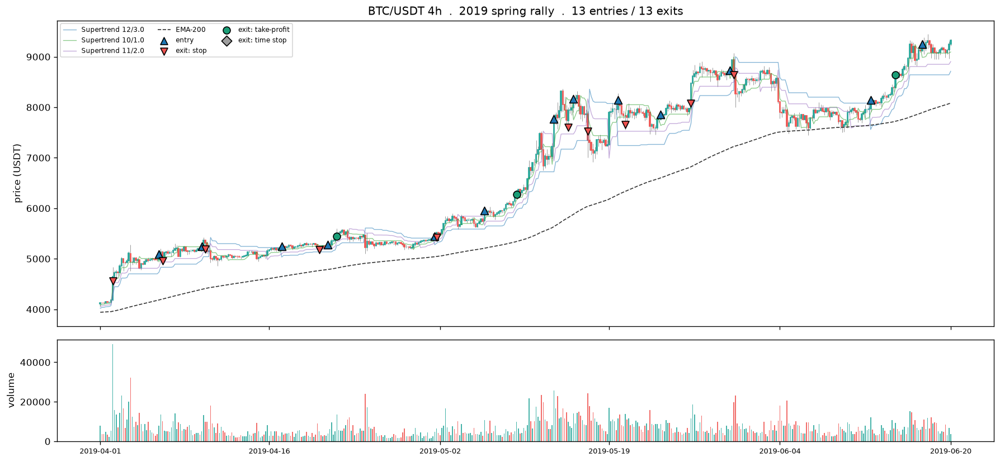

2019 spring rally                  2019-04-01 -> 2019-06-20   13 entries / 13 exits


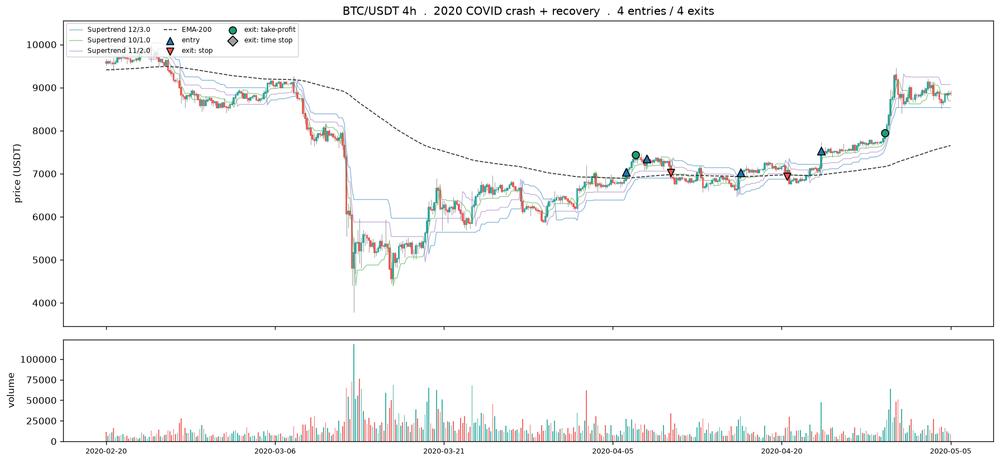

2020 COVID crash + recovery        2020-02-20 -> 2020-05-05   4 entries / 4 exits


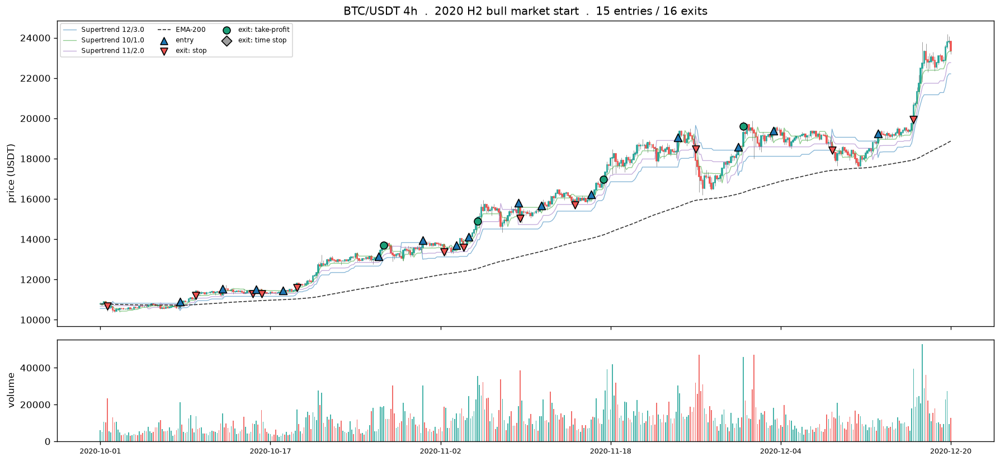

2020 H2 bull market start          2020-10-01 -> 2020-12-20   15 entries / 16 exits


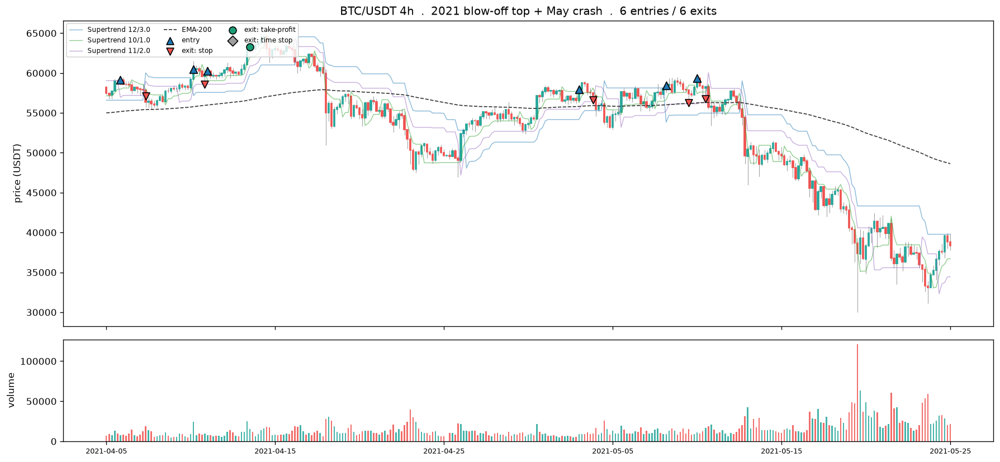

2021 blow-off top + May crash      2021-04-05 -> 2021-05-25   6 entries / 6 exits


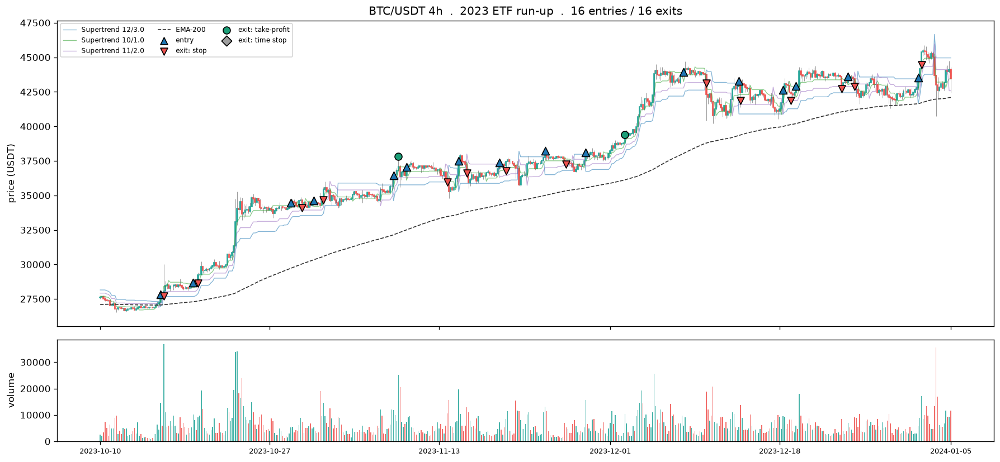

2023 ETF run-up                    2023-10-10 -> 2024-01-05   16 entries / 16 exits


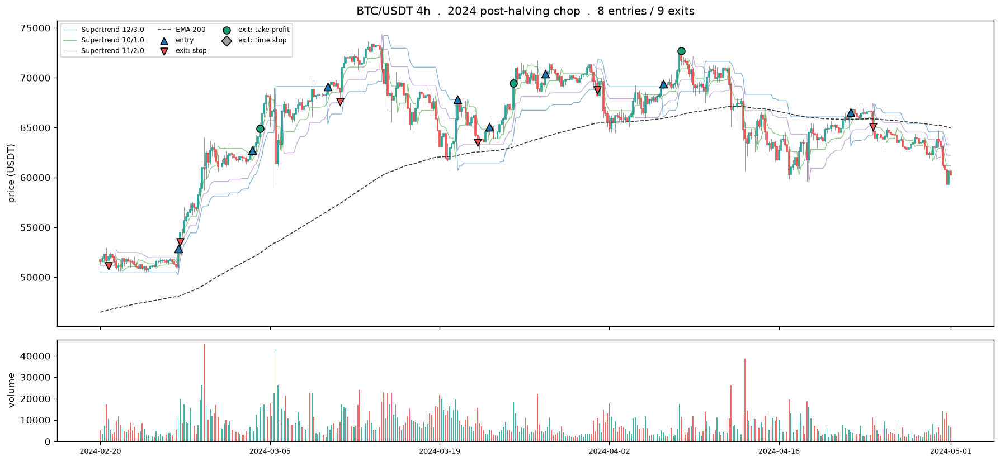

2024 post-halving chop             2024-02-20 -> 2024-05-01   8 entries / 9 exits

note: the 2022 LUNA/bear leg is omitted because the rule fires ZERO entries there -- it stands aside
when no uptrend exists, which is itself the correct (and only safe) behaviour.


In [32]:
# --- Entries/exits across history: shared drawing helpers + the across-years walk --------
# Leaves the recent-window gallery to show the SAME Supertrend+EMA entry/exit rule across regimes.
# The helpers defined here are reused by the two cells below, so run this block first. Each cell
# loads + computes its own coin/frame (cheap) and restores bd's frame on exit, so the per-barrier
# cells further down are unaffected. Entry/exit mechanics are exit_geometry_viz, identical to the
# after-fee scoreboard, so the picture cannot drift from the numbers.
import exit_geometry_viz as egv

HIST_SYMBOL = "BTC/USDT"                                          # longest history; the canonical regimes
HIST_CFG    = dict(stop_mult=2.0, tp_atr=3.0, trail=2.0, tp_decay=False)
HIST_FEE    = 0.001
_HBAND = ["#1f77b4", "#2ca02c", "#9467bd"]
_HEXIT = {"stop": ("#ef5350", "v", "stop"), "tp": ("#1b9e77", "o", "take-profit"),
          "time": ("#9e9e9e", "D", "time stop")}

def hist_setup(symbol, frame):
    """Load a coin at a frame; compute the trend, the trades, and per-bar trend context once."""
    bd.configure(frame)
    o = bd.load_coin(bd.DEFAULT_KLINES_ROOT, symbol.replace("/", "")).reset_index(drop=True)
    if o.empty:
        print(f"no klines for {symbol} at {bd.INTERVAL}"); return None
    lines, ema, entries, ups = egv.compute_trend(o)
    trades, atrp = egv.simulate_with_path(o, entries, HIST_CFG, HIST_FEE, bd.LABEL["horizon_bars"] * 4)
    ctx = egv.trend_context(o, ups, ema)
    return dict(o=o, lines=lines, ema=ema, trades=trades, atrp=atrp, ctx=ctx)

def _hist_candles(ax, o, s, e):                                   # OHLC candles, body width adapts to density
    op, cl, hi, lo = (o[c].to_numpy() for c in ("open", "close", "high", "low"))
    bw = 0.6 if (e - s) < 300 else (0.5 if (e - s) < 600 else 0.4)
    ax.vlines(np.arange(s, e + 1), lo[s:e + 1], hi[s:e + 1], color="#888", lw=0.5, zorder=1)
    for k in range(s, e + 1):
        ax.add_patch(plt.Rectangle((k - bw / 2, min(op[k], cl[k])), bw, max(abs(cl[k] - op[k]), 1e-9),
                     color="#26a69a" if cl[k] >= op[k] else "#ef5350", zorder=2))
    return bw

def hist_panel(H, s, e, title):
    """OHLCV candles + the three Supertrend bands + EMA-200 + entry/exit markers over [s, e]."""
    o, lines, ema, trades = H["o"], H["lines"], H["ema"], H["trades"]
    s = max(0, s); e = min(len(o) - 1, e); x = np.arange(s, e + 1)
    fig, (axp, axv) = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    bw = _hist_candles(axp, o, s, e)
    for li, ln in enumerate(lines):
        axp.plot(x, np.asarray(ln)[s:e + 1], lw=0.8, alpha=0.55, color=_HBAND[li],
                 label=f"Supertrend {bd.ST_BANDS[li][0]}/{bd.ST_BANDS[li][1]}")
    axp.plot(x, ema[s:e + 1], color="#333", lw=1.0, ls="--", label=f"EMA-{bd.ST_EMA}")
    ne = nx = 0
    for t in trades:
        if s <= t["i"] <= e:
            axp.scatter([t["i"]], [t["entry"]], marker="^", s=70, color="#1f77b4", edgecolor="k", zorder=6); ne += 1
        if s <= t["j"] <= e:
            col, mk, _ = _HEXIT[t["reason"]]
            axp.scatter([t["j"]], [t["exit"]], marker=mk, s=60, color=col, edgecolor="k", zorder=6); nx += 1
    axp.scatter([], [], marker="^", s=60, color="#1f77b4", edgecolor="k", label="entry")
    for r, (col, mk, lab) in _HEXIT.items():
        axp.scatter([], [], marker=mk, s=60, color=col, edgecolor="k", label=f"exit: {lab}")
    axp.set_title(f"{title}  .  {ne} entries / {nx} exits"); axp.set_ylabel("price (USDT)")
    axp.legend(loc="upper left", fontsize=7, ncol=3)
    up = o["close"].to_numpy() >= o["open"].to_numpy()
    axv.bar(x, o["volume"].to_numpy()[s:e + 1], width=max(bw, 0.5), alpha=0.85,
            color=np.where(up[s:e + 1], "#26a69a", "#ef5350")); axv.set_ylabel("volume")
    tk = np.linspace(s, e, 6).astype(int); axv.set_xticks(tk)
    axv.set_xticklabels([f"{o['datetime'].iloc[k]:%Y-%m-%d}" for k in tk], fontsize=8)
    fig.tight_layout(); show_fig(fig)
    return ne, nx

def hist_critical(H, t, title):
    """Zoom one trade: candles + volume + the trailing-stop/take-profit path + the entry's trend drivers."""
    o, lines, ema, ctx, atrp = H["o"], H["lines"], H["ema"], H["ctx"], H["atrp"]
    s = max(0, t["i"] - 30); e = min(len(o) - 1, t["j"] + 15); x = np.arange(s, e + 1)
    fig, (ax, axv) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})
    bw = _hist_candles(ax, o, s, e)
    for li, ln in enumerate(lines):
        ax.plot(x, np.asarray(ln)[s:e + 1], lw=0.8, alpha=0.5, color=_HBAND[li])
    ax.plot(x, ema[s:e + 1], color="#333", lw=1.0, ls="--", label=f"EMA-{bd.ST_EMA}")
    jx = np.arange(t["i"] + 1, t["i"] + 1 + len(t["spath"]))
    ax.plot(jx, t["spath"], color="#d95f02", lw=1.6, drawstyle="steps-post", label="trailing stop")
    if np.isfinite(t["tpath"]).any():
        ax.plot(jx, t["tpath"], color="#1b9e77", lw=1.0, ls=":", label="take-profit")
    ax.scatter([t["i"]], [t["entry"]], marker="^", s=130, color="#1f77b4", edgecolor="k", zorder=6)
    col, mk, lab = _HEXIT[t["reason"]]
    ax.scatter([t["j"]], [t["exit"]], marker=mk, s=130, color=col, edgecolor="k", zorder=6)
    why = (f"entry {o['datetime'].iloc[t['i']]:%Y-%m-%d %Hh}\n"
           f"Supertrend {ctx['agree'][t['i']]}/3 agree\n"
           f"price {'above' if ctx['ema_up'][t['i']] else 'below'} rising EMA-200\n"
           f"RSI {ctx['rsi'][t['i']]:.0f}   ATR {atrp[t['i']] * 100:.1f}%")
    ax.annotate(why, (t["i"], t["entry"]), textcoords="offset points", xytext=(8, -82), fontsize=8,
                color="#1f77b4", bbox=dict(boxstyle="round", fc="#eef4fb", ec="#1f77b4", alpha=0.9))
    ax.annotate(f"{lab} exit  {t['ret'] * 100:+.1f}%", (t["j"], t["exit"]), textcoords="offset points",
                xytext=(6, 12), fontsize=9, color=col)
    ax.set_title(f"{title}  .  {lab} exit  {t['ret'] * 100:+.1f}%"); ax.set_ylabel("price (USDT)")
    ax.legend(loc="upper left", fontsize=8)
    upc = o["close"].to_numpy() >= o["open"].to_numpy()
    axv.bar(x, o["volume"].to_numpy()[s:e + 1], width=max(bw, 0.5), alpha=0.85,
            color=np.where(upc[s:e + 1], "#26a69a", "#ef5350")); axv.set_ylabel("volume")
    tk = np.linspace(s, e, 5).astype(int); axv.set_xticks(tk)
    axv.set_xticklabels([f"{o['datetime'].iloc[k]:%m-%d %Hh}" for k in tk], fontsize=8)
    fig.tight_layout(); show_fig(fig)

# --- the across-years walk: one BTC episode per panel, drawn on the 4h frame --------------
_prev_frame = bd.INTERVAL_HOURS
try:
    H = hist_setup(HIST_SYMBOL, 4)
    _dts = H["o"]["datetime"].values.astype("datetime64[ns]")
    def _i(d): return int(np.searchsorted(_dts, np.datetime64(d)))
    EPOCHS = [
        ("2019 spring rally",             "2019-04-01", "2019-06-20"),
        ("2020 COVID crash + recovery",   "2020-02-20", "2020-05-05"),
        ("2020 H2 bull market start",     "2020-10-01", "2020-12-20"),
        ("2021 blow-off top + May crash", "2021-04-05", "2021-05-25"),
        ("2023 ETF run-up",               "2023-10-10", "2024-01-05"),
        ("2024 post-halving chop",        "2024-02-20", "2024-05-01"),
    ]
    for name, a, b in EPOCHS:
        ne, nx = hist_panel(H, _i(a), _i(b), f"{HIST_SYMBOL} 4h  .  {name}")
        print(f"{name:34s} {a} -> {b}   {ne} entries / {nx} exits")
    print("\nnote: the 2022 LUNA/bear leg is omitted because the rule fires ZERO entries there -- it "
          "stands aside\nwhen no uptrend exists, which is itself the correct (and only safe) behaviour.")
finally:
    bd.configure(_prev_frame)                                    # leave bd as the rest of the notebook expects

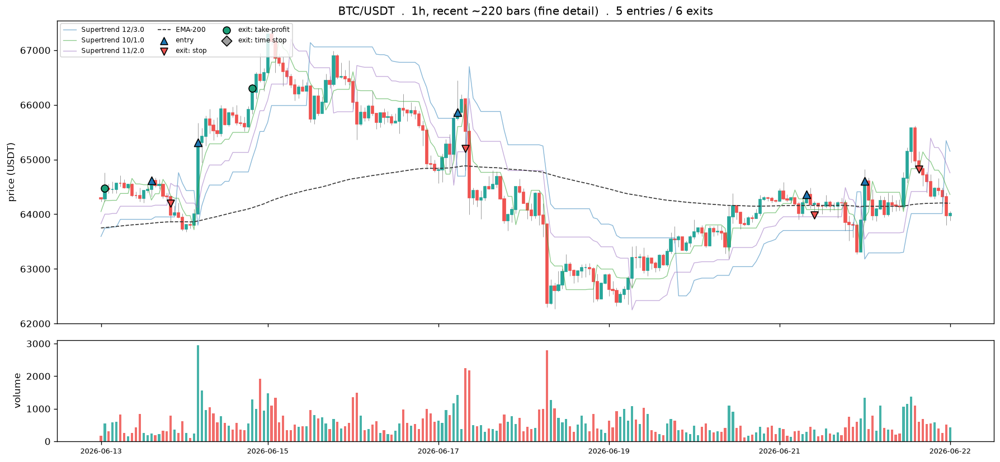

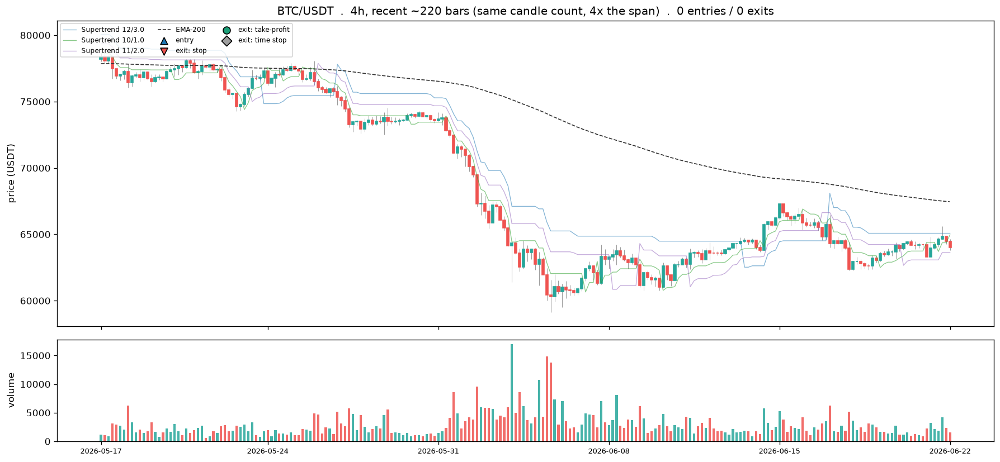

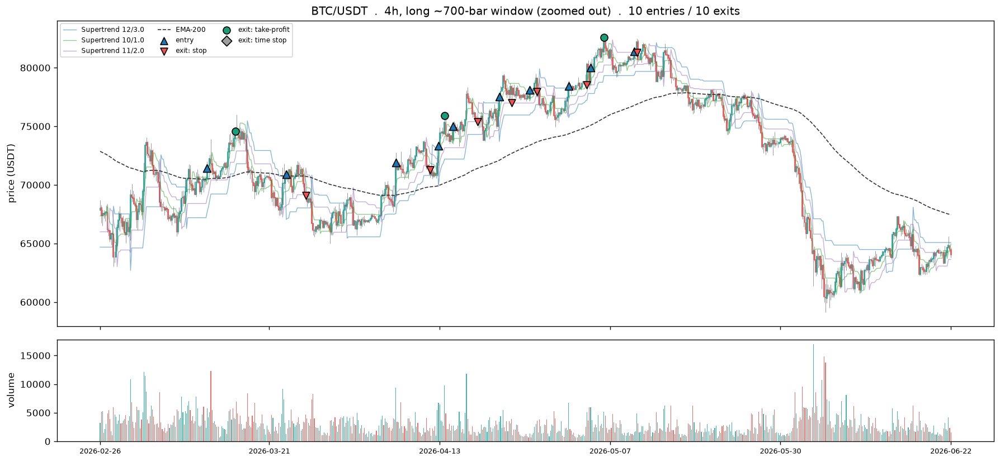

1h vs 4h at equal candle count is lever 1 (frame); 220 vs 700 on 4h is lever 2 (window). Past ~900 candles, step to a coarser frame rather than zoom further.


In [33]:
# --- The same rule at different timeline lengths -----------------------------------------
# Lever 1: change frame (1h -> 4h) keeps the candle count but multiplies the span at equal legibility.
# Lever 2: widen the window on one frame. hist_setup / hist_panel come from the across-years cell
# above, so run that one first.
_prev_frame = bd.INTERVAL_HOURS
try:
    for frame, nbars, tag in [(1, 220, "1h, recent ~220 bars (fine detail)"),
                              (4, 220, "4h, recent ~220 bars (same candle count, 4x the span)")]:
        H = hist_setup(HIST_SYMBOL, frame); n = len(H["o"])
        hist_panel(H, n - nbars, n - 1, f"{HIST_SYMBOL}  .  {tag}")
    H = hist_setup(HIST_SYMBOL, 4); n = len(H["o"])              # lever 2: long window, same 4h frame
    hist_panel(H, n - 700, n - 1, f"{HIST_SYMBOL}  .  4h, long ~700-bar window (zoomed out)")
    print("1h vs 4h at equal candle count is lever 1 (frame); 220 vs 700 on 4h is lever 2 (window). "
          "Past ~900 candles, step to a coarser frame rather than zoom further.")
finally:
    bd.configure(_prev_frame)

from 282 BTC 4h trades  .  best +15.5%  /  worst -8.7%


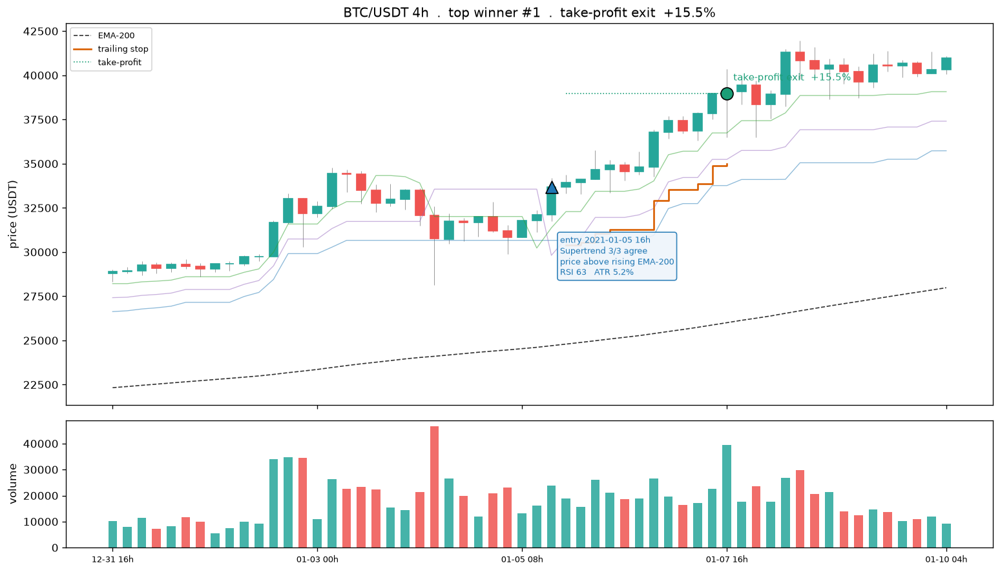

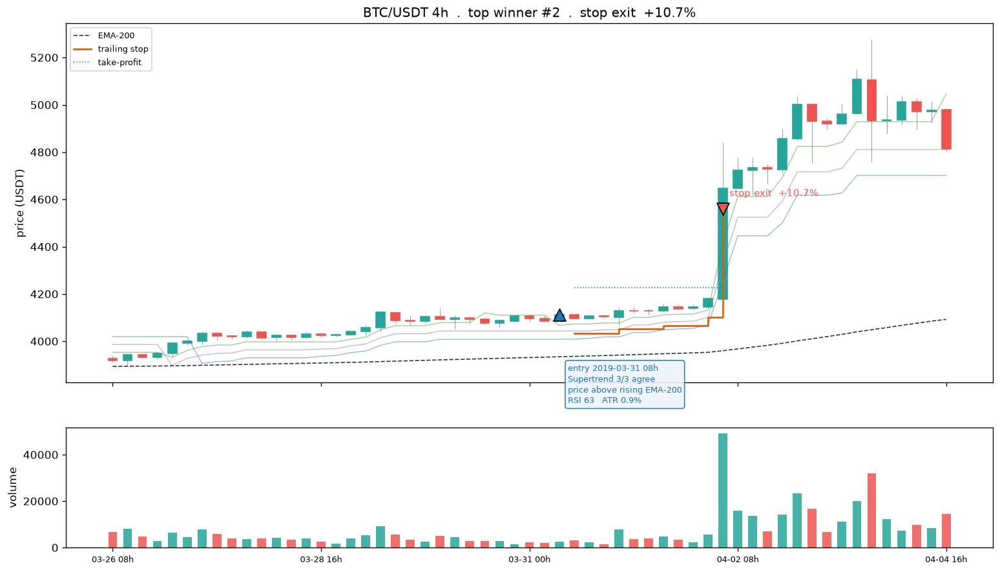

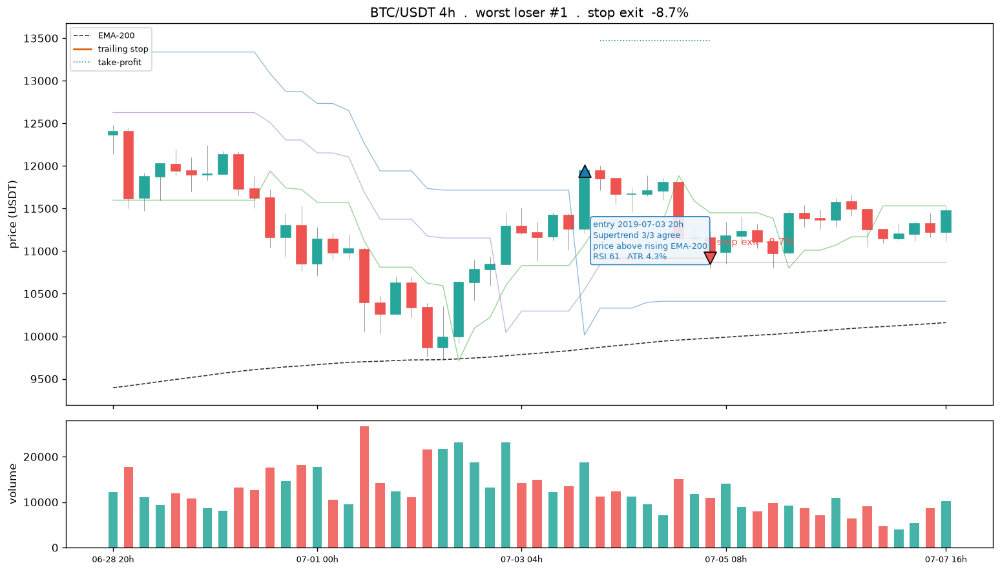

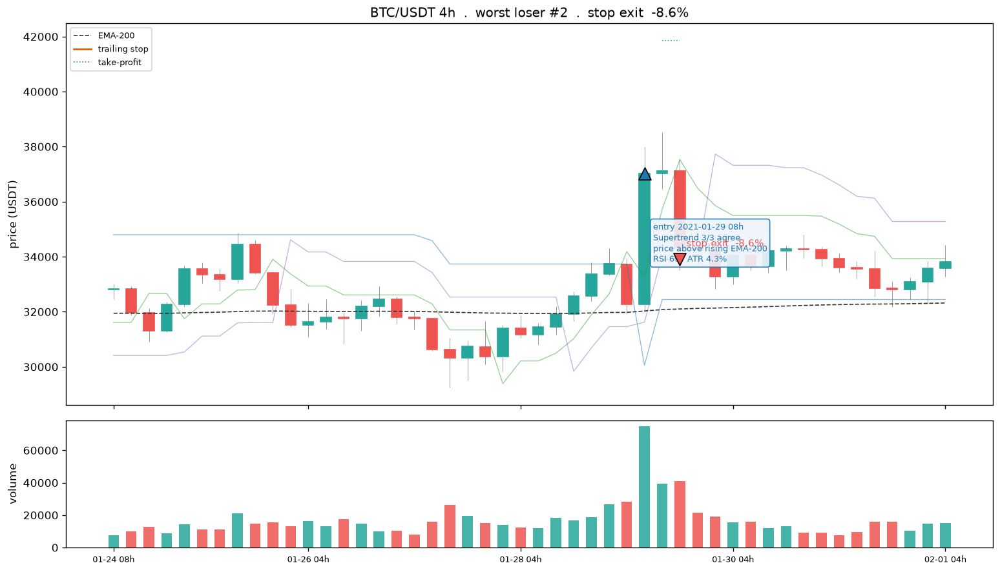

In [34]:
# --- Critical entries and exits, and why the signal fired --------------------------------
# The largest winners and losers by after-fee return, each zoomed in with the trend drivers that
# fired the entry and the barrier that closed it. Helpers come from the across-years cell above.
_prev_frame = bd.INTERVAL_HOURS
try:
    H = hist_setup(HIST_SYMBOL, 4)
    ranked = sorted(H["trades"], key=lambda t: t["ret"])
    winners, losers = ranked[-2:][::-1], ranked[:2]              # 2 biggest gains, 2 biggest losses
    print(f"from {len(H['trades'])} BTC 4h trades  .  best {winners[0]['ret']*100:+.1f}%  /  "
          f"worst {losers[0]['ret']*100:+.1f}%")
    for rank, t in enumerate(winners, 1):
        hist_critical(H, t, f"{HIST_SYMBOL} 4h  .  top winner #{rank}")
    for rank, t in enumerate(losers, 1):
        hist_critical(H, t, f"{HIST_SYMBOL} 4h  .  worst loser #{rank}")
finally:
    bd.configure(_prev_frame)

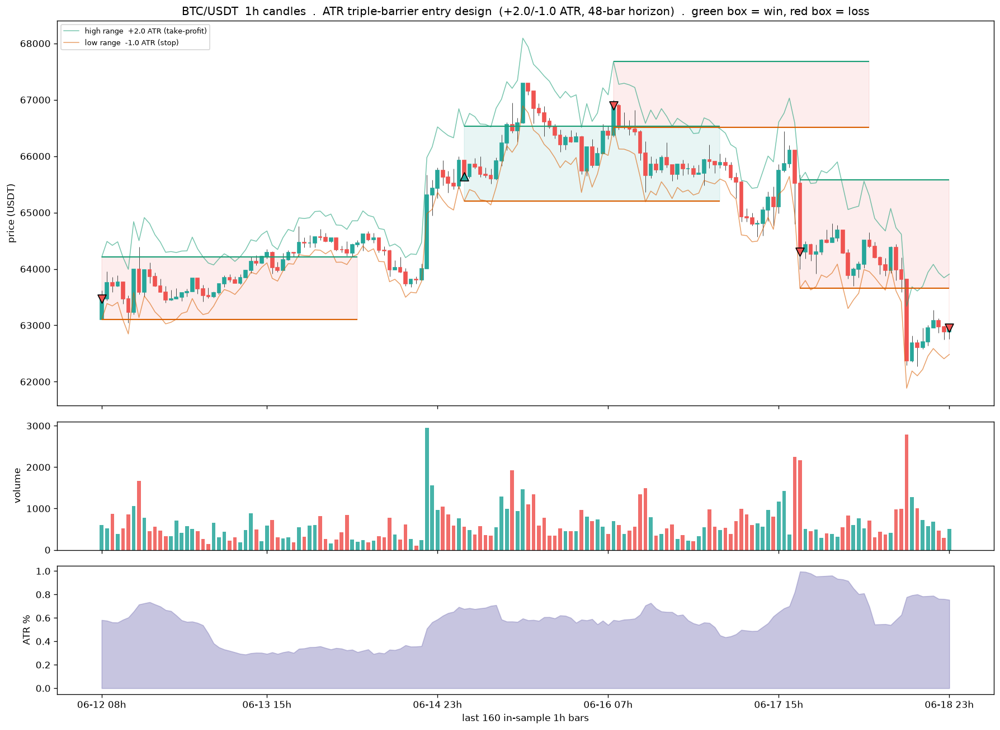

window 2026-06-12 08h -> 2026-06-18 23h  |  111 labelled entries, 35 wins (32%), base rate 31%


In [35]:
# --- Entry design on real candles: the ATR triple-barrier the labeller draws ----------
# Reload raw OHLC (the dataset keeps features+label, not price), recompute the per-bar
# high range (+tgt ATR take-profit) and low range (-stp ATR stop), and overlay the barrier
# box for a handful of entries coloured by outcome. This is the picture of "where we enter".
ENTRY_SYMBOL = "BTC/USDT"     # any coin in df; the kline folder form just drops the slash
WINDOW_BARS  = 160            # number of 1h candles to show
N_ENTRIES    = 5              # entries to annotate with their full barrier box

if df is not None:
    lab = bd.LABEL
    folder = ENTRY_SYMBOL.replace("/", "")
    ohlc = bd.load_coin(bd.DEFAULT_KLINES_ROOT, folder).reset_index(drop=True)
    if ohlc.empty:
        print(f"no raw klines for {folder} under {bd.DEFAULT_KLINES_ROOT}")
    else:
        atr = bd._atr_pct(ohlc, lab["atr_len"]) / 100.0                    # per-bar ATR fraction
        ohlc["hi_range"] = ohlc["close"] * (1 + lab["tgt_atr"] * atr)      # upper barrier (take-profit)
        ohlc["lo_range"] = ohlc["close"] * (1 - lab["stp_atr"] * atr)      # lower barrier (stop)
        labels = df.loc[df["symbol"] == ENTRY_SYMBOL, ["datetime", "label", "trade_ret"]]
        ohlc = ohlc.merge(labels, on="datetime", how="left")               # realised win/loss per bar
        valid = ohlc.dropna(subset=["label"])
        end = int(valid.index.max()); start = max(0, end - WINDOW_BARS + 1)
        win = ohlc.iloc[start:end + 1].reset_index(drop=True)
        x = np.arange(len(win))

        def _candles(ax, w, xs):                                           # OHLC bars without mplfinance
            ax.vlines(xs, w["low"], w["high"], color="#444", linewidth=0.6, zorder=1)
            for i in xs:
                o, c = w["open"].iloc[i], w["close"].iloc[i]
                ax.add_patch(plt.Rectangle((i - 0.3, min(o, c)), 0.6, max(abs(c - o), 1e-9),
                             color=("#26a69a" if c >= o else "#ef5350"), zorder=2))

        fig, (ax1, axv, ax2) = plt.subplots(3, 1, figsize=(15, 11), sharex=True,
                                            gridspec_kw={"height_ratios": [3, 1, 1]})
        _candles(ax1, win, x)
        ax1.plot(x, win["hi_range"], color="#1b9e77", lw=0.9, alpha=0.6,
                 label=f"high range  +{lab['tgt_atr']} ATR (take-profit)")
        ax1.plot(x, win["lo_range"], color="#d95f02", lw=0.9, alpha=0.6,
                 label=f"low range  -{lab['stp_atr']} ATR (stop)")
        ent = win.index[win["label"].notna()].tolist()
        for k in np.linspace(0, len(ent) - 1, min(N_ENTRIES, len(ent))).astype(int):
            t = ent[k]; c = win["close"].iloc[t]
            tgt, stp = win["hi_range"].iloc[t], win["lo_range"].iloc[t]
            won = win["label"].iloc[t] == 1
            wdt = min(lab["horizon_bars"], len(win) - 1 - t)               # box width = horizon, clipped
            col = "#26a69a" if won else "#ef5350"
            ax1.add_patch(plt.Rectangle((t, stp), wdt, tgt - stp, alpha=0.10, color=col, zorder=0))
            ax1.hlines(tgt, t, t + wdt, color="#1b9e77", lw=1.3, zorder=3)
            ax1.hlines(stp, t, t + wdt, color="#d95f02", lw=1.3, zorder=3)
            ax1.scatter([t], [c], marker="^" if won else "v", s=80, color=col, edgecolor="k", zorder=4)
        ax1.set_title(f"{ENTRY_SYMBOL}  1h candles  .  ATR triple-barrier entry design  "
                      f"(+{lab['tgt_atr']}/-{lab['stp_atr']} ATR, {lab['horizon_bars']}-bar horizon)  "
                      f".  green box = win, red box = loss")
        ax1.set_ylabel("price (USDT)"); ax1.legend(loc="upper left", fontsize=8)
        upc = (win["close"] >= win["open"]).to_numpy()
        axv.bar(x, win["volume"].to_numpy(), width=0.7, alpha=0.85,
                color=np.where(upc, "#26a69a", "#ef5350")); axv.set_ylabel("volume")
        ax2.fill_between(x, 0, atr.iloc[start:end + 1].values * 100, color="#7570b3", alpha=0.4)
        ax2.set_ylabel("ATR %")
        ticks = np.linspace(0, len(win) - 1, 6).astype(int)
        ax2.set_xticks(ticks)
        ax2.set_xticklabels([f"{win['datetime'].iloc[i]:%m-%d %Hh}" for i in ticks])
        ax2.set_xlabel(f"last {len(win)} in-sample 1h bars")
        fig.tight_layout()
        (OUTPUTS / "PNG").mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUTS / "PNG" / "3-entry-design-candles.png", dpi=150)
        show_fig(fig)
        nwin = int(win["label"].eq(1).sum()); ntot = int(win["label"].notna().sum())
        print(f"window {win['datetime'].iloc[0]:%Y-%m-%d %Hh} -> {win['datetime'].iloc[-1]:%Y-%m-%d %Hh}"
              f"  |  {ntot} labelled entries, {nwin} wins ({nwin / max(ntot, 1):.0%}), "
              f"base rate {df.loc[df['symbol'] == ENTRY_SYMBOL, 'label'].mean():.0%}")
else:
    print("build/load the 1h dataset first (see Import Data).")


[single] BTC/USDT 1h: 1145 trades  exits: 181 TP / 963 stop / 1 time  mean net -0.35%/trade  -> /Volumes/PortableSSD/Github/day-trader/04-outputs/PNG/3-exit-geometry-candles.png


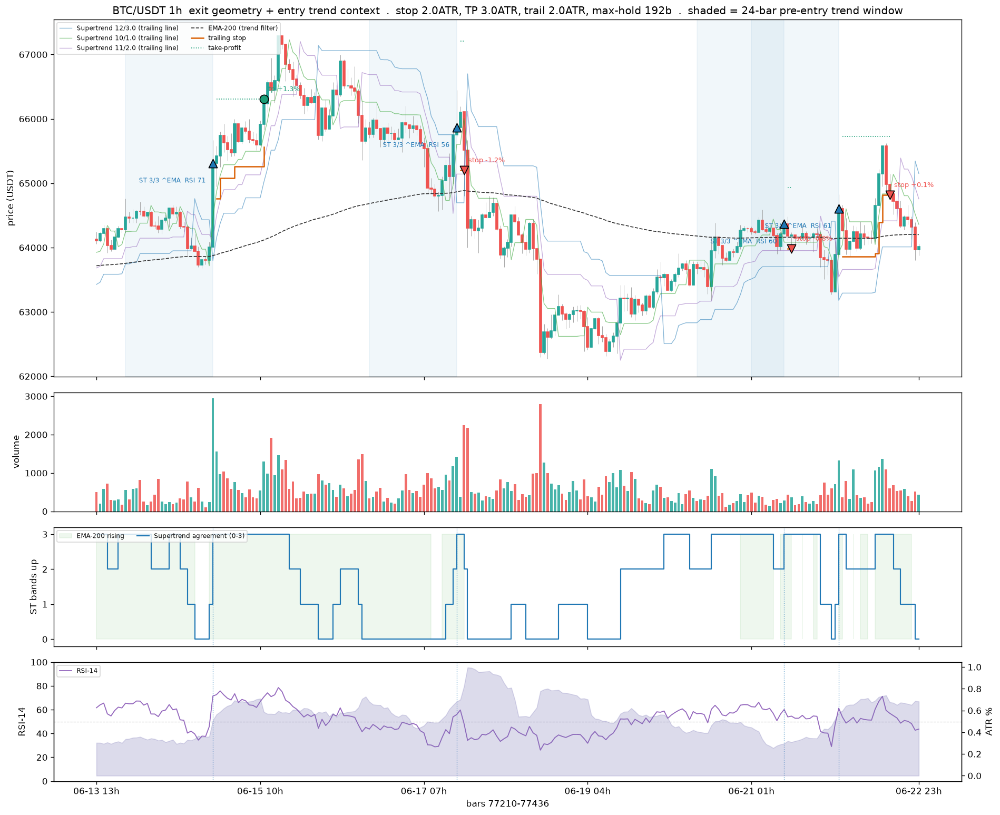

In [36]:
# --- Exit geometry on real candles + the trend data around each entry --------------------
# Heavy multi-panel rendering lives in 03-inputs/exit_geometry_viz.py (single source, also used by
# chapters 1 and 2). Here the pipeline stays legible: trend -> entries -> exit simulation -> plot.
import exit_geometry_viz as egv

EXIT_SYMBOL = "BTC/USDT"                                          # any coin with klines on disk
EXIT_CFG    = dict(stop_mult=2.0, tp_atr=3.0, trail=2.0, tp_decay=False)   # one exit configuration
FEE         = 0.001                                              # 10 bps per side
MAX_HOLD    = bd.LABEL["horizon_bars"] * 4                       # time stop, generous vs the label horizon

ohlc = bd.load_coin(bd.DEFAULT_KLINES_ROOT, EXIT_SYMBOL.replace("/", "")).reset_index(drop=True)
lines, ema, entries, ups = egv.compute_trend(ohlc)               # 3 Supertrend trailing lines + EMA-200 + entries
trades, atrp = egv.simulate_with_path(ohlc, entries, EXIT_CFG, FEE, MAX_HOLD)   # exit mechanics, path recorded
fig = egv.plot_single(ohlc, lines, ema, ups, trades, atrp, EXIT_CFG, MAX_HOLD, FEE,   # shaded pre-entry window,
                      f"{EXIT_SYMBOL} {bd.INTERVAL}",                                  # ST-agreement + RSI panels,
                      OUTPUTS / "PNG" / "3-exit-geometry-candles.png", show=False)     # entry trend annotations
show_fig(fig)                                                     # embed inline (Positron-safe)

[compare] BTC/USDT 1h: anchored on entry at bar 77414  -> /Volumes/PortableSSD/Github/day-trader/04-outputs/PNG/3-exit-geometry-compare.png


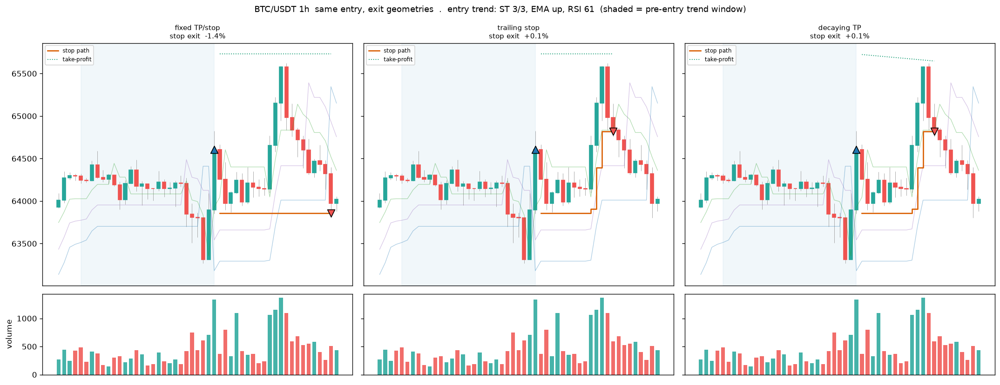

In [37]:
# --- Same entry, several exit geometries: how the shape changes where a trade exits ------
# Reuses ohlc / lines / ema / ups / entries from the Exit Geometry cell above.
COMPARE_CFGS = [("fixed TP/stop", dict(stop_mult=2.0, tp_atr=3.0, trail=0.0, tp_decay=False)),
                ("trailing stop", dict(stop_mult=2.0, tp_atr=3.0, trail=2.0, tp_decay=False)),
                ("decaying TP",   dict(stop_mult=2.0, tp_atr=3.0, trail=2.0, tp_decay=True))]
fig = egv.plot_compare(ohlc, lines, ema, ups, entries, COMPARE_CFGS, MAX_HOLD, FEE,
                       f"{EXIT_SYMBOL} {bd.INTERVAL}",
                       OUTPUTS / "PNG" / "3-exit-geometry-compare.png", show=False)
show_fig(fig)                                                     # embed inline (Positron-safe)

### 3.4 Sharpening Entries

An honest test of whether a sharper entry helps. Range and volatility entry conditions never pay, trend and momentum pay only marginally, and an early BTC-trend-gated entry that fires a few bars before the Supertrend flip lifts a single year to breakeven but does not survive walk-forward, positive in only a minority of folds. The conclusion carried through the rest of the chapter is that more price-derived entry features will not cross the fee line, which is why the search turns to cross-sectional framing and a coarser frame.

In [38]:
# --- Sharpening: which single conditions lift the win rate toward/over breakeven? ------
# Win rate by decile of the most label-separating features, against the barrier breakeven.
# Green decile clears breakeven (a sharper entry); the table ranks the best filters found.
if df is not None and feat:
    lab = bd.LABEL
    breakeven = lab["stp_atr"] / (lab["stp_atr"] + lab["tgt_atr"])         # gross win-rate breakeven
    base = df["label"].mean()
    m1, m0 = df[df.label == 1][feat].mean(), df[df.label == 0][feat].mean()
    sep = ((m1 - m0) / df[feat].std().replace(0, np.nan)).abs().sort_values(ascending=False)
    top = sep.head(8).index.tolist()
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
    rows = []
    for ax, f in zip(axes.ravel(), top):
        d = df[[f, "label"]].dropna()
        q = pd.qcut(d[f], 10, labels=False, duplicates="drop")
        wr = d.groupby(q)["label"].mean()
        ax.bar(wr.index, wr.values, color=np.where(wr.values >= breakeven, "#26a69a", "#ef5350"))
        ax.axhline(breakeven, color="k", ls="--", lw=1)
        ax.axhline(base, color="#888", ls=":", lw=1)
        ax.set_title(f, fontsize=8); ax.set_xticks([])
        rows.append((f, round(float(wr.max()), 3), round(float(wr.max() - breakeven), 3)))
    for a in (axes[0, 0], axes[1, 0]):
        a.set_ylabel("win rate")
    fig.suptitle(f"Win rate by feature decile  .  dashed = breakeven {breakeven:.3f}, "
                 f"dotted = base rate {base:.3f}  .  green decile clears breakeven")
    fig.tight_layout()
    (OUTPUTS / "PNG").mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUTS / "PNG" / "3-entry-sharpening.png", dpi=150)
    plt.show()
    tbl = (pd.DataFrame(rows, columns=["feature", "best_decile_winrate", "lift_over_breakeven"])
           .sort_values("lift_over_breakeven", ascending=False).reset_index(drop=True))
    print("Best single-feature entry filters (in-sample, GROSS of cost):")
    show_table(tbl)
    print(f"cost drag is ~{CONFIG['cost_pct']:.2f}% round trip; on a +{lab['tgt_atr']} ATR target a "
          f"win must clear breakeven by more than that to pay. ")
    if tbl["lift_over_breakeven"].max() <= 0:
        print("NONE clear breakeven gross -> 1h single-feature entries do not sharpen past the barrier math.")
        print("Matches the handover: sharpen via a coarser (4h+) frame and cross-sectional ranking, "
              "not more 1h features.")
else:
    print("build/load the 1h dataset first (see Import Data).")


Best single-feature entry filters (in-sample, GROSS of cost):


,feature,best_decile_winrate,lift_over_breakeven
0,f_ta_pta_vortex_diff,0.342,0.009
1,f_hr_mom_12,0.335,0.001
2,f_ta_dmi_diff,0.333,-0.000
3,f_ta_mfi,0.333,-0.000
4,f_ta_pta_cmo,0.331,-0.003
5,f_hr_rsi,0.331,-0.003
6,f_ta_pta_ppo_hist,0.327,-0.006
7,f_ta_pta_cksp_long_dist,0.323,-0.010


cost drag is ~0.20% round trip; on a +2.0 ATR target a win must clear breakeven by more than that to pay. 


### 3.5 Survivorship Pipeline

The three-stage pipeline that makes the panel survivorship-complete and point-in-time honest. Stage A crawls the `data.binance.vision` listing to enumerate every USDT pair ever listed, delisted coins included, and downloads them checksum-verified. Stage B profiles coverage, gaps, listing timelines, and liquidity to derive the usable start, the minimum history, and the purge and embargo. Stage C is the forward-chained walk-forward splitter with per-fold point-in-time universes and train-only transforms. This is the spine Parts 1 and 2 borrow their universe from.

In [39]:
# Stage A: prove the historical universe includes dead coins. Crawl is ~4s, no download here.
# (inputs/ is already on sys.path from the Environment cell.)
import acquire_vision as av

crawl = av.crawl_archive_symbols(quote='USDT', verbose=False)
uni = crawl['symbols']
print(f"historical USDT universe (incl. dead coins): {len(uni)} pairs "
      f"(+{len(crawl['leveraged'])} leveraged excluded)")

# Stage A.5 guard: known-delisted pairs MUST be present, else the list came from a live endpoint.
aud = av.audit_dead_coins(uni)

# Survivorship share vs a dated active snapshot (writes inputs/binance-data/exchange_info_snapshot_<date>.json).
active, snap_path = av.snapshot_exchange_info()
part = av.partition_survivorship(uni, active)
print(f"survivorship: {part['n_universe']} universe / {part['n_active']} active / "
      f"{part['n_delisted']} delisted = {part['delisted_share']:.1%} dead coins")
# The heavy pull (operator's Mac):  python inputs/acquire_vision.py download --interval 1h

historical USDT universe (incl. dead coins): 671 pairs (+52 leveraged excluded)
dead-coin audit: 10/10 known-delisted present in universe


snapshot: 487 active USDT pairs as of 2026-09-07 -> /Volumes/PortableSSD/Github/day-trader/03-inputs/binance-data/exchange_info_snapshot_2026-09-07.json
survivorship: 671 universe / 468 active / 203 delisted = 30.3% dead coins


In [40]:
# Stage B: panel profiling. Loads the persisted profile; BUILDS it on first run if absent
# (writes run-stamped artefacts under outputs/3A-training-test-data/panel-profile/). Rebuild with:
#     python inputs/profile_panel.py
# pp.latest_run() resolves the run dir PORTABLY: latest.txt records an absolute path, so on a
# different mount (the exFAT SSD remounting, a fresh checkout) that path is re-rooted under the
# current PROFILE_ROOT rather than read empty -- independent of the notebook's cwd.
import json, os, pandas as pd
import profile_panel as pp

run = pp.latest_run()
if run is None:
    print('No Stage B profile found -- building over the full klines_1h panel.')
    print('First run only; it streams every coin twice, so expect a few minutes...')
    pp.profile(root=pp.DEFAULT_KLINES_ROOT, out_root=pp.PROFILE_ROOT, make_plot=False)
    run = pp.latest_run()

md_tbl = pd.read_parquet(os.path.join(run, 'symbol_metadata.parquet'))
dec = json.load(open(os.path.join(run, 'decision_summary.json')))
print('profile run  :', run)
print('symbols      :', len(md_tbl), '| delisted share:', f"{dec['survivorship']['delisted_share']:.1%}")
print('usable start :', dec['usable_start_date'])
print('min history  :', dec['min_history_days'], 'days')
print('purge/embargo:', dec['purge_embargo_days'], 'days', f"({dec['purge_embargo_bars']} bars)")
print('point-of-entry:', dec['point_of_entry_rule'][:90], '...')
_view = md_tbl[['symbol', 'first_bar', 'last_bar', 'n_bars', 'coverage', 'max_gap_hours',
                'halt_flag', 'active']].head(10)
print(f'\nsymbol metadata (first 10 of {len(md_tbl)} rows):')
print(_view.to_string(index=False))          # text fallback: renders in every IDE
display(_view)

profile run  : /Volumes/PortableSSD/Github/day-trader/04-outputs/3A-training-test-data/panel-profile/2026-09-06T215959Z
symbols      : 600 | delisted share: 33.3%
usable start : 2019-04-01
min history  : 157 days
purge/embargo: 125 days (3000 bars)
point-of-entry: coin enters at its first valid bar (realistic; mirrors when trading would actually begin)  ...

symbol metadata (first 10 of 600 rows):
  symbol                 first_bar                  last_bar  n_bars  coverage  max_gap_hours  halt_flag  active
 ETHUSDT 2017-08-17 04:00:00+00:00 2026-06-22 23:00:00+00:00   77437    0.9984             75       True    True
 BTCUSDT 2017-08-17 04:00:00+00:00 2026-06-22 23:00:00+00:00   77437    0.9984             75       True    True
 BNBUSDT 2017-11-06 03:00:00+00:00 2026-06-22 23:00:00+00:00   75501    0.9984             75       True    True
 BCCUSDT 2017-11-11 08:00:00+00:00 2018-11-20 02:00:00+00:00    8805    0.9815            105       True   False
 NEOUSDT 2017-11-20 03:00:00+00:00

     symbol                 first_bar                  last_bar  n_bars  \
0   ETHUSDT 2017-08-17 04:00:00+00:00 2026-06-22 23:00:00+00:00   77437   
1   BTCUSDT 2017-08-17 04:00:00+00:00 2026-06-22 23:00:00+00:00   77437   
2   BNBUSDT 2017-11-06 03:00:00+00:00 2026-06-22 23:00:00+00:00   75501   
3   BCCUSDT 2017-11-11 08:00:00+00:00 2018-11-20 02:00:00+00:00    8805   
4   NEOUSDT 2017-11-20 03:00:00+00:00 2026-06-22 23:00:00+00:00   75165   
5   LTCUSDT 2017-12-13 03:00:00+00:00 2026-06-22 23:00:00+00:00   74613   
6  QTUMUSDT 2018-03-19 08:00:00+00:00 2026-06-22 23:00:00+00:00   72337   
7   ADAUSDT 2018-04-17 04:00:00+00:00 2026-06-22 23:00:00+00:00   71645   
8   XRPUSDT 2018-05-04 08:00:00+00:00 2024-06-30 23:00:00+00:00   53905   
9   EOSUSDT 2018-05-28 05:00:00+00:00 2025-05-26 02:00:00+00:00   61231   

   coverage  max_gap_hours  halt_flag  active  
0    0.9984             75       True    True  
1    0.9984             75       True    True  
2    0.9984             75    

In [41]:
# Stage C: the splitter draws usable_start + per-fold universes from the Stage B run above.
# Reuses `bd` (build_dataset_1h) from the Environment cell.
import wf_splitter as wf
print(wf.METHODOLOGY)
pb, lf, lh = wf.purge_embargo_bars()
print(f'purge/embargo = max(feature lookback {lf}, label horizon {lh}) = {pb} bars '
      f'= {wf.purge_embargo_days()} days')

df_wf = bd.read_frame(bd.DATASET_PATH)
if df_wf is not None:
    if 'in_sample' in df_wf.columns:
        df_wf = df_wf[df_wf['in_sample']].copy()
    sp = wf.WalkForwardSplitter(n_folds=5, test_days=120, scheme='expanding',
                                usable_start=wf.load_usable_start(),
                                universes=wf.load_universes())
    _folds = sp.fold_table(df_wf)   # per-fold spans + coin counts (C.5 composition audit)
    print(f'\nwalk-forward folds ({len(_folds)}):')
    print(_folds.to_string(index=False))      # text fallback: renders in every IDE
    display(_folds)
    # Regime-stability metrics (fits a model per fold; run on the .venv):
    # wf.evaluate_walkforward(df_wf, bd.feature_columns(df_wf), sp)
else:
    print('No dataset yet at', bd.DATASET_PATH)

## Splitting methodology: forward-chained, not stratified

Objective: estimate out-of-sample performance under REGIME DRIFT, not interpolation within a
known distribution. The data-generating process drifts across time -- the 2017-18 ICO mania,
the 2021 bull run, the 2022 deleveraging, and the current regime are different processes. A
split that interleaves test bars among training bars borrows the future to predict the past
and yields an error estimate that will not survive live trading.

Stratified sampling is rejected. Stratifying on variance forces similar class proportions
across splits by drawing observations regardless of position in time, which destroys the
temporal ordering that is the whole object of interest. It answers "can the model interpolate
within a known distribution"; the question that matters is "can it extrapolate forward into an
unknown regime." Only a forward-chained split measures that.

Design: expanding/rolling walk-forward on shared calendar boundaries; purge


walk-forward folds (5):
 fold train_start  train_end test_start   test_end  n_train  n_test  n_coins  embargo_days
    0  2019-04-01 2024-06-23 2024-10-26 2025-02-23   279036   28742       21           125
    1  2019-04-01 2024-10-21 2025-02-23 2025-06-23   302694   25482       19           125
    2  2019-04-01 2025-02-18 2025-06-23 2025-10-21   337209   31086       23           125
    3  2019-04-01 2025-06-18 2025-10-21 2026-02-18   364391   24993       21           125
    4  2019-04-01 2025-10-16 2026-02-18 2026-06-18   395181   16801       20           125


   fold train_start   train_end  test_start    test_end  n_train  n_test  \
0     0  2019-04-01  2024-06-23  2024-10-26  2025-02-23   279036   28742   
1     1  2019-04-01  2024-10-21  2025-02-23  2025-06-23   302694   25482   
2     2  2019-04-01  2025-02-18  2025-06-23  2025-10-21   337209   31086   
3     3  2019-04-01  2025-06-18  2025-10-21  2026-02-18   364391   24993   
4     4  2019-04-01  2025-10-16  2026-02-18  2026-06-18   395181   16801   

   n_coins  embargo_days  
0       21           125  
1       19           125  
2       23           125  
3       21           125  
4       20           125  

### 3.6 Variable Selection

Feature selection on the training window only, so the choice never sees the blind year. It ranks the candidate features and prunes the redundant and the near-zero-signal, keeping the causal, scale-invariant set the model trains on, with the after-fee out-of-sample scoreboard as the final arbiter of whether a family earns its place.

lasso path on 25,000 TRAIN rows x 61 features.
lambda.min=0.000494 (nonzero 45), lambda.1se=0.01121 (nonzero 0)


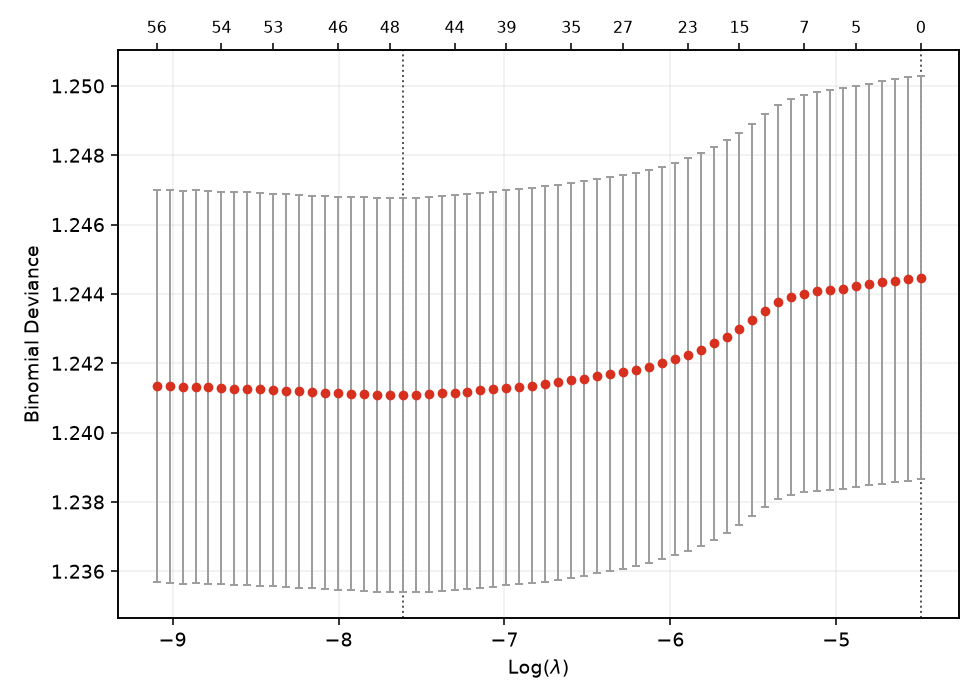

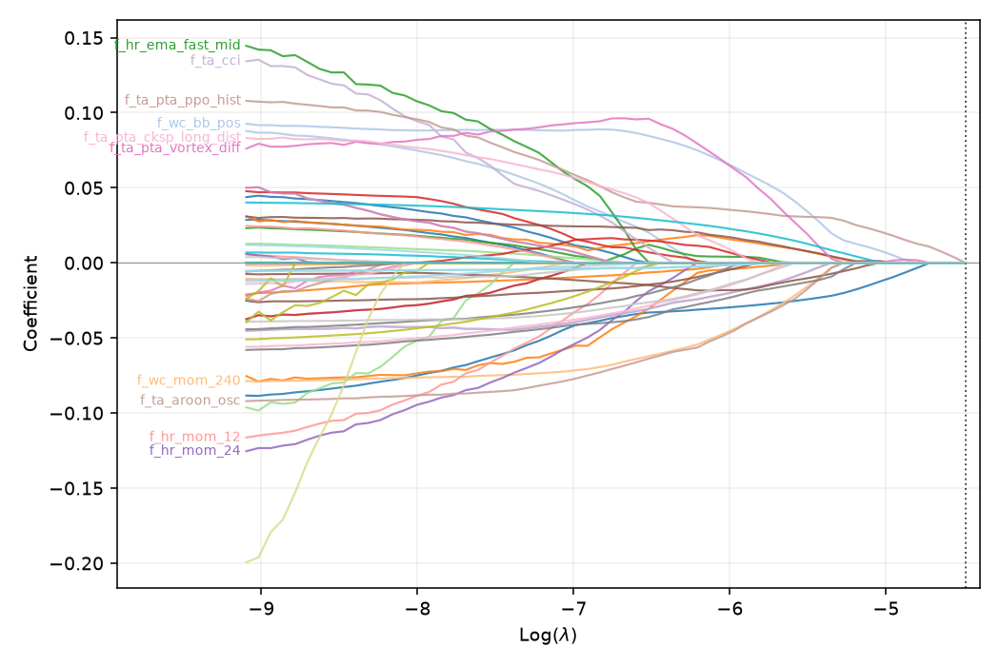

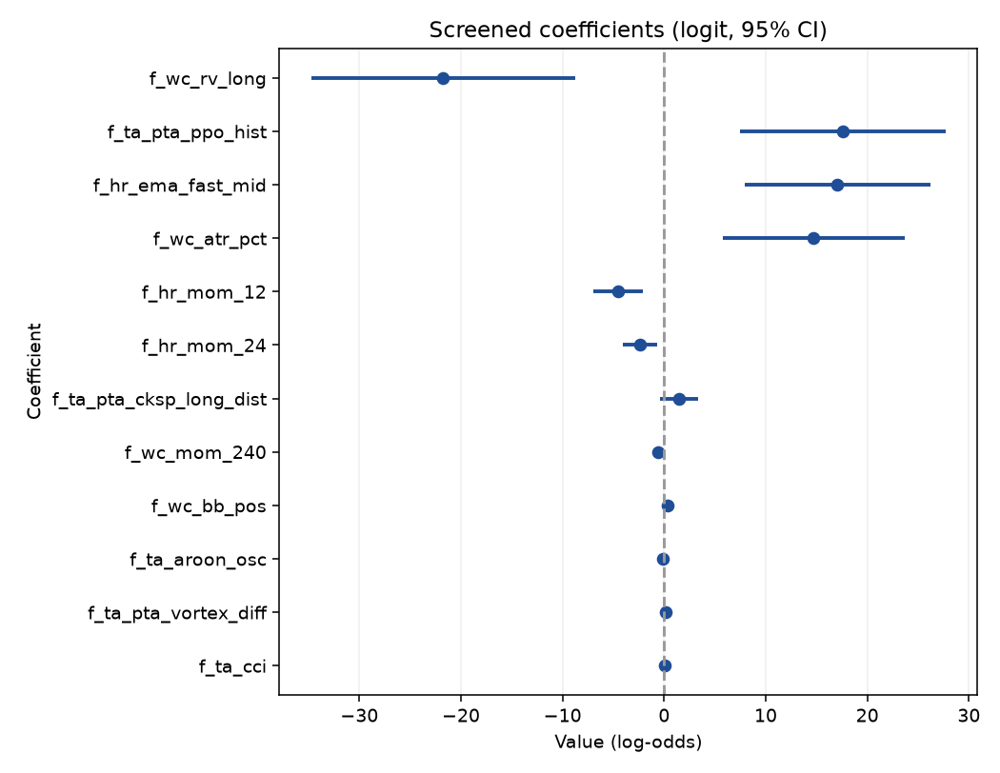


elastic-net kept 45 of 61 features at lambda.1se.
top kept: f_hr_ema_fast_mid(+0.094), f_wc_bb_pos(+0.088), f_ta_aroon_osc(-0.086), f_ta_pta_vortex_diff(+0.085), f_ta_pta_ppo_hist(+0.084), f_hr_mom_24(-0.083), f_wc_mom_240(-0.075), f_hr_mom_12(-0.071), f_ta_pta_cksp_long_dist(+0.070), f_ta_cci(+0.070), f_wc_rv_long(-0.068), f_wc_atr_pct(+0.066), f_wc_ema_fast_mid(-0.066), f_tl_sar_dist(-0.049), f_ta_pta_fisher(-0.046)
interactive coefficient path (open in browser): /Volumes/PortableSSD/Github/day-trader/04-outputs/AA-evals/varselect/coefpath.html

To train the head-to-head on this subset: set  feat = SELECTED_FEATURES  then re-run training.


In [42]:
# Stage ii: elastic-net (glmnet-analogue) variable selection on the TRAINING split ONLY, via
# inputs/variable_selection.py end-to-end: build_matrix -> enet_cv -> CV curve + coef paths ->
# screen at lambda.1se -> refit survivors for 95% CIs. The blind final year is never touched.
import importlib, variable_selection as vs
importlib.reload(vs)
from IPython.display import Image, display

VARSEL_DIR = OUTPUTS / "AA-evals" / "varselect"
VARSEL_DIR.mkdir(parents=True, exist_ok=True)

if df is not None and feat:
    tr_vs, _te_vs, _cut = t1.split(df)                          # select on TRAIN; OOS stays blind
    samp = tr_vs.dropna(subset=[*feat, "label"])
    if len(samp) > 25000:                                       # saga path is slow; 25k screens fine
        samp = samp.sample(25000, random_state=0)
    X, y, _ = vs.build_matrix(samp, y_col="label", x_cols=feat, standardize=True)
    res = vs.enet_cv(X, y, family="binomial", l1_ratio=1.0, n_folds=10, verbose=False)
    print(f"lasso path on {len(samp):,} TRAIN rows x {len(feat)} features.")
    print(f"lambda.min={res['lambda_min']:.4g} (nonzero {int(res['nonzero'][res['i_min']])}), "
          f"lambda.1se={res['lambda_1se']:.4g} (nonzero {int(res['nonzero'][res['i_1se']])})")

    p_cv  = vs.plot_cv_curve(res, str(VARSEL_DIR / "cv_curve.png"))
    p_cp  = vs.plot_coefpath(res, str(VARSEL_DIR / "coefpath.png"))
    p_cph = vs.plot_coefpath_interactive(res, str(VARSEL_DIR / "coefpath.html"))
    display(Image(filename=p_cv)); display(Image(filename=p_cp))

    kept = vs.screen(res, "1se") or vs.screen(res, "min")        # survivors, largest |coef| first
    SELECTED_FEATURES = [n for n, _ in kept]
    ci_cols = (SELECTED_FEATURES or [n for n, _ in vs.screen(res, "min")])[:12]
    p_ci = vs.plot_coef_ci(samp, "binomial", str(VARSEL_DIR / "coef_ci.png"),
                           y_col="label", x_cols=ci_cols,
                           title="Screened coefficients (logit, 95% CI)")
    display(Image(filename=p_ci))

    print(f"\nelastic-net kept {len(SELECTED_FEATURES)} of {len(feat)} features at lambda.1se.")
    print("top kept:", ", ".join(f"{n}({v:+.3f})" for n, v in kept[:15]))
    print("interactive coefficient path (open in browser):", p_cph)
    print("\nTo train the head-to-head on this subset: set  feat = SELECTED_FEATURES  then re-run training.")
else:
    SELECTED_FEATURES = []
    print("build the 1h dataset first (see Import Data).")

### 3.7 Training Regime

The model trains on all history before the final-year cut and is scored once on the blind year. A capped sample keeps the in-notebook fit quick; the full fit runs from the `.venv`. The section reports the held-out margin of the model's confident picks over the base rate, the feature importances, and a look at one tree, so the training is legible rather than a black box. The label and horizon are the 0.4 geometry.

In [43]:
# Split and scoring come from the scripts: t1.split for the 1h final-year hold-out; tm.evaluate,
# tm.build_models, tm.confidence_filtered shared with inputs/train_model.py. Nothing reimplemented.
train, test, cut = t1.split(df)
Xtr, ytr, Xte, yte = train[feat], train["label"], test[feat], test["label"]
base_te = yte.mean()
span = lambda d: f"{d['datetime'].min().date()} to {d['datetime'].max().date()}"
print(f"train {len(train):,} ({span(train)})  .  test {len(test):,} ({span(test)})  .  "
      f"cut {pd.Timestamp(cut).date()}  embargo +/-{t1.EMBARGO_DAYS}d  .  base rate {base_te:.3f}")

train 381,207 (2017-12-15 to 2025-06-16)  .  test 76,789 (2025-06-19 to 2026-06-18)  .  cut 2025-06-18  embargo +/-2d  .  base rate 0.303


In [44]:
# Fast interactive pass. The full-fidelity 3-model run on ALL history is inputs/train_model_1h.py
# (script / auto-eval). The heavy part here is evaluate()'s 5-fold TimeSeriesSplit CV on each model
# (3 models x (5 CV fits + 1 final fit) on ~381k rows = minutes). For the notebook we fit a bounded
# sample taken across the whole period and re-sorted by time, so the time-series CV stays
# chronological. Raise TRAIN_CAP or set it to None for the full run (slow).
TRAIN_CAP = 80_000
if TRAIN_CAP is None or len(train) <= TRAIN_CAP:
    tr_fit = train
else:
    tr_fit = train.sample(TRAIN_CAP, random_state=0).sort_values("datetime")
Xtr_f, ytr_f = tr_fit[feat], tr_fit["label"]
print(f"fitting on {len(tr_fit):,} of {len(train):,} train rows "
      f"({tr_fit['datetime'].min().date()} to {tr_fit['datetime'].max().date()})"
      + ("  [sampled for the notebook; full run is inputs/train_model_1h.py]"
         if (TRAIN_CAP and len(train) > TRAIN_CAP) else ""))

lines, scored = [], []
for name, mdl in tm.build_models(HAVE_LGBM):
    prec, m = tm.evaluate(name, mdl, Xtr_f, ytr_f, Xte, yte, base_te, lines)
    scored.append((prec, name, mdl, m))
print("\n".join(lines))
_, best_name, best_model, best = max(scored, key=lambda t: t[0])
print(f"\nchosen: {best_name}  (precision {best['prec']:.3f} vs base {base_te:.3f}, AUC {best['auc']:.3f})")

fitting on 80,000 of 381,207 train rows (2017-12-16 to 2025-06-16)  [sampled for the notebook; full run is inputs/train_model_1h.py]



--- LogisticRegression ---
  train CV ROC-AUC (5-fold TimeSeriesSplit): 0.528
  test accuracy : 0.484
  test precision(buy): 0.307   (base rate 0.303)
  test recall(buy)   : 0.560
  test ROC-AUC       : 0.504
  confusion matrix [rows=true 0/1, cols=pred 0/1]:
   [[24164, 29352], [10241, 13032]]
  precision lift over base rate: +0.004
  confidence filter (act if p>=0.60 or p<=0.40): keeps 2.7% of test rows (n=2075)
    precision(buy) 0.285  recall 0.663  F1 0.398  (base rate 0.303)

--- RandomForest ---
  train CV ROC-AUC (5-fold TimeSeriesSplit): 0.526
  test accuracy : 0.489
  test precision(buy): 0.310   (base rate 0.303)
  test recall(buy)   : 0.557
  test ROC-AUC       : 0.509
  confusion matrix [rows=true 0/1, cols=pred 0/1]:
   [[24627, 28889], [10319, 12954]]
  precision lift over base rate: +0.007
  confidence filter (act if p>=0.60 or p<=0.40): keeps 1.2% of test rows (n=931)
    precision(buy) 0.000  recall 0.000  F1 0.000  (base rate 0.303)

--- LightGBM ---
  train CV ROC-

In [45]:
# Honesty gate: precision must clearly beat the base rate and AUC clear 0.55. It does not
# trade; Metric 2 (next cell) is the money test.
margin = best["prec"] - base_te
go = (best["prec"] > base_te + 0.05) and (best["auc"] > 0.55)
verdict = "GO" if go else "NO-GO"
print("HONESTY GATE:", "GO (edge survives out-of-sample)" if go
      else "NO-GO (no demonstrable edge - do not trade)")
MODEL_DIR.mkdir(parents=True, exist_ok=True)   # self-sufficient: works even if the setup cell was not re-run
joblib.dump({"model": best_model, "features": feat, "name": best_name,
             "trained_through": str(pd.Timestamp(cut).date()),
             "test_base_rate": float(base_te), "go": bool(go)}, MODEL_DIR / "model_1h.joblib")
summary = (f"{best_name}: test precision(buy)={best['prec']:.3f} base_rate={base_te:.3f} "
           f"lift={margin:+.3f} AUC={best['auc']:.3f} recall={best['rec']:.3f} acc={best['acc']:.3f} -> {verdict}")
(MODEL_DIR / "model_metrics_1h.txt").write_text(summary + "\n\n" + "\n".join(lines) + "\n")
print("saved", MODEL_DIR / "model_1h.joblib", "and model_metrics_1h.txt")

HONESTY GATE: NO-GO (no demonstrable edge - do not trade)
saved /Volumes/PortableSSD/Github/day-trader/04-outputs/3B-model-training/model_1h.joblib and model_metrics_1h.txt


In [46]:
# Metrics 2 (P&L after costs) and 3 (regime-stratified AUC) plus AA-evals bookkeeping, from
# inputs/eval_report.py - the same record the script writes. Appends one row to
# outputs/AA-evals/evaluation-scores.md (+ .pdf, .docx), tagged "head-to-head (1h)".
imp = getattr(best_model, "feature_importances_", None)
regime = "f_wc_rv_long" if "f_wc_rv_long" in test.columns else next((c for c in feat if "rv_long" in c), None)
meta = dict(dataset_rows=len(df), n_features=len(feat),
            train_rows=len(train), test_rows=len(test), base_rate=float(base_te),
            cut=str(pd.Timestamp(cut).date()), embargo=t1.EMBARGO_DAYS,
            conf_hi=tm.CONF_HI, conf_lo=tm.CONF_LO, chosen=best_name, verdict=verdict,
            eval_type="head-to-head (1h)",
            dataset_label=f"{len(df):,}r / {len(feat)}f (1h all-market)",
            fi_names=list(feat) if imp is not None else None,
            fi_values=[float(v) for v in imp] if imp is not None else None,
            regime_vol=test[regime].tolist() if regime else None,
            trade_ret=test["trade_ret"].tolist() if "trade_ret" in test.columns else None,
            cost_pct=tm.COST_PCT)
results = [m for (_, _, _, m) in scored]
rec = eval_report.write_comparison(str(OUTPUTS / "AA-evals"), results, yte, meta)
print("evaluation record:", rec["md"])

evaluation record: /Volumes/PortableSSD/Github/day-trader/04-outputs/AA-evals/2026-09-07/eval-head-to-head-20260907.md


In [47]:
# Teaching display: the strongest tree model's top features. The AA-evals record above
# already saves this chart; this is just an inline look.
tree = next((mdl for (_, name, mdl, _) in scored
             if name in ("LightGBM", "RandomForest")), None)
imp = getattr(tree, "feature_importances_", None) if tree is not None else None
if imp is not None:
    order = np.argsort(imp)[::-1][:15]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([feat[i] for i in order][::-1], imp[order][::-1], color="#0B3D66")
    ax.set_title(f"{tree.__class__.__name__}: top 15 feature importances")
    fig.tight_layout()
    (OUTPUTS / "PNG").mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUTS / "PNG" / "3B-feature-importance.png", dpi=160)
    plt.show()

### 3.8 Model Tuning

Two sweeps, both scored on the after-fee out-of-sample scoreboard and logged to the consolidated scoreboard: the label-geometry sweep over the ATR barrier and horizon, and the model hyperparameter sweep over expanding time-series folds. These run full-market as scripts from the `.venv`; the cell shows the commands and renders the persisted result.

In [48]:
# The sweeps are full-market and run as scripts from the project .venv:
#   .venv/bin/python inputs/sweep_label_1h.py    # Priority 1b: label geometry (target, stop, horizon)
#   .venv/bin/python inputs/walkforward.py       # Priority 1a: exit geometry (stop, take-profit, trail)
# Both append to the consolidated scoreboard; here we render that one table so tuning reads off it.
#from IPython.display import Markdown, display
#scoreboard = OUTPUTS / "AA-evals" / "evaluation-scores.md"
#if scoreboard.exists():
#    display(Markdown(scoreboard.read_text()))
#else:
#    print("no evaluation-scores.md yet - run a model (cells above) or a sweep script first.")
# Quick inline 1b probe (small grid; the full grid is the script above):
#   import sweep_label_1h as sw
#   coins, scols = sw.precompute(bd.DEFAULT_KLINES_ROOT, bd.DEFAULT_FLOW_CSV, None)
#   sw.score_cell(coins, scols, 3.0, 1.0, 48, tm.COST_PCT/100.0, tm.CONF_HI)

### 3.9 Model Assessment

The caret-style scorecard, across every built frame. For each of 1h, 4h, and 5m it fits a bounded zoo on a sampled slice and scores a blind final year, reporting Full and cross-validated RMSE on predicted probabilities, the RMSEratio overfit flag, and the after-fee blind read, one block per frame. Frames are scored independently and stacked, never pooled.

In [49]:
# Model Assessment (stage iv): caret-style scorecard across EVERY built frame (1h, 4h, 5m), one row
# block per frame, so the resolutions sit in a single table on the same metric scale. Each frame is a
# SEPARATE model -- its own label geometry, feature set and blind out-of-sample -- so they are scored
# independently and stacked, NOT pooled into one training set (which would blend incompatible labels).
# RECOMPUTE=True fits a bounded zoo (logreg/rf/histgbm/lightgbm) on an ASSESS_CAP-row slice of each frame
# plus that frame's blind final-year test; RECOMPUTE=False shows the latest persisted full-zoo record.
# RMSE/MAE are on predicted PROBABILITIES (RMSE = sqrt(Brier)); CV is expanding-window time-series
# out-of-fold; RMSEratio = Full/CV (~1 generalises, well below 1 overfits). Refresh full-history per frame:
#   .venv/bin/python inputs/model_assessment_1h.py --dataset inputs/binance-data/dataset_4h_allmarket.parquet
import glob
import model_assessment_1h as ma
from IPython.display import Markdown, display

RECOMPUTE     = False                      # True = bounded zoo in-notebook per frame; False = cached full-zoo record
ASSESS_CAP    = 60_000                    # rows sampled per frame for the in-notebook fit (None = full frame, heavy)
ASSESS_FRAMES = ["1h", "4h", "5m"]        # frames to score; any not built on disk are skipped with a note
ASSESS_ZOO    = ["logreg", "rf", "histgbm", "lightgbm"]

def _assess_block(rows, frame):
    """One frame's caret rows, ranked by CV RMSE (lower = better), with a Frame column prepended."""
    ranked = sorted(rows, key=lambda r: r["cv_rmse"])
    block = [{"Frame": frame, "Model": r["model"], "Hyperparameters": r["hp"],
              "Full MAE": round(r["full_mae"], 4), "Full RMSE": round(r["full_rmse"], 4),
              "CV MAE": round(r["cv_mae"], 4), "CV RMSE": round(r["cv_rmse"], 4),
              "RMSEratio": round(r["rmse_ratio"], 3)} for r in ranked]
    return block, ranked[0]

recs = sorted(glob.glob(str(OUTPUTS / "AA-evals" / "*" / "model-assessment-*.md")))
if RECOMPUTE:
    _active  = globals().get("LOAD_FRAME")                      # reuse the already-loaded frame if it is one of these
    _df_live = globals().get("df")
    _prev    = _active if _active is not None else bd.INTERVAL  # restore the notebook's active frame afterwards
    table, summary = [], []
    try:
        for _frame in ASSESS_FRAMES:
            bd.configure(_frame)                               # retune windows/label/screen + DATASET_PATH per frame
            path = bd.DATASET_PATH
            if not (os.path.exists(path) or os.path.exists(os.path.splitext(path)[0] + ".csv")):
                print(f"[{_frame}] dataset not built ({os.path.basename(path)}); skipping.")
                continue
            reused = (_frame == _active and _df_live is not None)
            dff = None
            try:
                dff = _df_live if reused else bd.read_frame(path)   # reuse active frame; load the others on demand
                featf = bd.feature_columns(dff)
                dfa = (dff if (ASSESS_CAP is None or len(dff) <= ASSESS_CAP)
                       else dff.sample(ASSESS_CAP, random_state=0).sort_values("datetime"))
                print(f"[{_frame}] assessing {len(dfa):,} of {len(dff):,} in-sample rows, {len(featf)} features "
                      f"({'reusing loaded frame' if reused else 'loaded from disk'})...")
                rows, tr_a, te_a, _ = ma.assess(dfa, featf, only=ASSESS_ZOO)
                block, best = _assess_block(rows, _frame)
                table += block
                blind = ma.blind_metrics(best["est"], tr_a, te_a, featf, tm.COST_PCT / 100.0, tm.CONF_HI)
                verdict = "GO" if (np.isfinite(blind["net"]) and blind["net"] > 0
                                   and blind["prec"] > blind["base"] and blind["auc"] > 0.55) else "NO-GO"
                summary.append(dict(frame=_frame, best=best, blind=blind, verdict=verdict))
            except Exception as _e:
                print(f"[{_frame}] skipped: {type(_e).__name__}: {_e}")
            finally:
                if dff is not None and not reused:
                    del dff                                    # free the on-demand frame before the next one
    finally:
        bd.configure(_prev)                                    # leave bd as the rest of the notebook expects

    if table:
        show_table(pd.DataFrame(table))                        # one combined scorecard, a block per frame
        print("\nbest model per frame (by CV RMSE), with its blind final-year after-fee read:")
        for s in summary:
            b, bl = s["best"], s["blind"]
            pct = (bl["prec"] / bl["base"] - 1) * 100 if bl["base"] else float("nan")
            print(f"  [{s['frame']:>2s}] {b['model']:<10s} CV RMSE {b['cv_rmse']:.4f} (Full/CV {b['rmse_ratio']:.3f})"
                  f"  .  blind AUC {bl['auc']:.3f}, precision {bl['prec']:.3f} vs base {bl['base']:.3f} "
                  f"({pct:+.1f}%), net {bl['net']*100:+.3f}%/trade on {bl['trades']:,}  ->  {s['verdict']}")
        print(f"\ncross-validation: {ma.CV_SPLITS}-fold expanding-window TimeSeriesSplit per frame (time-ordered, "
              f"no future leak); each frame's final year is its own blind test. Frames are scored "
              f"independently and stacked, never pooled: the label geometry and features differ per resolution.")
    else:
        print("no built frames to assess; build at least one dataset (see Import Data), then re-run.")
elif recs:
    print(f"RECOMPUTE off -- showing latest persisted full-zoo record: {os.path.basename(recs[-1])}")
    display(Markdown(open(recs[-1]).read()))
else:
    print("build a dataset first (see Import Data), then set RECOMPUTE=True.")


RECOMPUTE off -- showing latest persisted full-zoo record: model-assessment-20260906.md

# Model assessment (2026-09-06) -- caret-style, 1h frame

RMSE/MAE are on predicted probabilities (RMSE = sqrt(Brier), the caret-style classification RMSE). Full = in-sample on the training window; CV = time-series out-of-fold on the training window; RMSEratio = CV RMSE / Full RMSE (near 1 = stable, above 1.1 = rejected as overfit). The final year is held out as a single blind test (below). Ranked by CV RMSE, best first.

| model | hyperparameters | Full MAE | Full RMSE | CV MAE | CV RMSE | RMSEratio |
| --- | --- | --- | --- | --- | --- | --- |
| HistGBM | leaves=31 lr=0.05 iter=600 | 0.2181 | 0.2619 | 0.3861 | 0.4818 | 1.840 |
| LightGBM | leaves=31 lr=0.05 n=600 | 0.2387 | 0.2806 | 0.4036 | 0.4826 | 1.720 |
| RF | mtry=auto ntree=400 depth=8 | 0.4445 | 0.4526 | 0.4761 | 0.4840 | 1.069 |
| LogReg.glm | C=1.0 | 0.4718 | 0.4855 | 0.4463 | 0.4909 | 1.011 |

**Best by CV RMSE:** HistGBM (CV RMSE 0.4818, RMSEratio 1.840).

**Blind final-year test of the best model** (scored once): AUC 0.509, precision(buy|p>=0.60) 0.249 vs base rate 0.254, net P&L/trade -0.454% on 3,012 trades.

**Classification view** (blind test, 0.5 threshold) -- diagnostics for whether the minority (barrier-hit) class is learned; the after-fee Metric 2 above remains the GO/NO-GO. Cohen's Kappa 0.006; OOB nan (RandomForest only).

| class | precision | recall | F1 |
| --- | --- | --- | --- |
| 0 (no-hit) | 0.748 | 0.706 | 0.726 |
| 1 (barrier-hit) | 0.258 | 0.301 | 0.278 |

Confusion matrix [true x pred]: TN 9,942, FP 4,142, FN 3,348, TP 1,440.



### 3.10 Stability

The Monte Carlo robustness gate, per frame. It resamples the model's held-out confident trades ten thousand times to ask whether the result is robust or luck and what the realistic worst case is, reporting total return, drawdown, and Sharpe with their worst-case percentiles, the probability of a loss, and a sign-flip p-value. A frame is ROBUST only if the fifth-percentile total is positive, the loss probability is low, and the p-value small. On the current label every frame reads FRAGILE, the honest reading of a negative-mean series compounded.

In [50]:
# Monte Carlo robustness (the Stability gate) across EVERY built frame (1h, 4h, 5m). A single backtest is
# ONE path; this resamples the after-fee per-trade returns 10k times per frame to ask whether the result
# is robust or luck, and the realistic worst case. PRIMARY subject per frame = the trained model's
# held-out confident trades (ed.model_trade_returns: train before the final-year cut, predict the held-out
# year, keep P(up) >= CONF_HI, net each by the round-trip cost). If a frame yields < 20 such trades it
# falls back to that frame's triple-Supertrend baseline OOS trades (one-year window sized to the frame via
# bd.INTERVAL_HOURS). ROBUST requires bootstrap P5 total > 0, p(loss) < 5%, sign-flip p-value < 0.05. Each
# frame is a separate system, shown in sequence, never pooled. STAB_CAP bounds rows per frame for speed.
import importlib, monte_carlo_1h as mc, edge_diagnostics as ed, exit_geometry_1h as eg
importlib.reload(mc)

STAB_CAP    = 150_000               # rows per frame for the model subject (None = full frame, heavier)
STAB_FRAMES = ["1h", "4h", "5m"]    # frames to stress-test; any not built on disk are skipped with a note

def _mc_report(rets, subject, tag):
    s = mc.summary(np.array(rets), n_sims=10000)
    show_table(pd.DataFrame(
        {"actual": [f"{s['actual_total']:+.1%}", f"{s['actual_maxdd']:.1%}", f"{s['actual_sharpe']:.2f}"],
         "P5 (worst)": [f"{s['total_p5']:+.1%}", f"{s['maxdd_worst5']:.1%}", f"{s['sharpe_p5']:.2f}"],
         "median": [f"{s['total_p50']:+.1%}", f"{s['maxdd_p50']:.1%}", f"{s['sharpe_p50']:.2f}"],
         "P95": [f"{s['total_p95']:+.1%}", "-", "-"]},
        index=["total return", "max drawdown", "Sharpe"]))
    print(f"{subject}: trades {s['n_trades']}  prob(loss) {s['prob_loss']:.1%}  "
          f"sign-flip p-value {s['perm_pvalue']:.4f}  ->  {mc.verdict(s)}")
    print("monte carlo record:", mc.write_record(s, str(OUTPUTS / "AA-evals"), label=subject + ".", tag=tag))

def _baseline_rets(frame_df):
    """Frame-aware triple-Supertrend OOS trades over the liquid coins -- the fallback when the model has
    too few confident trades. The one-year window is sized to the current frame (bd.INTERVAL_HOURS)."""
    oos_n = int(round(365 * 24 / bd.INTERVAL_HOURS))          # one year of bars at this frame
    coins = sorted(sym.replace("/", "") for sym in frame_df["symbol"].unique())[:20]
    out = []
    for sym in coins:
        d = bd.load_coin(bd.DEFAULT_KLINES_ROOT, sym)
        if len(d) < oos_n + bd.ST_EMA:
            continue
        oos = d.iloc[-oos_n:].reset_index(drop=True)
        ent = eg.supertrend_entries(oos)
        out += [t["ret"] for t in eg.simulate(oos, ent, dict(stop_mult=2.0, tp_atr=3.0, trail=0.0, tp_decay=False))]
    return out

_active  = globals().get("LOAD_FRAME")                        # reuse the already-loaded frame if it is one of these
_df_live = globals().get("df")
_prev    = _active if _active is not None else bd.INTERVAL     # restore the notebook's active frame afterwards
try:
    for _frame in STAB_FRAMES:
        bd.configure(_frame)                                  # retune windows/label/screen + DATASET_PATH + klines root
        path = bd.DATASET_PATH
        if not (os.path.exists(path) or os.path.exists(os.path.splitext(path)[0] + ".csv")):
            print(f"\n[{_frame}] dataset not built ({os.path.basename(path)}); skipping.")
            continue
        reused = (_frame == _active and _df_live is not None)
        dff = None
        try:
            dff = _df_live if reused else bd.read_frame(path)  # reuse active frame; load the others on demand
            featf = bd.feature_columns(dff)
            dfa = (dff if (STAB_CAP is None or len(dff) <= STAB_CAP)
                   else dff.sample(STAB_CAP, random_state=0).sort_values("datetime").reset_index(drop=True))
            print(f"\n=== [{_frame}] Stability Monte Carlo "
                  f"({'reusing loaded frame' if reused else 'loaded from disk'}, {len(dfa):,} rows) ===")
            model_rets = ed.model_trade_returns(dfa, featf)
            if len(model_rets) >= 20:
                _mc_report(model_rets, f"{_frame} trained model (held-out OOS, confident picks)", _frame)
            else:
                print(f"[{_frame}] only {len(model_rets)} confident model trades on the held-out year; "
                      f"falling back to the triple-Supertrend baseline.")
                base = _baseline_rets(dff)
                if len(base) >= 20:
                    _mc_report(base, f"{_frame} triple-Supertrend baseline (OOS)", _frame)
                else:
                    print(f"[{_frame}] not enough trades for Monte Carlo (need >=20).")
        except Exception as _e:
            print(f"[{_frame}] skipped: {type(_e).__name__}: {_e}")
        finally:
            if dff is not None and not reused:
                del dff                                        # free the on-demand frame before the next one
finally:
    bd.configure(_prev)                                        # leave bd as the rest of the notebook expects



=== [1h] Stability Monte Carlo (reusing loaded frame, 150,000 rows) ===


,actual,P5 (worst),median,P95
total return,-99.8%,-99.9%,-99.8%,-99.2%
max drawdown,-99.8%,-99.9%,-99.8%,-
Sharpe,-7.71,-9.56,-7.72,-


1h trained model (held-out OOS, confident picks): trades 1476  prob(loss) 100.0%  sign-flip p-value 1.0000  ->  FRAGILE
monte carlo record: /Volumes/PortableSSD/Github/day-trader/04-outputs/AA-evals/2026-09-07/monte-carlo-20260907-1h.md



=== [4h] Stability Monte Carlo (loaded from disk, 150,000 rows) ===


,actual,P5 (worst),median,P95
total return,-90.3%,-99.2%,-90.3%,+32.9%
max drawdown,-99.6%,-99.6%,-95.8%,-
Sharpe,-0.65,-2.30,-0.65,-


4h trained model (held-out OOS, confident picks): trades 2010  prob(loss) 92.7%  sign-flip p-value 0.7403  ->  FRAGILE
monte carlo record: /Volumes/PortableSSD/Github/day-trader/04-outputs/AA-evals/2026-09-07/monte-carlo-20260907-4h.md



=== [5m] Stability Monte Carlo (loaded from disk, 150,000 rows) ===


,actual,P5 (worst),median,P95
total return,-41.8%,-51.2%,-41.8%,-30.3%
max drawdown,-43.4%,-51.8%,-42.7%,-
Sharpe,-4.84,-6.85,-4.86,-


5m trained model (held-out OOS, confident picks): trades 398  prob(loss) 100.0%  sign-flip p-value 1.0000  ->  FRAGILE
monte carlo record: /Volumes/PortableSSD/Github/day-trader/04-outputs/AA-evals/2026-09-07/monte-carlo-20260907-5m.md


### 3.11 Edge Diagnostics

Why the scoreboard says NO-GO, in three questions plus the honest selectivity test, run per frame. Q1 asks whether a pre-cost edge exists at all against a base-rate coin flip and a one-bar persistence rule. Q5 asks whether any edge is stable across eras or an artifact of one regime. Q6 sweeps the confidence threshold to see whether selectivity pays. The out-of-sample selectivity test then chooses the threshold on train and scores it once on the blind year, so a thin in-sample peak cannot pass. The verdict is a genuine floor, not a leakage artifact; the leakage audit is clean.

In [51]:
# Edge diagnostics (Q1 pre-cost, Q5 regimes, Q6 selectivity) across EVERY built frame (1h, 4h, 5m),
# computed IN THIS NOTEBOOK. For each built frame it retunes bd (windows/label/screen/klines root),
# loads that dataset, runs the out-of-fold sweep (ed.run), writes a frame-tagged dated record + a
# selectivity PNG, and renders both. Each frame is a separate model on its own out-of-sample, shown in
# sequence and never pooled. SAMPLE_CAP bounds rows per frame (None = full frame, heavier, esp. 5m).
import glob
import edge_diagnostics as ed
from IPython.display import Markdown, Image, display

RECOMPUTE   = False                  # True = recompute in-notebook per frame; False = show cached records
SAMPLE_CAP  = 60_000                # rows per frame for the in-notebook sweep (None = full frame)
N_SPLITS    = 5
DIAG_FRAMES = ["1h", "4h", "5m"]    # frames to diagnose; any not built on disk are skipped with a note

recs = sorted(glob.glob(str(OUTPUTS / "AA-evals" / "*" / "edge-diagnostics-*.md")))
if RECOMPUTE:
    _active  = globals().get("LOAD_FRAME")                     # reuse the already-loaded frame if it is one of these
    _df_live = globals().get("df")
    _prev    = _active if _active is not None else bd.INTERVAL  # restore the notebook's active frame afterwards
    written  = []
    try:
        for _frame in DIAG_FRAMES:
            bd.configure(_frame)                               # retune windows/label/screen + DATASET_PATH + klines root
            path = bd.DATASET_PATH
            if not (os.path.exists(path) or os.path.exists(os.path.splitext(path)[0] + ".csv")):
                print(f"[{_frame}] dataset not built ({os.path.basename(path)}); skipping.")
                continue
            reused = (_frame == _active and _df_live is not None)
            dff = None
            try:
                dff = _df_live if reused else bd.read_frame(path)   # reuse active frame; load the others on demand
                featf = bd.feature_columns(dff)
                dfa = (dff if (SAMPLE_CAP is None or len(dff) <= SAMPLE_CAP)
                       else dff.sample(SAMPLE_CAP, random_state=0).sort_values("datetime").reset_index(drop=True))
                print(f"[{_frame}] edge diagnostics on {len(dfa):,} of {len(dff):,} rows "
                      f"({'reusing loaded frame' if reused else 'loaded from disk'}); trains the out-of-fold sweep...")
                rec = ed.run(dfa, featf, bd.DEFAULT_KLINES_ROOT,
                             label=f"{bd.INTERVAL} ({'full frame' if SAMPLE_CAP is None else f'{len(dfa):,}-row sample'})",
                             out_dir=str(OUTPUTS / "AA-evals"), n_splits=N_SPLITS)
                written.append(rec["md"])
                display(Markdown(f"---\n### {bd.INTERVAL} frame\n\n" + open(rec["md"]).read()))
                display(Image(filename=rec["png"]))
            except Exception as _e:
                print(f"[{_frame}] skipped: {type(_e).__name__}: {_e}")
            finally:
                if dff is not None and not reused:
                    del dff                                    # free the on-demand frame before the next one
    finally:
        bd.configure(_prev)                                    # leave bd as the rest of the notebook expects
    if written:
        print("records written:")
        for _m in written:
            print("  ", _m)
    else:
        print("no built frames to diagnose; build at least one dataset (see Import Data), then re-run.")
elif recs:
    print(f"RECOMPUTE off -- showing the latest persisted records ({min(3, len(recs))} of {len(recs)}):")
    for _m in recs[-3:]:
        display(Markdown(open(_m).read()))
else:
    print("load the dataset first (see Import Data), then set RECOMPUTE=True.")


RECOMPUTE off -- showing the latest persisted records (3 of 9):


# Edge diagnostics (2026-07-03) -- 5m (60,000-row sample)

## Q1. Pre-cost edge (held-out, fees stripped)
- base rate 0.393 (majority-class accuracy 0.607, informational only)
- model: AUC 0.519 (vs 0.50), accuracy 0.515
- model picks: precision 0.448 vs base 0.393  ->  beats the real balance: True
- 1-bar persistence baseline: precision 0.390, pre-cost -0.006%/trade
- model pre-cost mean return per acted trade +0.024% on 473 trades; after-cost -0.176% (cost 0.20% round trip)
- **gate: PASS - a pre-cost edge exists to chase** (beats base True, beats persistence True)

## Q5. Edge stability across eras (after-cost, time-series out-of-fold)
| era | trades | after-cost / trade | win rate |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 31 | -0.185% | 0.39 |
| 2020-21 bull | 440 | -0.198% | 0.36 |
| 2021 top + chop | 572 | -0.121% | 0.45 |
| 2022 collapse | 961 | -0.186% | 0.37 |
| 2023-24 recovery | 1,065 | -0.200% | 0.26 |
| 2025-26 recent | 1,106 | -0.209% | 0.34 |

## Q6. Selectivity (after-cost return per trade vs confidence threshold)
![selectivity](edge-diagnostics-selectivity-5m-20260703.png)

| threshold | trades | after-cost / trade | total after-cost | win rate |
| --- | --- | --- | --- | --- |
| 0.450 | 33,449 | -0.198% | -6621.6% | 0.35 |
| 0.491 | 24,131 | -0.195% | -4717.5% | 0.35 |
| 0.532 | 14,232 | -0.191% | -2715.3% | 0.35 |
| 0.573 | 6,978 | -0.189% | -1315.4% | 0.35 |
| 0.614 | 3,189 | -0.187% | -594.9% | 0.34 |
| 0.655 | 1,293 | -0.176% | -228.2% | 0.34 |
| 0.695 | 487 | -0.159% | -77.2% | 0.36 |
| 0.736 | 173 | -0.187% | -32.4% | 0.35 |
| 0.777 | 53 | -0.072% | -3.8% | 0.38 |
| 0.818 | 6 | +0.977% | +5.9% | 0.67 |
| 0.859 | 1 | +4.012% | +4.0% | 1.00 |
| 0.900 | 0 | - | - | - |

**Selectivity reading:** after-cost return per trade rises but stays NEGATIVE at every threshold (-0.198% -> best -0.072% on 53 trades), and the trade count collapses toward the top. The model RANKS well but the frame still loses to fees at every operating point -- selectivity does not rescue it. The lever is a coarser decision frame, new information, or cross-sectional framing, NOT a higher threshold and NOT a model retrain on selectivity.



# Edge diagnostics (2026-09-07) -- 1d all-market

## Q1. Pre-cost edge (held-out, fees stripped)
- base rate 0.147 (majority-class accuracy 0.853, informational only)
- model: AUC 0.530 (vs 0.50), accuracy 0.657
- model picks: precision 0.167 vs base 0.147  ->  beats the real balance: True
- 1-bar persistence baseline: precision 0.159, pre-cost -2.299%/trade
- model pre-cost mean return per acted trade -1.150% on 418 trades; after-cost -1.350% (cost 0.20% round trip)
- **gate: FAIL - no pre-cost edge; the problem is features/architecture, not costs** (beats base False, beats persistence True)

## Q5. Edge stability across eras (after-cost, time-series out-of-fold)
| era | trades | after-cost / trade | win rate |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 0 | - | - |
| 2020-21 bull | 0 | - | - |
| 2021 top + chop | 0 | - | - |
| 2022 collapse | 1,142 | -1.849% | 0.22 |
| 2023-24 recovery | 306 | -0.043% | 0.34 |
| 2025-26 recent | 606 | -0.473% | 0.27 |

## Q6. Selectivity (after-cost return per trade vs confidence threshold)
![selectivity](edge-diagnostics-selectivity-1d-20260907.png)

| threshold | trades | after-cost / trade | total after-cost | win rate |
| --- | --- | --- | --- | --- |
| 0.450 | 4,204 | -1.151% | -4838.3% | 0.26 |
| 0.491 | 3,513 | -1.005% | -3528.9% | 0.27 |
| 0.532 | 2,879 | -1.021% | -2939.6% | 0.26 |
| 0.573 | 2,360 | -1.060% | -2502.0% | 0.26 |
| 0.614 | 1,926 | -1.132% | -2180.1% | 0.26 |
| 0.655 | 1,568 | -1.291% | -2023.6% | 0.25 |
| 0.695 | 1,232 | -1.241% | -1528.6% | 0.25 |
| 0.736 | 931 | -1.293% | -1203.6% | 0.25 |
| 0.777 | 691 | -1.650% | -1139.9% | 0.24 |
| 0.818 | 500 | -1.687% | -843.3% | 0.24 |
| 0.859 | 327 | -2.559% | -836.8% | 0.20 |
| 0.900 | 179 | -4.240% | -759.0% | 0.14 |

**Selectivity reading:** after-cost return per trade is flat or falls with the threshold -- the confidence ranking carries no usable selectivity; neither a higher threshold nor a retrain on it helps.



# Edge diagnostics (2026-09-07) -- 4h all-market

## Q1. Pre-cost edge (held-out, fees stripped)
- base rate 0.254 (majority-class accuracy 0.746, informational only)
- model: AUC 0.549 (vs 0.50), accuracy 0.598
- model picks: precision 0.273 vs base 0.254  ->  beats the real balance: True
- 1-bar persistence baseline: precision 0.265, pre-cost -0.118%/trade
- model pre-cost mean return per acted trade -0.182% on 1,748 trades; after-cost -0.382% (cost 0.20% round trip)
- **gate: FAIL - no pre-cost edge; the problem is features/architecture, not costs** (beats base False, beats persistence False)

## Q5. Edge stability across eras (after-cost, time-series out-of-fold)
| era | trades | after-cost / trade | win rate |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 0 | - | - |
| 2020-21 bull | 0 | - | - |
| 2021 top + chop | 0 | - | - |
| 2022 collapse | 1,722 | -0.262% | 0.35 |
| 2023-24 recovery | 3,493 | -0.028% | 0.38 |
| 2025-26 recent | 3,650 | -0.316% | 0.34 |

## Q6. Selectivity (after-cost return per trade vs confidence threshold)
![selectivity](edge-diagnostics-selectivity-4h-20260907.png)

| threshold | trades | after-cost / trade | total after-cost | win rate |
| --- | --- | --- | --- | --- |
| 0.450 | 41,690 | -0.242% | -10096.9% | 0.35 |
| 0.491 | 30,545 | -0.207% | -6316.9% | 0.35 |
| 0.532 | 20,702 | -0.203% | -4207.5% | 0.35 |
| 0.573 | 12,932 | -0.219% | -2832.8% | 0.35 |
| 0.614 | 7,217 | -0.235% | -1695.0% | 0.35 |
| 0.655 | 3,665 | -0.278% | -1020.7% | 0.35 |
| 0.695 | 1,651 | -0.152% | -250.6% | 0.36 |
| 0.736 | 640 | +0.074% | +47.2% | 0.38 |
| 0.777 | 194 | +0.360% | +69.9% | 0.41 |
| 0.818 | 46 | +0.572% | +26.3% | 0.41 |
| 0.859 | 4 | +1.443% | +5.8% | 0.50 |
| 0.900 | 1 | +4.825% | +4.8% | 1.00 |

**Selectivity reading:** after-cost return per trade rises AND crosses zero -- at p>=0.777 it is +0.360% on 194 trades. A selective operating point clears fees: tune that confidence threshold OUT-OF-SAMPLE (walk-forward) with a minimum-trade floor, judged on TOTAL after-cost P&L (best so far at p>=0.777), not per-trade alone. This is operating-point tuning, not a model retrain.



In [52]:
# Out-of-sample selectivity across EVERY built frame (1h, 4h, 5m): the confidence threshold is fit on
# TRAIN (the cutoff with the best total after-cost P&L above a trade floor), then scored ONCE on the
# blind final year across the universe (ed.oos_selectivity) -- per frame, one row each. This is the
# honest answer to "does a selective operating point clear fees", versus the in-sample Q6 curve. Reuses
# the loaded frame, loads the others on demand and frees them, and restores bd afterward. SEL_CAP bounds rows.
import edge_diagnostics as ed

SEL_CAP    = 80_000                 # rows per frame (None = full frame, heavier)
SEL_FRAMES = ["1h", "4h", "5m"]     # frames to test; any not built on disk are skipped with a note

_active  = globals().get("LOAD_FRAME")
_df_live = globals().get("df")
_prev    = _active if _active is not None else bd.INTERVAL
rows = []
try:
    for _frame in SEL_FRAMES:
        bd.configure(_frame)
        path = bd.DATASET_PATH
        if not (os.path.exists(path) or os.path.exists(os.path.splitext(path)[0] + ".csv")):
            print(f"[{_frame}] dataset not built ({os.path.basename(path)}); skipping.")
            continue
        reused = (_frame == _active and _df_live is not None)
        dff = None
        try:
            dff = _df_live if reused else bd.read_frame(path)
            featf = bd.feature_columns(dff)
            dfa = (dff if (SEL_CAP is None or len(dff) <= SEL_CAP)
                   else dff.sample(SEL_CAP, random_state=0).sort_values("datetime").reset_index(drop=True))
            print(f"[{_frame}] OOS selectivity on {len(dfa):,} of {len(dff):,} rows "
                  f"({'reusing loaded frame' if reused else 'loaded from disk'}); threshold on train, scored once...")
            s = ed.oos_selectivity(dfa, featf)
            rows.append({"Frame": bd.INTERVAL, "threshold (train)": s["threshold"],
                         "OOS trades": f"{s['oos_trades']:,}",
                         "OOS after-cost/trade": f"{s['oos_after_per_trade']*100:+.3f}%",
                         "OOS total after-cost": f"{s['oos_total_after']*100:+.1f}%",
                         "OOS win": (f"{s['oos_win']:.2f}" if s['oos_trades'] else "-"),
                         "OOS prec/base": (f"{s['oos_prec']:.3f}/{s['oos_base']:.3f}" if s['oos_trades'] else "-"),
                         "blind ends": s["cut"], "verdict": s["verdict"]})
        except Exception as _e:
            print(f"[{_frame}] skipped: {type(_e).__name__}: {_e}")
        finally:
            if dff is not None and not reused:
                del dff
finally:
    bd.configure(_prev)
if rows:
    show_table(pd.DataFrame(rows))
else:
    print("load the dataset first (see Import Data).")


[1h] OOS selectivity on 80,000 of 458,539 rows (reusing loaded frame); threshold on train, scored once...


[4h] OOS selectivity on 80,000 of 3,939,629 rows (loaded from disk); threshold on train, scored once...


[5m] OOS selectivity on 80,000 of 5,529,861 rows (loaded from disk); threshold on train, scored once...


,Frame,threshold (train),OOS trades,OOS after-cost/trade,OOS total after-cost,OOS win,OOS prec/base,blind ends,verdict
0,1h,0.525,"4,198",-0.360%,-1511.3%,0.30,0.298/0.298,2025-06-18,NO-GO (loses to fees out of sample)
1,4h,0.500,"6,509",-0.310%,-2016.1%,0.35,0.282/0.254,2025-06-21,NO-GO (loses to fees out of sample)
2,5m,0.550,"2,551",-0.198%,-505.4%,0.33,0.414/0.393,2025-06-24,NO-GO (loses to fees out of sample)


### 3.12 Regime Conditioning

The handoff's Part 2 fix: condition one model on observable regime state rather than switch between per-regime models. The `f_rg_` block gives the model trailing volatility and its own-history percentile, trend drift, a Kaufman efficiency, up-down breadth, and the BTC market regime, and the ablation trains the same model with and without it, per frame, comparing cross-era stability and after-fee edge. It carries the same model-performance scoreboard and the Monte Carlo robustness gate. Conditioning is a generalization fix, more eras profitable and a less bad worst era, not by itself a free edge across the fee line.

In [53]:
# Regime-conditioning ablation (handoff Part 2) across EVERY built frame (1h, 4h, 5m), computed IN THIS
# NOTEBOOK so re-running reflects the latest regime_conditioning.py (incl. the model-performance + Monte
# Carlo metrics). For each built frame it retunes bd, loads that dataset, and trains the model WITH vs
# WITHOUT the f_rg_ regime block (recomputing f_rg_ from that frame's klines if the dataset predates the
# block), writes a frame-tagged dated record, and renders it. Each frame is a separate model scored on
# its own out-of-sample; the frames are shown in sequence, never pooled. SAMPLE_CAP bounds rows per frame.
import glob, importlib
import regime_conditioning as rc
importlib.reload(rc)  # pick up the latest regime_conditioning.py (model-performance + Monte Carlo metrics)
from IPython.display import Markdown, display

RECOMPUTE     = False                  # True = recompute in-notebook per frame; False = show cached records
SAMPLE_CAP    = 30_000                # rows per frame for the in-notebook ablation (None = full frame, heavy)
N_SPLITS      = 4
ABLATE_FRAMES = ["1h", "4h", "5m"]    # frames to ablate; any not built on disk are skipped with a note

recs = sorted(glob.glob(str(OUTPUTS / "AA-evals" / "*" / "regime-conditioning-*.md")))
if RECOMPUTE:
    _active  = globals().get("LOAD_FRAME")                      # reuse the already-loaded frame if it is one of these
    _df_live = globals().get("df")
    _prev    = _active if _active is not None else bd.INTERVAL  # restore the notebook's active frame afterwards
    written  = []
    try:
        for _frame in ABLATE_FRAMES:
            bd.configure(_frame)                               # retune windows/label/screen + DATASET_PATH + klines root
            path = bd.DATASET_PATH
            if not (os.path.exists(path) or os.path.exists(os.path.splitext(path)[0] + ".csv")):
                print(f"[{_frame}] dataset not built ({os.path.basename(path)}); skipping.")
                continue
            reused = (_frame == _active and _df_live is not None)
            dff = None
            try:
                dff = _df_live if reused else bd.read_frame(path)   # reuse active frame; load the others on demand
                featf = bd.feature_columns(dff)
                dfa = (dff if (SAMPLE_CAP is None or len(dff) <= SAMPLE_CAP)
                       else dff.sample(SAMPLE_CAP, random_state=0).sort_values("datetime").reset_index(drop=True))
                print(f"[{_frame}] regime ablation on {len(dfa):,} of {len(dff):,} rows "
                      f"({'reusing loaded frame' if reused else 'loaded from disk'}); trains two models and "
                      f"recomputes f_rg_ from klines if the dataset predates the block, so give it a moment...")
                rec = rc.run(dfa, featf, bd.DEFAULT_KLINES_ROOT,
                             label=f"{bd.INTERVAL} ({'full frame' if SAMPLE_CAP is None else f'{len(dfa):,}-row sample'})",
                             out_dir=str(OUTPUTS / "AA-evals"), n_splits=N_SPLITS)
                written.append(rec["md"])
                display(Markdown(f"---\n### {bd.INTERVAL} frame\n\n" + open(rec["md"]).read()))
            except Exception as _e:
                print(f"[{_frame}] skipped: {type(_e).__name__}: {_e}")
            finally:
                if dff is not None and not reused:
                    del dff                                    # free the on-demand frame before the next one
    finally:
        bd.configure(_prev)                                    # leave bd as the rest of the notebook expects
    if written:
        print("records written:")
        for _m in written:
            print("  ", _m)
    else:
        print("no built frames to ablate; build at least one dataset (see Import Data), then re-run.")
elif recs:
    print(f"RECOMPUTE off -- showing the latest persisted records ({min(3, len(recs))} of {len(recs)}):")
    for _m in recs[-3:]:
        display(Markdown(open(_m).read()))
else:
    print("load the dataset first (see Import Data), then set RECOMPUTE=True.")


RECOMPUTE off -- showing the latest persisted records (3 of 8):


# Regime conditioning ablation (2026-07-03) -- 5m (30,000-row sample)

Handoff Part 2: one model conditioned on observable regime state (the `f_rg_` block) vs the same model without it. Higher after-cost expectancy or a better worst-era (less reliance on one regime) means conditioning helps.

- regime block: 10 features ['f_rg_rv_short', 'f_rg_rv_long', 'f_rg_vol_regime', 'f_rg_drift_short', 'f_rg_drift_long', 'f_rg_efficiency', 'f_rg_updown', 'f_rg_ret_long', 'f_rg_btc_ret_long', 'f_rg_btc_regime']
- features: baseline 86, conditioned 96

| model | held-out | after-cost/trade | era mean | era worst | eras positive |
| --- | --- | --- | --- | --- | --- |
| baseline (no regime) | AUC 0.516, picks 0.402/base 0.391 | -0.215% | -0.206% | -0.252% | 0/5 |
| conditioned (+f_rg_) | AUC 0.503, picks 0.378/base 0.391 | -0.238% | -0.217% | -0.252% | 0/5 |

**Effect of conditioning** (two separate questions): cross-era STABILITY IMPROVES (worst-era +0.000pp, era-mean -0.010pp, eras-positive +0); after-cost EDGE does not lift (-0.023pp/trade). The point of Part 2 is the first: a model that generalizes across regimes rather than memorizing one. Both remain subject to the after-fee GO/NO-GO bar.

## Per-era after-cost (conditioned model)
| era | trades | after-cost/trade | win |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 0 | - | - |
| 2020-21 bull | 146 | -0.247% | 0.37 |
| 2021 top + chop | 282 | -0.204% | 0.41 |
| 2022 collapse | 603 | -0.252% | 0.34 |
| 2023-24 recovery | 816 | -0.184% | 0.28 |
| 2025-26 recent | 1,108 | -0.196% | 0.35 |

## Monte Carlo robustness & model performance (conditioned model, held-out confident trades)
**Model performance** -- the same caret-style scoreboard as the model-assessment table. RMSE and MAE are on predicted probabilities (RMSE = sqrt(Brier)); Full = in-sample on the training window, CV = time-series out-of-fold, RMSEratio = Full / CV (near 1 = stable, well below 1 = overfit). Lower RMSE and higher AUC are better.
| metric | baseline | conditioned |
| --- | --- | --- |
| held-out AUC | 0.5158 | 0.5033 |
| held-out RMSE (sqrt Brier) | 0.5027 | 0.5039 |
| held-out MAE | 0.4954 | 0.4966 |
| Brier score | 0.2527 | 0.2539 |
| Full RMSE (in-sample) | 0.4267 | 0.4267 |
| CV RMSE (time-series OOF) | 0.5053 | 0.5054 |
| RMSEratio (Full / CV) | 0.844 | 0.844 |

**Resampling robustness** -- 502 after-fee per-trade returns x 10,000 sims. ROBUST requires total P5 > 0, p(loss) < 5%, and sign-flip p-value < 0.05.
| metric | actual | P5 (worst) | median | P95 |
| --- | --- | --- | --- | --- |
| total return | -69.88% | -74.67% | -69.89% | -64.34% |
| max drawdown | -70.24% | -74.67% | -69.97% | - |
| Sharpe | -11.47 | -13.50 | -11.51 | - |

- p(loss) **100.0%**, sign-flip p-value **1.0000**  ->  **FRAGILE**



# Regime conditioning ablation (2026-09-07) -- 1d all-market

Handoff Part 2: one model conditioned on observable regime state (the `f_rg_` block) vs the same model without it. Higher after-cost expectancy or a better worst-era (less reliance on one regime) means conditioning helps.

- regime block: 10 features ['f_rg_rv_short', 'f_rg_rv_long', 'f_rg_vol_regime', 'f_rg_drift_short', 'f_rg_drift_long', 'f_rg_efficiency', 'f_rg_updown', 'f_rg_ret_long', 'f_rg_btc_ret_long', 'f_rg_btc_regime']
- features: baseline 94, conditioned 104

| model | held-out | after-cost/trade | era mean | era worst | eras positive |
| --- | --- | --- | --- | --- | --- |
| baseline (no regime) | AUC 0.521, picks 0.173/base 0.147 | -1.072% | -0.549% | -2.053% | 1/3 |
| conditioned (+f_rg_) | AUC 0.525, picks 0.171/base 0.147 | -1.220% | -0.528% | -1.866% | 1/3 |

**Effect of conditioning** (two separate questions): cross-era STABILITY IMPROVES (worst-era +0.187pp, era-mean +0.021pp, eras-positive +0); after-cost EDGE does not lift (-0.149pp/trade). The point of Part 2 is the first: a model that generalizes across regimes rather than memorizing one. Both remain subject to the after-fee GO/NO-GO bar.

## Per-era after-cost (conditioned model)
| era | trades | after-cost/trade | win |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 0 | - | - |
| 2020-21 bull | 0 | - | - |
| 2021 top + chop | 0 | - | - |
| 2022 collapse | 1,182 | -1.866% | 0.22 |
| 2023-24 recovery | 304 | +0.478% | 0.37 |
| 2025-26 recent | 598 | -0.196% | 0.29 |

## Monte Carlo robustness & model performance (conditioned model, held-out confident trades)
**Model performance** -- the same caret-style scoreboard as the model-assessment table. RMSE and MAE are on predicted probabilities (RMSE = sqrt(Brier)); Full = in-sample on the training window, CV = time-series out-of-fold, RMSEratio = Full / CV (near 1 = stable, well below 1 = overfit). Lower RMSE and higher AUC are better.
| metric | baseline | conditioned |
| --- | --- | --- |
| held-out AUC | 0.5210 | 0.5252 |
| held-out RMSE (sqrt Brier) | 0.4743 | 0.4665 |
| held-out MAE | 0.4256 | 0.4212 |
| Brier score | 0.2250 | 0.2176 |
| Full RMSE (in-sample) | 0.3171 | 0.3084 |
| CV RMSE (time-series OOF) | 0.4678 | 0.4727 |
| RMSEratio (Full / CV) | 0.678 | 0.652 |

**Resampling robustness** -- 374 after-fee per-trade returns x 10,000 sims. ROBUST requires total P5 > 0, p(loss) < 5%, and sign-flip p-value < 0.05.
| metric | actual | P5 (worst) | median | P95 |
| --- | --- | --- | --- | --- |
| total return | -99.74% | -99.98% | -99.75% | -96.25% |
| max drawdown | -99.93% | -99.98% | -99.82% | - |
| Sharpe | -2.70 | -4.65 | -2.72 | - |

- p(loss) **100.0%**, sign-flip p-value **0.9963**  ->  **FRAGILE**



# Regime conditioning ablation (2026-09-07) -- 4h all-market

Handoff Part 2: one model conditioned on observable regime state (the `f_rg_` block) vs the same model without it. Higher after-cost expectancy or a better worst-era (less reliance on one regime) means conditioning helps.

- regime block: 10 features ['f_rg_rv_short', 'f_rg_rv_long', 'f_rg_vol_regime', 'f_rg_drift_short', 'f_rg_drift_long', 'f_rg_efficiency', 'f_rg_updown', 'f_rg_ret_long', 'f_rg_btc_ret_long', 'f_rg_btc_regime']
- features: baseline 90, conditioned 100

| model | held-out | after-cost/trade | era mean | era worst | eras positive |
| --- | --- | --- | --- | --- | --- |
| baseline (no regime) | AUC 0.549, picks 0.273/base 0.254 | -0.382% | -0.202% | -0.316% | 0/3 |
| conditioned (+f_rg_) | AUC 0.555, picks 0.282/base 0.254 | -0.235% | -0.240% | -0.399% | 0/3 |

**Effect of conditioning** (two separate questions): cross-era STABILITY does not improve (worst-era -0.083pp, era-mean -0.038pp, eras-positive +0); after-cost EDGE improves (+0.147pp/trade). The point of Part 2 is the first: a model that generalizes across regimes rather than memorizing one. Both remain subject to the after-fee GO/NO-GO bar.

## Per-era after-cost (conditioned model)
| era | trades | after-cost/trade | win |
| --- | --- | --- | --- |
| 2017 launch run-up | 0 | - | - |
| 2018 bear | 0 | - | - |
| 2019-20 base | 0 | - | - |
| 2020-21 bull | 0 | - | - |
| 2021 top + chop | 0 | - | - |
| 2022 collapse | 2,069 | -0.399% | 0.32 |
| 2023-24 recovery | 3,503 | -0.126% | 0.37 |
| 2025-26 recent | 3,579 | -0.195% | 0.35 |

## Monte Carlo robustness & model performance (conditioned model, held-out confident trades)
**Model performance** -- the same caret-style scoreboard as the model-assessment table. RMSE and MAE are on predicted probabilities (RMSE = sqrt(Brier)); Full = in-sample on the training window, CV = time-series out-of-fold, RMSEratio = Full / CV (near 1 = stable, well below 1 = overfit). Lower RMSE and higher AUC are better.
| metric | baseline | conditioned |
| --- | --- | --- |
| held-out AUC | 0.5486 | 0.5551 |
| held-out RMSE (sqrt Brier) | 0.4844 | 0.4831 |
| held-out MAE | 0.4703 | 0.4673 |
| Brier score | 0.2346 | 0.2334 |
| Full RMSE (in-sample) | 0.4322 | 0.4280 |
| CV RMSE (time-series OOF) | 0.4793 | 0.4793 |
| RMSEratio (Full / CV) | 0.902 | 0.893 |

**Resampling robustness** -- 1,807 after-fee per-trade returns x 10,000 sims. ROBUST requires total P5 > 0, p(loss) < 5%, and sign-flip p-value < 0.05.
| metric | actual | P5 (worst) | median | P95 |
| --- | --- | --- | --- | --- |
| total return | -99.48% | -99.95% | -99.49% | -94.68% |
| max drawdown | -99.72% | -99.96% | -99.63% | - |
| Sharpe | -2.97 | -4.64 | -2.98 | - |

- p(loss) **100.0%**, sign-flip p-value **0.9979**  ->  **FRAGILE**



### 3.13 Edge Levers

Added 2026-08-17. Every 4h gate variant lands 5 to 12 basis points short of zero, which locates the
problem in the trading frequency, not the filter: each round trip pays the fee, and at 4h cadence the
edge cannot cover the toll count. Four levers attack that gap; all are built, and this section renders
their records.

1. **Coarser frame.** The survivorship-complete daily archive (669 pairs, `inputs/binance-data/klines/`)
   feeds `dataset_1d_allmarket`; the baseline build chains straight into the same edge matrix
   (`inputs/cross_sectional_regime.py --interval 1d`) under both gates and both cost scenarios. Daily
   bars pay roughly a sixth of the tolls for a similar directional read.
2. **Fee engineering.** `ACHIEVABLE_COST_PCT = 0.15` (maker entry, BNB discount both sides) sits beside
   the conservative 0.20 default; `trade_binance.fee_status()` measures the account's real rates each
   run rather than assuming them, and the paper book charges the engineered rate.
3. **Narrow book.** `inputs/edge_attribution.py` shows a minority of coins carry all the out-of-sample
   gated profit (23 of 59 positive, the top five carrying 30pp) while SOL, XRP, and PEPE reliably bleed.
   `inputs/narrow_book.py` writes the evidence-based whitelist and the execution layer enforces it.
4. **Microstructure features.** The opt-in `f_ms_` block (`--microstructure`, 1d frame only) gives the
   daily bar hourly eyes: taker-buy flow imbalance and its 7-day mean, up-hour versus down-hour volume,
   volume concentration, close position in the day's range, realized-versus-range volatility, and
   3-sigma hourly jump counts. Causal, scale-invariant, validated on synthetic data; it is built only
   after the baseline daily edge matrix is read, so the baseline stays clean.

The gates themselves are part of the story: the funding-crowding gate (perpetual funding is mechanically
forced positioning information, not derivable from spot price; `inputs/funding_features.py`) is open 47
percent of bars against the breadth gate's 24, at a cost of only two basis points per trade on the
deciding cell. Neither clears zero at 4h; the records below carry the exact numbers.


In [54]:
# Edge-lever records: render the persisted evidence, newest first. Nothing recomputes here;
# the heavy runs live in inputs/ (cross_sectional_regime, edge_attribution, narrow_book).
import glob, json, os
root = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "02-runtime" else os.getcwd()
records = sorted(glob.glob(os.path.join(root, "04-outputs", "AA-evals", "*", "*edge-matrix*.md")) +
                 glob.glob(os.path.join(root, "04-outputs", "AA-evals", "*", "*funding-gate*.md")))
for path in records[-2:]:
    print("=" * 100)
    print(os.path.relpath(path, root))
    print(open(path).read())

book_path = os.path.join(root, "05-research", "memory", "narrow-book.json")
if os.path.exists(book_path):
    book = json.load(open(book_path))
    print("=" * 100)
    print(f"NARROW BOOK ({book['stamp']}) -- {len(book['book'])} pairs; criteria: {book['evidence']}")
    for r in book["book"]:
        print(f"  {r['pair']:<14} contrib {r['contrib_pct']:+6.2f}pp  win {r['win_rate']:.0%}  n={r['appearances']}")
else:
    print("narrow book not yet generated: .venv/bin/python inputs/narrow_book.py")


04-outputs/AA-evals/2026-08-17/funding-gate-4h-20260817.md
## Gate btc+funding, standard cost 0.20
loading dataset_4h_allmarket.parquet ...
frame=4h (4h bars)  OOS cut=2025-06-21 20:00:00  gate=btc+funding (btc col f_btc_mom_168)  cost=0.2%  min_rows=800  candidates=47

REGIME-GATED CROSS-SECTIONAL EDGE, 4h frame, gate=btc+funding, after 0.20% cost. Deciding cell: te_on_top.
              signal  gate_open  tr_on_top  tr_on_mkt  te_on_top  te_on_mkt  te_on_n  te_off_top  te_off_mkt
          f_d1_st_up       0.47     -0.313      -0.31     -0.117     -0.317     1820      -0.165      -0.438
            f_wc_rsi       0.47     -0.294      -0.31     -0.121     -0.317     2965      -0.409      -0.438
         f_hr_mom_72       0.47     -0.338      -0.31     -0.147     -0.317     2965      -0.291      -0.438
        f_ta_pta_cmo       0.47     -0.274      -0.31     -0.153     -0.317     2965      -0.394      -0.438
            f_hr_rsi       0.47     -0.274      -0.31     -0.153     -0.317  

## 4. Shared Method

The machinery shared by every part, the discipline that keeps the three notebooks telling one story and keeps the picture from drifting from the numbers.

### 4.1 Multi-Frame Loop

The same search runs on three decision frames, 1h, 4h, and 5m, and each is a whole system with its own bars, its own label horizon, its own features, and its own screen, all retuned in place by one builder. The frames are compared, never pooled: a five-minute label and a four-hour label do not mean the same thing, and stacking their rows would blend incompatible targets. Every modelling section in Part 3 from 3.9 on loops over the three frames, scores each on its own out-of-sample, restores the active frame, and reports one block per frame. Cross-timeframe information still reaches each frame through causal higher-timeframe features, so a one-hour model sees the four-hour and daily trend without the datasets being merged.

### 4.2 After-Fee Scoreboard

One test decides everything. A candidate is scored on a blind final year held out from all training and tuning, and it counts only if it beats a coin flip at the real base rate, beats buy and hold, and returns more than zero per trade after the round-trip fee of about 0.20 percent. The fee is the adversary: a rule that ranks trades well but loses to the fee is a NO-GO. Every sweep, every model, and every ablation reports to this same scoreboard, logged under `outputs/AA-evals/`, so results across the notebooks are commensurable and no in-sample number can override the out-of-sample verdict.

### 4.3 Embargoed Splits

Financial bars are autocorrelated, so a random split leaks the future into the past. The evaluation cuts time-ordered: train on all history before a final-year cut, embargo a band equal to the label horizon across the cut so no label straddles it, and score the held-out year once. Cross-validation inside the training window walks expanding time-series folds, never random k-fold. Stage C generalizes this to a forward-chained walk-forward with per-fold point-in-time universes, so a fold only ever sees coins that would have passed the screen as of that bar.

### 4.4 Reproducibility

Single sources of truth keep the story consistent. The exit mechanics are one module, `exit_geometry_viz`, shared verbatim by all three notebooks, so the candles and the scoreboard cannot disagree. The triple-Supertrend is one benchmark across the chapters and one feature family in the model. Datasets and the flow table are Parquet, columnar and dtype-preserving, because round-tripping timestamps through CSV silently broke the split. The build is offline and deterministic from the checksummed archives, and every evaluation writes a dated record, so a result can be traced to the run that produced it.

## 5. Findings

The honest state of the search as of this revision. Nothing has cleared the after-fee bar yet; what follows is where each frame lands and where the edge, such as it is, actually lives.

### 5.1 Current State

On the 1h frame, direction prediction sits at the efficient-market floor. The label sweeps, the seven-model zoo, and the Monte Carlo robustness gate all land NO-GO, the zoo's AUC hovers around 0.50, and the default label has negative unconditional expectancy, a base rate near 0.313 against a breakeven near 0.333, so it loses before the model predicts. The 4h frame carries a little more signal, AUC around 0.55 against 0.51, and the daily and weekly context lifts it further, but it still does not clear the fee out of sample. The 5m scalp frame is ruled out by the controls layer on the fee wall: the moves are too small to survive 0.2 percent a round trip. The NO-GO is real, not a leakage artifact; the leakage audit is clean.

As of 2026-08-17 the gated cross-sectional line reads: with the BTC-up plus breadth gate the best 4h
top-third loses 0.097 percent per trade at the standard 0.20 percent cost and 0.047 percent at the
achievable 0.15; with the BTC-up plus funding-crowding gate, 0.117 and 0.067 percent, open on twice
as many bars (47 against 24 percent). A year ago the ungated universe lost 0.38 percent per trade; the
distance to zero is now measured in single basis points, and it is the frame, not the gate, that is
binding.


### 5.2 The Lead

One signal is genuinely present. Ranking the universe cross-sectionally by relative strength and holding the top third each bar shows a real and broad edge: most momentum and trend signals produce a positive top-minus-bottom spread that holds across train and test, the top third beats the market for a large majority of them, and the most robust is the adaptive-Supertrend direction. But it is not yet a long-only GO. The universe's own after-fee baseline is about minus 0.38 percent per trade, so even the best top third beats the market while staying below zero. The edge exists and is stable; the negative baseline is what sinks it. This is categorically different from the time-series entry work, which had no stable signal at all.

### 5.3 Next Steps

The levers of 3.13, in dependency order. First, read the daily baseline: the 1d dataset and its edge
matrix under both gates and both cost scenarios, the single highest-probability path to a positive
number because it attacks the toll count directly. Second, the microstructure comparison: rebuild the
daily frame with `--microstructure` and score the `f_ms_` block against the clean baseline on the same
scoreboard. The fee engineering and the narrow book are already landed on the execution side and apply
to whatever the research side clears. Held as research, not policy, is shorting, which would monetize
the cross-sectional spread directly but breaks the spot-only mandate. Each of these changes the search,
not real exposure: the live switch stays off until a configuration clears the bar.


## Appendices

### A. File Map

Which module powers which section.

| Module | Powers |
| --- | --- |
| `inputs/build_dataset_1h.py` | the frame builder: features, label, screen, `configure` per frame (3.1, 3.2) |
| `inputs/acquire_vision.py` | Stage A, survivorship-complete acquisition from `data.binance.vision` (3.5) |
| `inputs/profile_panel.py` | Stage B, coverage, gap, and liquidity profiling and the point-in-time universe (3.5, and the Part 1 and 2 universe) |
| `inputs/wf_splitter.py` | Stage C, the forward-chained walk-forward splitter (3.5) |
| `inputs/train_model_1h.py` | the train and test split, the loader, and the shared evaluation (3.7) |
| `inputs/train_model.py` | the shared cost and confidence constants and the eval helper |
| `inputs/variable_selection.py` | feature selection on the training window (3.6) |
| `inputs/model_assessment_1h.py` | the caret-style scorecard, the model zoo, and the tuner (3.9) |
| `inputs/sweep_label_1h.py` | the label-geometry sweep (3.8) |
| `inputs/monte_carlo_1h.py` | the Monte Carlo robustness gate (3.10) |
| `inputs/edge_diagnostics.py` | the Q1, Q5, and Q6 diagnostics and the out-of-sample selectivity test (3.11) |
| `inputs/regime_conditioning.py` | the regime-conditioning ablation (3.12) |
| `inputs/cross_sectional_4h.py` | cross-sectional tercile ranking (1.2, 5.2) |
| `inputs/exit_geometry_1h.py` | the exit-geometry sweep (2.4, 3.3) |
| `03-inputs/exit_geometry_viz.py` | the shared exit and entry-context visualization (1.6, 2.x, 3.3) |
| `inputs/baseline_supertrend_1h.py` | the triple-Supertrend after-fee baseline (1.x, 3.10) |
| `inputs/supertrend.py` | the live bot's triple-Supertrend rule |
| `inputs/walkforward.py` | the MACD signal-line cross-up entry experiment (1.3) |
| `inputs/entry_sharpening_4h.py` | the entry-sharpening tests (3.4) |
| `inputs/flow_data.py` | the trade-flow imbalance data |
| `inputs/config.py` | operator configuration and the `LIVE_TRADING` switch |
| `01/02/03-trader-*.ipynb` | the source chapters this notebook consolidates |
| `inputs/cross_sectional_regime.py` | the regime-gated cross-sectional edge matrix (3.13, 5.1) |
| `inputs/edge_attribution.py` | per-coin attribution of the gated edge (3.13) |
| `inputs/narrow_book.py` | the evidence-based tradeable whitelist (3.13) |
| `inputs/candidate_screen.py` | the live fee-adjusted range screen (3.13) |
| `inputs/fetch_funding.py`, `inputs/funding_features.py` | the funding archive and the `f_fund_` crowding gate (3.13) |
| `inputs/portfolio_backtest.py` | the gated composite portfolio backtest (3.13) |
| `inputs/trade_binance.py` | guarded execution: maker entries, measured fees, the narrow-book filter |
| `inputs/paper_trade.py` | the paper book: hard rules enforced, engineered fee rate (D.2) |


### B. Glossary

| Term | Meaning |
| --- | --- |
| Label | the supervised target: did a coin's trade hit the profit barrier before the stop within the horizon |
| Triple barrier | a label set by an upper (take-profit), a lower (stop), and a time barrier, here ATR-scaled |
| ATR | average true range, a coin's typical bar-to-bar move, used to scale stops and the volatility band |
| Supertrend | an ATR-channel trailing stop; three of them behind an EMA-200 gate form the aligned baseline |
| Kelly | growth-optimal position size given an edge; the book sizes at half-Kelly to buffer estimation error |
| Base rate | the unconditional share of positive labels, the coin-flip a model must beat |
| Breakeven | the win rate at which a fixed-payoff trade nets zero after fees |
| Embargo | a gap around the train and test cut so no label straddles it and leaks |
| RMSEratio | Full RMSE over cross-validated RMSE; near 1 generalizes, well below 1 overfits |
| PPO | the percentage price oscillator, a scale-free MACD used as a feature |
| Cross-sectional | ranking coins against each other each bar, versus predicting each in isolation |
| Regime state | observable market context (volatility, trend efficiency, BTC regime) the model conditions on |
| Corwin-Schultz | a high-low estimator of the bid-ask spread, used where the archives carry no order book |
| Survivorship-complete | a universe that includes every coin ever listed, delisted ones included |
| Point-in-time | a screen replayed as of each bar, so a row is kept only if it would have passed then |
| Walk-forward | forward-chained train-then-test folds that respect time order |
| GO / NO-GO | the after-fee out-of-sample verdict that gates everything |

### C. Environment

The repository uses MacPorts, never Homebrew; install with `sudo port install` or a language-native installer, and the pipeline runs from the project `.venv`, a MacPorts Python, with `pandas-ta` and TA-Lib pip-installed there. Note the two pandas-ta forks: the scan chapters import `pandas-ta-classic` while the model builder imports `pandas-ta`, so the consolidated venv needs both. The notebook needs Python 3.11 or newer, and the environment cells install only the libraries each part imports that are missing, to avoid a numpy and numba resolver conflict. NumPy must stay below 2.3 (pinned 2026-08-17): numba, which pandas-ta imports, refuses NumPy 2.4, and the failure is silent feature loss in the dataset build, not a crash.

The repository sits on an exFAT SSD, which cannot store extended attributes, so macOS scatters `._`-prefixed AppleDouble files on every write. They are git-ignored but can crash matplotlib with a `0xb0` decode error; clear them with a `find ... -name '._*' -delete` if an import throws it. The durable fix is to keep the repository on an APFS or HFS+ volume.

Secrets live in the run environment, never in the repository and never in a `.env` file.

| Variable | Purpose |
| --- | --- |
| `BINANCE_API_KEY`, `BINANCE_API_SECRET` | Binance access |
| `BINANCE_TESTNET` | `true` uses the testnet; `false` is real funds |
| `ALPACA_API_KEY`, `ALPACA_API_SECRET`, `ALPACA_BASE_URL` | Alpaca, the later-stage equities venue |
| `LIVE_TRADING` | the money switch; `false` until a strategy clears the bar, and never armed by the model |

### D. Committee Layer

Added 2026-08-16. A qualitative research layer now sits beside the quant pipeline: the TradingAgents multi-agent committee (TauricResearch, v0.3.1, built and validated in its own venv at /Volumes/PortableSSD/Github/TradingAgents) and a local paper-trading engine that rehearses execution against live prices. Neither places real orders.

#### D.1 Committee Research

inputs/ta_research.py runs each symbol through the committee in crypto mode: market, sentiment and news analysts, a bull and bear debate, a three-way risk panel, and a portfolio manager who returns one of five ratings (Buy, Overweight, Hold, Underweight, Sell) with a written thesis. Models: Claude Sonnet 5 in the debate seats, Haiku 4.5 for quick tasks; alpha in the reflection loop is benchmarked to BTC-USD, not SPY. Ratings and executive summaries append to memory/research-log.md; the framework's own decision log, which auto-grades each call against the realised five-day return on the next same-ticker run, lives in memory/ta-decisions.md; full report trees land under outputs/ta-reports/.

The committee automates Principle 1 (every entry needs an affirmative case and a devil's advocate) and adds the information channels the price-only pipeline cannot see: news, social sentiment, prediction-market odds. It is a candidate signal being graded on the same after-fee bar as every other candidate. It never places orders and never overrides the hard rules. First live run, 2026-08-16: BTC-USD rated Underweight, target 55000, horizon 2-4 months (outputs/ta-reports/reports/BTC-USD_20260816_173215/).

#### D.2 Paper Trading

inputs/paper_trade.py simulates the book locally against live Binance public prices (no keys, no orders, not even testnet). State in memory/paper-portfolio.json; every entry and exit journals to memory/trade-log.md; memory/portfolio.md is rewritten on every mark. The engine enforces the hard rules mechanically: max 3 new positions per rolling week, 5% notional cap (2% default), 10% cash floor, -7% hard stop from entry, 10% trailing stop from peak, never average down. Kelly inputs are journaled with each entry; with no signal past the after-fee bar, p is unvalidated, f* is at or below zero, and every paper entry is flagged as a rehearsal override rather than a bet Kelly endorses.

open --from-ratings opens only committee Buy or Overweight names; mark applies stops and rewrites the snapshot; a periodic mark loop turns the journal into a live paper track record.

#### D.3 Live Readiness

Live trading requires, in order: Binance API keys in the environment, BINANCE_TESTNET=true burn-in through inputs/trade_binance.py, and only then the deliberate LIVE_TRADING=true switch. The standing gate is unchanged: no signal, committee included, has yet beaten buy-and-hold and a coin flip on the out-of-sample after-fee scoreboard, so the honest book is small, defensive, and mostly cash until one does.
